## F21MP - Comparative Analysis and Evaluation of Hallucination and Uncertainty Mitigation Techniques in Multimodal RAG systems using LLMs

#### The following notebook shows the implementation, Evaluation and Results of this investigation. The implementation steps labeled by the markdowns above each cell follow the same order of steps in the implementation and Evaluation sections of the dissertation with the exception of EDA

In [1]:
import gzip
import json
import zipfile

from collections import Counter
from pathlib import Path
from pprint import pprint
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()

MMQA_DIR = (
    PROJECT_ROOT
    / "external"
    / "multimodalqa"
    / "dataset"
)

OKVQA_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "okvqa"
)

print("Project root:", PROJECT_ROOT)
print("MMQA directory exists:", MMQA_DIR.exists())
print("OK-VQA directory exists:", OKVQA_DIR.exists())

Project root: C:\Users\shadi\F21MP
MMQA directory exists: True
OK-VQA directory exists: True


In [2]:
def load_jsonl_gz(path: Path) -> list[dict]:
    """Load a gzip-compressed JSON Lines file."""
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    records = []

    with gzip.open(path, mode="rt", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            line = line.strip()

            if not line:
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON in {path.name} "
                    f"at line {line_number}"
                ) from error

    return records

In [3]:
def load_json(path: Path) -> dict[str, Any]:
    """Load a standard JSON file."""
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    with path.open(mode="r", encoding="utf-8") as file:
        return json.load(file)


def find_one(directory: Path, pattern: str) -> Path:
    """Find exactly one file matching a filename pattern."""
    matches = list(directory.glob(pattern))

    if not matches:
        raise FileNotFoundError(
            f"No file in {directory} matched {pattern!r}"
        )

    if len(matches) > 1:
        raise ValueError(
            f"Multiple files matched {pattern!r}: "
            f"{[path.name for path in matches]}"
        )

    return matches[0]

In [4]:
MMQA_TRAIN_PATH = find_one(MMQA_DIR, "*train*.jsonl.gz")
MMQA_DEV_PATH = find_one(MMQA_DIR, "*dev*.jsonl.gz")
MMQA_TEST_PATH = find_one(MMQA_DIR, "*test*.jsonl.gz")

MMQA_TEXTS_PATH = find_one(MMQA_DIR, "*texts*.jsonl.gz")
MMQA_TABLES_PATH = find_one(MMQA_DIR, "*tables*.jsonl.gz")
MMQA_IMAGES_PATH = find_one(MMQA_DIR, "*images*.jsonl.gz")

print("Files selected:")
print("Train:", MMQA_TRAIN_PATH.name)
print("Development:", MMQA_DEV_PATH.name)
print("Test:", MMQA_TEST_PATH.name)
print("Texts:", MMQA_TEXTS_PATH.name)
print("Tables:", MMQA_TABLES_PATH.name)
print("Images:", MMQA_IMAGES_PATH.name)

Files selected:
Train: MMQA_train.jsonl.gz
Development: MMQA_dev.jsonl.gz
Test: MMQA_test.jsonl.gz
Texts: MMQA_texts.jsonl.gz
Tables: MMQA_tables.jsonl.gz
Images: MMQA_images.jsonl.gz


In [5]:
mmqa_train = load_jsonl_gz(MMQA_TRAIN_PATH)
mmqa_dev = load_jsonl_gz(MMQA_DEV_PATH)
mmqa_test = load_jsonl_gz(MMQA_TEST_PATH)

mmqa_texts = load_jsonl_gz(MMQA_TEXTS_PATH)
mmqa_tables = load_jsonl_gz(MMQA_TABLES_PATH)
mmqa_images = load_jsonl_gz(MMQA_IMAGES_PATH)

print("MMQA questions")
print("Train:", len(mmqa_train))
print("Development:", len(mmqa_dev))
print("Test:", len(mmqa_test))

print("\nMMQA evidence records")
print("Texts:", len(mmqa_texts))
print("Tables:", len(mmqa_tables))
print("Image metadata:", len(mmqa_images))

MMQA questions
Train: 23817
Development: 2441
Test: 3660

MMQA evidence records
Texts: 218285
Tables: 10042
Image metadata: 57058


## MultimodalQA EDA

### Dataset structure

In [6]:
mmqa_train = load_jsonl_gz(MMQA_TRAIN_PATH)
mmqa_dev = load_jsonl_gz(MMQA_DEV_PATH)
mmqa_test = load_jsonl_gz(MMQA_TEST_PATH)

mmqa_texts = load_jsonl_gz(MMQA_TEXTS_PATH)
mmqa_tables = load_jsonl_gz(MMQA_TABLES_PATH)
mmqa_images = load_jsonl_gz(MMQA_IMAGES_PATH)

print("MMQA questions")
print("Train:", len(mmqa_train))
print("Development:", len(mmqa_dev))
print("Test:", len(mmqa_test))

print("\nMMQA evidence records")
print("Texts:", len(mmqa_texts))
print("Tables:", len(mmqa_tables))
print("Image metadata:", len(mmqa_images))

MMQA questions
Train: 23817
Development: 2441
Test: 3660

MMQA evidence records
Texts: 218285
Tables: 10042
Image metadata: 57058


Convert MMQA records into rows. MMQA stores questions, answers and evidence references in records. These functions extract the answers and the modalities of the required evidence before representing each question as a single DataFrame row.

Join OK-VQA questions with human annotations. Each OK-VQA question is joined to its annotation through the question ID. The resulting row contains the available answers, most common answer, answer type and human-answer agreement.

In [7]:
# Extract the correct answer from the MMQA dataset
def get_answers(rec: dict [str, Any]) -> list[str]: 
    mmqa_answers = []

    for item in rec.get("answers", []):
        if isinstance(item, str):
            answer = item

        elif isinstance(item, dict):
            answer = (item.get("answer") or item.get("text") or item.get("value"))

        else: answer = None

        if isinstance(answer, str) and answer.strip():
            mmqa_answers.append(answer.strip())

    return mmqa_answers 

# Gets the modality of the evidence required for each question 
def get_modalities(metadata: dict[str, Any], contexts: list[dict[str,Any]],)->list[str]:
    modalities = set()
    modalities_raw = metadata.get("modalities",[])

    if isinstance(modalities_raw, str):
        modalities.add(modalities_raw.lower())

    elif isinstance(modalities_raw, list):
        for modality in modalities_raw:
            if isinstance(modality, str):
                modalities.add(modality.lower())

    if not modalities:
        for context in contexts:
            if not isinstance(context, dict):
                continue

            modality = (context.get("doc_part") or context.get("modality") or context.get("type"))

            if isinstance(modality, str):
                modalities.add(modality.lower())

    return sorted(modalities)            
    

#### Each question record exists in the form of a dictionary which contains the metadata related to the question. 

#### Convert_to_rows converts each question record dictionary to a row in a dataframe

#### A question record is a variable that stores information about each question such as question_id, question_word_count, question_type, etc as shown in the dataframe below



In [8]:
def convert_to_rows(rec: dict[str,Any], split: str,) -> dict[str, Any]:
    question = rec.get("question", "")

    if not isinstance(question,str):
        question = ""

    metadata = rec.get("metadata", {})

    if not isinstance(metadata, dict):
        metadata={}

    contexts = rec.get("supporting_context", [])

    if not isinstance(contexts,list):
        contexts = []

    answers = get_answers(rec)

    modalities = get_modalities(metadata,contexts, )

    parts = []

    for context in contexts:
        if not isinstance(context, dict):
            continue

        part = (context.get("doc_part") or context.get("modality") or context.get("type"))

        if isinstance(part,str):
            parts.append(part.lower())
            

    first_answer = answers[0] if answers else None

    return {
        "dataset": "MMQA",
        "split": split,
        "question_id": rec.get("qid"),
        "question": question,
        "question_type": (
            metadata.get("type")
            or metadata.get("question_type")
        ),
        "question_word_count": len(question.split()),
        "question_character_count": len(question),
        "answer_count": len(answers),
        "first_answer": first_answer,
        "first_answer_word_count": (
            len(first_answer.split())
            if first_answer
            else np.nan
        ),
        "modalities": modalities,
        "modality_combination": (
            "+".join(modalities)
            if modalities
            else "unknown"
        ),
        "supporting_context_count": len(contexts),
        "parts": parts,
    }
    

In [9]:
rows_mmqa = []

for split_name, recs in [("train", mmqa_train), ("dev",mmqa_dev), ("test",mmqa_test),]:
    for rec in recs:
        rows_mmqa.append(convert_to_rows(rec, split_name))

df_mmqa = pd.DataFrame(rows_mmqa)

print("MMQA Dataframe shape: ", df_mmqa.shape)
display(df_mmqa.head())

MMQA Dataframe shape:  (29918, 14)


,dataset,split,question_id,question,question_type,question_word_count,question_character_count,answer_count,first_answer,first_answer_word_count,modalities,modality_combination,supporting_context_count,parts
0,MMQA,train,165d0bb820558b332d126e1ca216dde1,What year was Elizabeth Matory the opponent of...,TableQ,11,76,1,2018,1.0,[table],table,1,[table]
1,MMQA,train,882ad69f9884acaad505b71da382c38e,Cheryl D. Mills (born 1965) is an American law...,TextQ,83,522,1,2008 U.S. election,3.0,[text],text,2,"[text, text]"
2,MMQA,train,ba01e3a25629b726513bd40a487f60c4,Which system has a lower number for Japan of t...,TableQ,21,121,1,MSX (Japan only),3.0,[table],table,2,"[table, table]"
3,MMQA,train,5963749c73657456d711ce1c477fd392,When did the virtual console system when Japan...,"Compose(TextQ,TableQ)",13,70,1,"March 21, 2001",3.0,"[table, text]",table+text,2,"[table, text]"
4,MMQA,train,101d65a1d038d28cc315d47897e0f280,Who is a Japanese video game designer and prod...,TextQ,40,244,1,Shigeru Miyamoto,2.0,[text],text,2,"[text, text]"


## OK-VQA EDA

In [10]:
import json
from pathlib import Path

def load_json(file_path):
    file_path = Path(file_path)

    with file_path.open("r", encoding="utf-8") as file:
        return json.load(file)

In [11]:
import json
from pathlib import Path


def find_one(folder, pattern):
    folder = Path(folder)

    matches = [
        path
        for path in folder.rglob(pattern)
        if path.is_file()
    ]

    if not matches:
        raise FileNotFoundError(
            f"No actual file matching {pattern!r} was found inside:\n{folder}"
        )

    if len(matches) > 1:
        print(f"Multiple files matched {pattern!r}:")
        for path in matches:
            print(" -", path)
        print("Using:", matches[0])

    return matches[0]


def load_json(file_path):
    file_path = Path(file_path)

    if not file_path.is_file():
        raise FileNotFoundError(
            f"This path is not an actual file:\n{file_path}"
        )

    with file_path.open("r", encoding="utf-8") as file:
        return json.load(file)


# Find the four OK-VQA JSON files
OKVQA_TRAIN_QUESTIONS_PATH = find_one(
    OKVQA_DIR,
    "*train2014*questions*.json",
)

OKVQA_VAL_QUESTIONS_PATH = find_one(
    OKVQA_DIR,
    "*val2014*questions*.json",
)

OKVQA_TRAIN_ANNOTATIONS_PATH = find_one(
    OKVQA_DIR,
    "*train2014*annotations*.json",
)

OKVQA_VAL_ANNOTATIONS_PATH = find_one(
    OKVQA_DIR,
    "*val2014*annotations*.json",
)


# Show exactly which files were found
print("Train questions file:", OKVQA_TRAIN_QUESTIONS_PATH)
print("Validation questions file:", OKVQA_VAL_QUESTIONS_PATH)
print("Train annotations file:", OKVQA_TRAIN_ANNOTATIONS_PATH)
print("Validation annotations file:", OKVQA_VAL_ANNOTATIONS_PATH)


# Load the JSON files
okvqa_train_questions_json = load_json(
    OKVQA_TRAIN_QUESTIONS_PATH
)

okvqa_val_questions_json = load_json(
    OKVQA_VAL_QUESTIONS_PATH
)

okvqa_train_annotations_json = load_json(
    OKVQA_TRAIN_ANNOTATIONS_PATH
)

okvqa_val_annotations_json = load_json(
    OKVQA_VAL_ANNOTATIONS_PATH
)



okvqa_train_questions = okvqa_train_questions_json["questions"]
okvqa_val_questions = okvqa_val_questions_json["questions"]

okvqa_train_annotations = okvqa_train_annotations_json["annotations"]
okvqa_val_annotations = okvqa_val_annotations_json["annotations"]

print("\nOK-VQA questions")
print("Train:", len(okvqa_train_questions))
print("Validation:", len(okvqa_val_questions))

print("\nOK-VQA annotations")
print("Train:", len(okvqa_train_annotations))
print("Validation:", len(okvqa_val_annotations))

Multiple files matched '*train2014*questions*.json':
 - C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_train2014_questions.json\OpenEnded_mscoco_train2014_questions.json
 - C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_train2014_questions.json\__MACOSX\._OpenEnded_mscoco_train2014_questions.json
Using: C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_train2014_questions.json\OpenEnded_mscoco_train2014_questions.json
Multiple files matched '*val2014*questions*.json':
 - C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_val2014_questions.json\OpenEnded_mscoco_val2014_questions.json
 - C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_val2014_questions.json\__MACOSX\._OpenEnded_mscoco_val2014_questions.json
Using: C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_val2014_questions.json\OpenEnded_mscoco_val2014_questions.json
Train questions file: C:\Users\shadi\F21MP\data\raw\okvqa\OpenEnded_mscoco_train2014_questions.json\OpenEnded_mscoco_train2014_questions.jso

Join OK-VQA questions with human annotations Each OK-VQA question is joined to its annotation through the question ID. The resulting row contains the available answers, most common answer, answer type and human-answer agreement.

In [12]:
from collections import Counter
from typing import Any

#Convert question records to rows
def convert_rows_okvqa(
    question_rec: dict[str, Any],
    annotation_lookup: dict[int, dict[str, Any]],
    split: str,
) -> dict[str, Any]:
    
    question_id = question_rec["question_id"]
    question = question_rec.get("question","")

    annotation = annotation_lookup.get(question_id,{})
    answers_raw = annotation.get("answers",[])

    answers = [item["answer"].strip() for item in answers_raw if isinstance(item,dict) and isinstance(item.get("answer"),str) and item["answer"].strip()]

    answer_frequency = Counter(answers)

    most_common_answer = (
    answer_frequency.most_common(1)[0][0]
    if answer_frequency
    else None
)

    return {
        "dataset": "OK-VQA",
        "split": split,
        "question_id": question_id,
        "image_id": question_rec.get("image_id"),
        "question": question,
        "question_word_count": len(question.split()),
        "question_character_count": len(question),
        "question_type": annotation.get("question_type"),
        "answer_type": annotation.get("answer_type"),
        "answer_count": len(answers),
        "unique_answer_count": len(set(answers)),
        "most_common_answer": most_common_answer,
        "maximum_answer_agreement": (
            max(answer_frequency.values())
            if answer_frequency
            else 0
        ),
    }

        
        

In [13]:

okvqa_train_annotations_by_id = {
    annotation["question_id"]: annotation
    for annotation in okvqa_train_annotations
}

okvqa_val_annotations_by_id = {
    annotation["question_id"]: annotation
    for annotation in okvqa_val_annotations
}

rows = []

for question in okvqa_train_questions:
    rows.append(convert_rows_okvqa(question, okvqa_train_annotations_by_id, "train", ))

for question in okvqa_val_questions:
    rows.append(convert_rows_okvqa(question, okvqa_val_annotations_by_id, "validation",))

df_okvqa = pd.DataFrame(rows)

print("OK-VQA dataframe shape: ", df_okvqa.shape)
print(df_okvqa.head())
                

OK-VQA dataframe shape:  (14055, 13)
  dataset  split  question_id  image_id  \
0  OK-VQA  train       516065     51606   
1  OK-VQA  train       817215     81721   
2  OK-VQA  train      4802085    480208   
3  OK-VQA  train      5706185    570618   
4  OK-VQA  train      4789035    478903   

                                            question  question_word_count  \
0         What is the hairstyle of the blond called?                    8   
1    How old do you have to be in canada to do this?                   12   
2  Can you guess the place where the man is playing?                   10   
3  Which rail company is named after a town in ne...                   11   
4  Is the boy swimming or doing another water act...                    9   

   question_character_count question_type answer_type  answer_count  \
0                        42          four       other            10   
1                        47         seven       other            10   
2                        49 

## EDA for both datasets

### Split sizes

In [14]:
print("MMQA split sizes")
display(df_mmqa["split"].value_counts().to_frame("question_count"))

print("OK-VQA split sizes")
display(df_okvqa["split"].value_counts().to_frame("question_count"))

MMQA split sizes


,question_count
split,
train,23817
test,3660
dev,2441


OK-VQA split sizes


,question_count
split,
train,9009
validation,5046


### Missing Values

In [15]:
def missing_value_summary(df):
    missing_count = df.isna().sum()

    summary = pd.DataFrame({
        "missing_count": missing_count,
        "missing_percentage": (
            missing_count / len(df) * 100
        ).round(2)
    })

    return summary.sort_values(
        "missing_count",
        ascending=False
    )


print("MMQA missing values")
display(missing_value_summary(df_mmqa))

print("OK-VQA missing values")
display(missing_value_summary(df_okvqa))     

MMQA missing values


,missing_count,missing_percentage
first_answer,3778,12.63
first_answer_word_count,3778,12.63
question_type,3660,12.23
question_id,0,0.00
split,0,0.00
dataset,0,0.00
question_word_count,0,0.00
question,0,0.00
answer_count,0,0.00
question_character_count,0,0.00


OK-VQA missing values


,missing_count,missing_percentage
dataset,0,0.0
split,0,0.0
question_id,0,0.0
image_id,0,0.0
question,0,0.0
question_word_count,0,0.0
question_character_count,0,0.0
question_type,0,0.0
answer_type,0,0.0
answer_count,0,0.0


In [16]:
mmqa_empty_checks = df_mmqa.groupby("split").agg(
    total_rows=(
        "question_id",
        "size"
    ),
    blank_questions=(
        "question",
        lambda values: (
            values.astype("string").str.strip() == ""
        ).sum()
    ),
    zero_answer_count=(
        "answer_count",
        lambda values: (values == 0).sum()
    ),
    missing_first_answer=(
        "first_answer",
        lambda values: values.isna().sum()
    ),
    empty_modalities=(
        "modalities",
        lambda values: values.apply(
            lambda item: isinstance(item, list)
            and len(item) == 0
        ).sum()
    ),
    zero_supporting_context_count=(
        "supporting_context_count",
        lambda values: (values == 0).sum()
    ),
    empty_parts=(
        "parts",
        lambda values: values.apply(
            lambda item: isinstance(item, list)
            and len(item) == 0
        ).sum()
    )
)

print("MMQA empty and zero-value checks by split")
display(mmqa_empty_checks)


okvqa_empty_checks = df_okvqa.groupby("split").agg(
    total_rows=(
        "question_id",
        "size"
    ),
    blank_questions=(
        "question",
        lambda values: (
            values.astype("string").str.strip() == ""
        ).sum()
    ),
    zero_answer_count=(
        "answer_count",
        lambda values: (values == 0).sum()
    ),
    missing_most_common_answer=(
        "most_common_answer",
        lambda values: values.isna().sum()
    )
)

print("OK-VQA empty and zero-value checks by split")
display(okvqa_empty_checks)

MMQA empty and zero-value checks by split


,total_rows,blank_questions,zero_answer_count,missing_first_answer,empty_modalities,zero_supporting_context_count,empty_parts
split,,,,,,,
dev,2441,0,6,6,0,0,0
test,3660,0,3660,3660,3660,3660,3660
train,23817,0,112,112,0,0,0


OK-VQA empty and zero-value checks by split


,total_rows,blank_questions,zero_answer_count,missing_most_common_answer
split,,,,
train,9009,0,0,0
validation,5046,0,0,0


In [17]:
print("MMQA duplicate question ID's: ", df_mmqa["question_id"].duplicated().sum(),)

print("MMQA duplicate question text: ", df_mmqa["question"].duplicated().sum(),)

print("OKVQA duplicate question ID's: ", df_okvqa["question_id"].duplicated().sum(),)

print("OKVQA duplicate question text: ", df_okvqa["question"].duplicated().sum(),)



MMQA duplicate question ID's:  0
MMQA duplicate question text:  0
OKVQA duplicate question ID's:  0
OKVQA duplicate question text:  1464


#### Question length statistics

In [18]:
print("MMQA question lengths")
display(df_mmqa.groupby("split")["question_word_count"].describe().round(2))

print("OKVQA question lengths")
display(df_okvqa.groupby("split")["question_word_count"].describe().round(2))

MMQA question lengths


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,2441.0,18.16,8.99,4.0,11.0,17.0,23.0,87.0
test,3660.0,17.97,8.71,4.0,12.0,17.0,22.0,95.0
train,23817.0,18.20,9.45,4.0,11.0,17.0,22.0,108.0


OKVQA question lengths


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,9009.0,8.14,2.97,2.0,6.0,8.0,10.0,33.0
validation,5046.0,8.09,2.93,3.0,6.0,8.0,10.0,33.0


### Question-length comparison plot

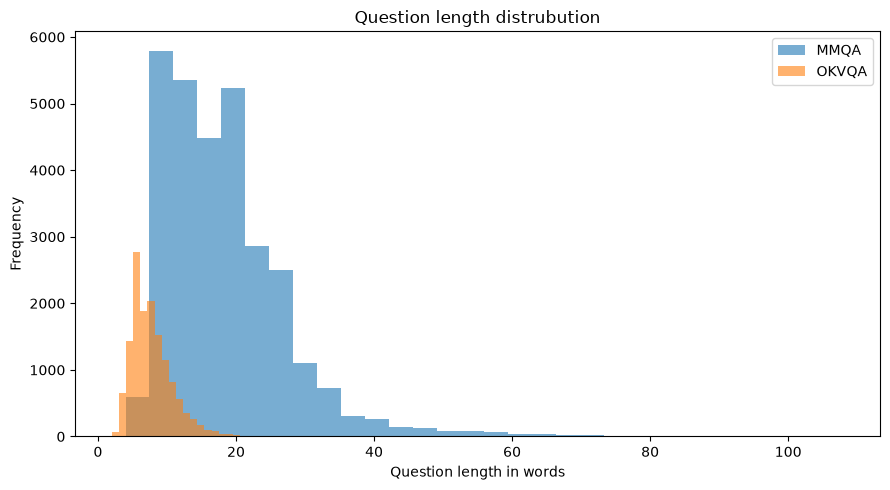

In [19]:
plt.figure(figsize=(9,5))

plt.hist(
    df_mmqa["question_word_count"],
    bins=30,
    alpha=0.6,
    label="MMQA"
)

plt.hist(
    df_okvqa["question_word_count"],
     bins=30,
    alpha=0.6,
    label="OKVQA"
)

plt.title("Question length distrubution")
plt.xlabel("Question length in words")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

### MMQA modality distrubution

,question_count
modality_combination,
text,8205
table,4915
table+text,4069
image+table,3967
image,3929
unknown,3660
image+text,1173


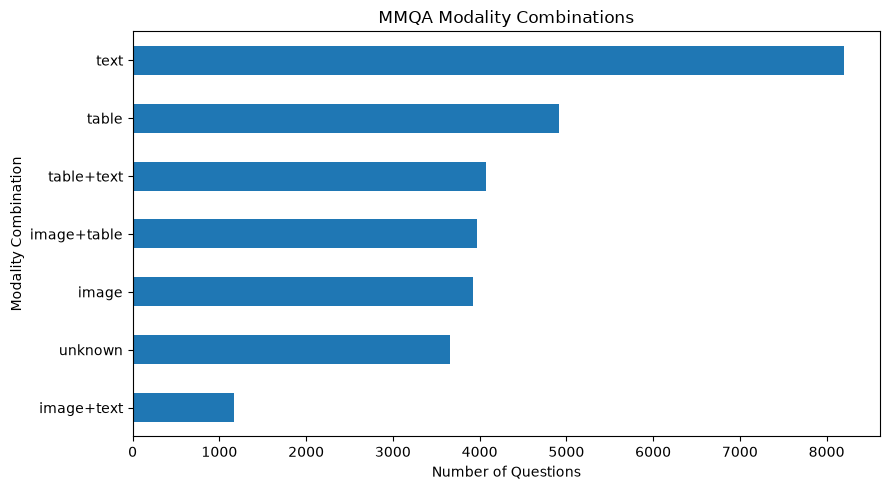

In [20]:
mmqa_modality_counts = (df_mmqa["modality_combination"].value_counts())

display(mmqa_modality_counts.to_frame("question_count"))

plt.figure(figsize=(9, 5))

mmqa_modality_counts.sort_values().plot(
    kind="barh"
)

plt.title("MMQA Modality Combinations")
plt.xlabel("Number of Questions")
plt.ylabel("Modality Combination")
plt.tight_layout()
plt.show()

### OK-VQA answer type distrubution

,question_count
answer_type,
other,14055


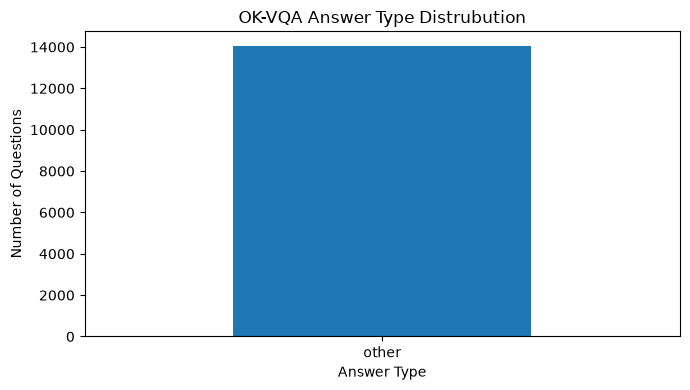

In [21]:
okvqa_answer_type_count = (df_okvqa["answer_type"].value_counts(dropna=False))

display(okvqa_answer_type_count.to_frame("question_count"))

plt.figure(figsize=(7,4))

okvqa_answer_type_count.plot(kind="bar")
plt.title("OK-VQA Answer Type Distrubution")
plt.xlabel("Answer Type")
plt.ylabel("Number of Questions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
print(df_okvqa["answer_type"].unique())
print(df_okvqa["answer_type"].nunique())


<ArrowStringArray>
['other']
Length: 1, dtype: str
1


### OK-VQA answer agreement

,answer_count,unique_answer_count,maximum_answer_agreement
count,14055.00,14055.00,14055.00
mean,10.00,2.94,5.83
std,0.08,1.06,2.14
min,6.00,1.00,2.00
25%,10.00,2.00,4.00
50%,10.00,3.00,6.00
75%,10.00,4.00,8.00
max,10.00,5.00,10.00


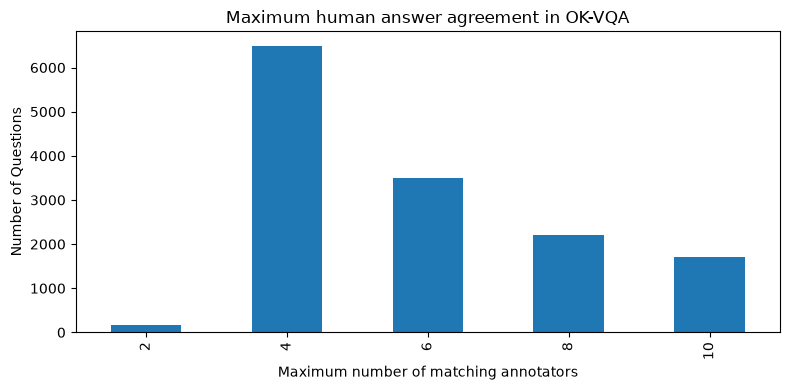

In [23]:
display(df_okvqa[["answer_count", "unique_answer_count", "maximum_answer_agreement",]].describe().round(2))

plt.figure(figsize=(8,4))

df_okvqa["maximum_answer_agreement"].value_counts().sort_index().plot(kind="bar")

plt.title("Maximum human answer agreement in OK-VQA")
plt.xlabel("Maximum number of matching annotators")
plt.ylabel("Number of Questions")
plt.tight_layout()
plt.show()

### Cross dataset summary

In [24]:
dataset_summary = pd.DataFrame({"datset": ["MMQA","OK-VQA"], "Total questions": [len(df_mmqa), len(df_okvqa),], 
                                    "unique_question_ids":[ df_mmqa["question_id"].nunique(), df_okvqa["question_id"].nunique(),],
                                    "mean_question_words": [df_mmqa["question_word_count"].mean(), df_okvqa["question_word_count"].mean(),], 
                                    "median_question_words": [df_mmqa["question_word_count"].median(), df_okvqa["question_word_count"].median(),],  }
                              )

display(dataset_summary.round(2))
                              

,datset,Total questions,unique_question_ids,mean_question_words,median_question_words
0,MMQA,29918,29918,18.17,17.0
1,OK-VQA,14055,14055,8.12,8.0


## Data cleaning and validation 

### Cleaning functions

#### Text is normalized by first removing excess whitespaces
#### get_answer_value extracts answer text from uncleaned reference answers. For example if an answer is " New York " it will remove the white spaces and return 
#### ["New", "York"]
#### preserve_order removes duplicate answers while maintaining the order in which they appear

In [25]:
import re
from itertools import combinations

df_mmqa_clean = df_mmqa.copy(deep=True)
df_okvqa_clean = df_okvqa.copy(deep=True)


def remove_whitespace(val):
    if not isinstance(val, str):
        return val

    return re.sub(r"\s+", " ", val).strip()


def normalize_text(val):
    if not isinstance(val, str):
        return ""

    val = remove_whitespace(val).lower()
    val = re.sub(r"[^\w\s]", "", val)
    val = re.sub(r"\s+", " ", val).strip()

    return val


ANSWER_KEYS = ( "answer","answers","text","value","span","number","date",)


def get_answer_value(val):
    extracted = []

    if val is None:
        return extracted

    
    if isinstance(val, str):
        cleaned = remove_whitespace(val)

        if cleaned:
            extracted.append(cleaned)

        return extracted

    
    if isinstance(val, (int, float, np.integer, np.floating),):
        if not pd.isna(val):
            extracted.append(str(val))

        return extracted

    if isinstance(val, (list, tuple, set)):
        for item in val:
            extracted.extend(get_answer_value(item))

        return extracted

    
    if isinstance(val, dict):
        for key in ANSWER_KEYS:
            if key in val:
                extracted.extend(get_answer_value(val[key]))

        return extracted

    return extracted


def preserve_order(vals):
    seen = set()
    result = []

    for val in vals:
        if val not in seen:
            result.append(val)
            seen.add(val)

    return result

#### The nested loop returns only the records with a valid question id
#### The outer loop, loops through the training, development and test records
#### The inner loop, loops through every record in the current split
#### The question id is retrieved from the original MMQA record
#### get_mmqa_rec retrieves the original MMQA dataset record for every question ID and then converts that ID to a string
#### This string is searched for in the lookup dictionary

In [26]:
# Dictionary that maps each mmqa question id to its original record in the dataset
mmqa_raw_by_id = {}

for split_name, recs in [("train", mmqa_train), ("dev",mmqa_dev),("test",mmqa_test),]:
    for rec in recs:
        question_id = rec.get("qid")
        if question_id is not None:
            mmqa_raw_by_id[str(question_id)] = {"split": split_name, "record": rec, }

def get_mmqa_rec(question_id):
    item = mmqa_raw_by_id.get(str(question_id))

    if item is None:
        return {}

    return item["record"]

# Extract the correct answer from the dataset
def get_mmqa_gold_answers(question_id):
    rec = get_mmqa_rec(question_id)
    answers = []

    for item in rec.get("answers", []):
        if isinstance(item, dict):
            answer = item.get("answer")
        else:
            answer = item

        if isinstance(answer, str):
            answer = remove_whitespace(answer)

            if answer:
                answers.append(answer)

        elif answer is not None:
            answers.append(str(answer))

    return preserve_order(answers)

# Retrieve the supporting context provided for each question in the dataset
def get_mmqa_supporting_context(question_id):
    rec = get_mmqa_rec(question_id)

    contexts = rec.get("supporting_context",[],)

    if not isinstance(contexts,list):
        return []

    return contexts

# Extracts IDs for the supporting context
def get_evidence_id(contexts):
    evidence_ids = []

    for context in contexts:
        if not isinstance(context,dict):
            continue

        evidence_id = (context.get("doc_id") or context.get("document_id") or context.get("id"))

        if evidence_id is not None:
            evidence_ids.append(str(evidence_id))
            
                                
    return preserve_order(evidence_ids)

df_mmqa_clean["gold_answers"] = (df_mmqa_clean["question_id"].apply(get_mmqa_gold_answers))

df_mmqa_clean["supporting_context"] = (df_mmqa_clean["question_id"].apply(get_mmqa_supporting_context))

df_mmqa_clean["gold_evidence_ids"] = (df_mmqa_clean["supporting_context"].apply(get_evidence_id))

df_mmqa_clean["answer_count"] = (df_mmqa_clean["gold_answers"].str.len())

df_mmqa_clean["first_answer"] = (df_mmqa_clean["gold_answers"].apply(lambda answers: (answers [0] if answers else None)))

df_mmqa_clean["first_answer_word_count"] = (df_mmqa_clean["first_answer"] .apply(lambda answer: (len(answer.split()) if isinstance(answer, str) else pd.NA)))

    
    

In [27]:
okvqa_annotations_by_id = {**okvqa_train_annotations_by_id, **okvqa_val_annotations_by_id,}

def get_okvqa_gold_answers(question_id):
    annotation = okvqa_annotations_by_id.get(int(question_id),{},)

    answers = []

    for item in annotation.get("answers", []):
        if not isinstance(item, dict):
            continue

        answer = item.get("answer")

        if isinstance(answer, str):
            answer = remove_whitespace(answer)

            if answer:
                answers.append(answer)

    return answers

df_okvqa_clean["gold_answers"] = (df_okvqa_clean["question_id"].apply(get_okvqa_gold_answers))

df_okvqa_clean["normalized_gold_answers"] = (df_okvqa_clean["gold_answers"].apply(lambda answers: [normalize_text(answer) for answer in answers]))


def most_common_normalized_answer(answers):
    if not answers:
        return None

    return Counter(answers).most_common(1)[0][0]


def maximum_answer_agreement(answers):
    if not answers:
        return 0

    return max(Counter(answers).values())

df_okvqa_clean["answer_count"] = (df_okvqa_clean["gold_answers"].str.len())

df_okvqa_clean["unique_answer_count"] = (df_okvqa_clean["normalized_gold_answers"].apply(lambda answers: len(set(answers))))

df_okvqa_clean["most_common_answer"] = (
    df_okvqa_clean["normalized_gold_answers"]
    .apply(most_common_normalized_answer)
)

df_okvqa_clean["maximum_answer_agreement"] = (df_okvqa_clean["normalized_gold_answers"].apply(maximum_answer_agreement))

In [28]:
for dataframe in [df_mmqa_clean, df_okvqa_clean,]:
    dataframe["question_clean"] = (dataframe["question"].apply(remove_whitespace))
    dataframe["question_normalized"] = (dataframe["question_clean"].str.lower())
    dataframe["question_word_count"] = (dataframe["question_clean"].str.split().str.len())
    dataframe["question_character_count"] = (dataframe["question_clean"].str.len())

    df_mmqa_clean["first_answer_clean"] = (df_mmqa_clean["first_answer"].apply(remove_whitespace))
    df_okvqa_clean["most_common_answer_clean"] = (df_okvqa_clean["most_common_answer"].apply(remove_whitespace))
    
    

In [29]:
mmqa_integer_columns = ["question_word_count", "question_character_count", "answer_count", "first_answer_word_count", "supporting_context_count",]

okvqa_integer_columns = ["question_word_count", "question_character_count", "answer_count", "unique_answer_count","maximum_answer_agreement",]

for column in mmqa_integer_columns:
    df_mmqa_clean[column] = pd.to_numeric(df_mmqa_clean[column], errors="coerce",).astype("Int64")

for column in okvqa_integer_columns:
    df_okvqa_clean[column] = pd.to_numeric(df_okvqa_clean[column],errors="coerce",).astype("Int64")


print("MMQA data types")
display(df_mmqa_clean[mmqa_integer_columns].dtypes.to_frame("data_type"))

print("OK-VQA data types")
display(df_okvqa_clean[okvqa_integer_columns].dtypes.to_frame("data_type"))


MMQA data types


,data_type
question_word_count,Int64
question_character_count,Int64
answer_count,Int64
first_answer_word_count,Int64
supporting_context_count,Int64


OK-VQA data types


,data_type
question_word_count,Int64
question_character_count,Int64
answer_count,Int64
unique_answer_count,Int64
maximum_answer_agreement,Int64


In [30]:
mmqa_unresolved_answers = df_mmqa_clean[df_mmqa_clean["split"].isin(["train", "dev"])& df_mmqa_clean["answer_count"].eq(0)].copy()

print("Rows in MMQA dataset with no answer extracted:",len(mmqa_unresolved_answers),)

display(mmqa_unresolved_answers[["split","question_id","question_clean","question_type",]].head(20))

Rows in MMQA dataset with no answer extracted: 0


,split,question_id,question_clean,question_type


### Validation Summary

In [31]:
validation_summary = pd.DataFrame({"check": ["MMQA blank cleaned questions","OK-VQA blank cleaned questions","MMQA missing question IDs","OK-VQA missing question IDs",
                                             "MMQA duplicate question IDs","OK-VQA duplicate question IDs","OK-VQA duplicate question-image pairs","MMQA labelled rows without answers",
                                             "MMQA labelled rows without question type", "MMQA labelled rows without supporting context", "MMQA labelled rows with empty modalities",
                                             "OK-VQA rows without answers","OK-VQA invalid agreement values",],
        
            
"count": [df_mmqa_clean["question_clean"].eq("").sum(),

df_okvqa_clean["question_clean"].eq("").sum(),

df_mmqa_clean["question_id"].isna().sum(),

df_okvqa_clean["question_id"].isna().sum(),

df_mmqa_clean["question_id"].duplicated().sum(),

df_okvqa_clean["question_id"].duplicated().sum(),

df_okvqa_clean.duplicated(subset=["split","image_id","question_clean"]).sum(),

len(mmqa_unresolved_answers),

(
df_mmqa_clean["split"].isin(["train", "dev"])& df_mmqa_clean["question_type"].isna()).sum(),

(
df_mmqa_clean["split"].isin(["train", "dev"]) & df_mmqa_clean["supporting_context_count"].eq(0)).sum(),

(
df_mmqa_clean["split"].isin(["train", "dev"]) & df_mmqa_clean["modalities"].apply(lambda value: (isinstance(value, list) and len(value) == 0))).sum(),

df_okvqa_clean["answer_count"].eq(0).sum(),

(
df_okvqa_clean["maximum_answer_agreement"]> df_okvqa_clean["answer_count"]).sum(),],})

display(validation_summary)

,check,count
0,MMQA blank cleaned questions,0
1,OK-VQA blank cleaned questions,0
2,MMQA missing question IDs,0
3,OK-VQA missing question IDs,0
4,MMQA duplicate question IDs,0
5,OK-VQA duplicate question IDs,0
6,OK-VQA duplicate question-image pairs,0
7,MMQA labelled rows without answers,0
8,MMQA labelled rows without question type,0
9,MMQA labelled rows without supporting context,0


In [32]:
PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)



MMQA_CLEAN_PATH = (PROCESSED_DIR/ "mmqa_clean.pkl")

OKVQA_CLEAN_PATH = (PROCESSED_DIR/ "okvqa_clean.pkl")


df_mmqa_clean.to_pickle(MMQA_CLEAN_PATH)

df_okvqa_clean.to_pickle(OKVQA_CLEAN_PATH)



df_mmqa_clean.to_json(PROCESSED_DIR / "mmqa_clean.jsonl",orient="records",lines=True,force_ascii=False,)

df_okvqa_clean.to_json(PROCESSED_DIR / "okvqa_clean.jsonl",orient="records",lines=True,force_ascii=False,)


print("Saved:", MMQA_CLEAN_PATH)
print("Saved:", OKVQA_CLEAN_PATH)


Saved: C:\Users\shadi\F21MP\data\processed\mmqa_clean.pkl
Saved: C:\Users\shadi\F21MP\data\processed\okvqa_clean.pkl


In [33]:
print("MMQA cleaned dataset shape:", df_mmqa_clean.shape)
print("OK-VQA cleaned dataset shape:", df_okvqa_clean.shape)

print("\nMMQA cleaned dataset")
display(df_mmqa_clean.head(10))

print("\nOK-VQA cleaned dataset")
display(df_okvqa_clean.head(10))

MMQA cleaned dataset shape: (29918, 20)
OK-VQA cleaned dataset shape: (14055, 18)

MMQA cleaned dataset


,dataset,split,question_id,question,question_type,question_word_count,question_character_count,answer_count,first_answer,first_answer_word_count,modalities,modality_combination,supporting_context_count,parts,gold_answers,supporting_context,gold_evidence_ids,question_clean,question_normalized,first_answer_clean
0,MMQA,train,165d0bb820558b332d126e1ca216dde1,What year was Elizabeth Matory the opponent of...,TableQ,11,76,1,2018,1,[table],table,1,[table],[2018],[{'doc_id': 'dcd7cb8f23737c6f38519c3770a6606f'...,[dcd7cb8f23737c6f38519c3770a6606f],What year was Elizabeth Matory the opponent of...,what year was elizabeth matory the opponent of...,2018
1,MMQA,train,882ad69f9884acaad505b71da382c38e,Cheryl D. Mills (born 1965) is an American law...,TextQ,83,522,1,2008 U.S. election,3,[text],text,2,"[text, text]",[2008 U.S. election],[{'doc_id': 'fe7e67adc0cbf67cc48446bf0c9c6c40'...,"[fe7e67adc0cbf67cc48446bf0c9c6c40, a7d9e6350ba...",Cheryl D. Mills (born 1965) is an American law...,cheryl d. mills (born 1965) is an american law...,2008 U.S. election
2,MMQA,train,ba01e3a25629b726513bd40a487f60c4,Which system has a lower number for Japan of t...,TableQ,21,121,1,MSX (Japan only),3,[table],table,2,"[table, table]",[MSX (Japan only)],[{'doc_id': '463ab34dd309ebc5332532020af3ee40'...,[463ab34dd309ebc5332532020af3ee40],Which system has a lower number for Japan of t...,which system has a lower number for japan of t...,MSX (Japan only)
3,MMQA,train,5963749c73657456d711ce1c477fd392,When did the virtual console system when Japan...,"Compose(TextQ,TableQ)",13,70,1,"March 21, 2001",3,"[table, text]",table+text,2,"[table, text]","[March 21, 2001]",[{'doc_id': '463ab34dd309ebc5332532020af3ee40'...,"[463ab34dd309ebc5332532020af3ee40, d59da1cf02b...",When did the virtual console system when Japan...,when did the virtual console system when japan...,"March 21, 2001"
4,MMQA,train,101d65a1d038d28cc315d47897e0f280,Who is a Japanese video game designer and prod...,TextQ,40,244,1,Shigeru Miyamoto,2,[text],text,2,"[text, text]",[Shigeru Miyamoto],[{'doc_id': '5fc61131a5ba4b6c3acc1571a3923524'...,"[5fc61131a5ba4b6c3acc1571a3923524, 11985560f78...",Who is a Japanese video game designer and prod...,who is a japanese video game designer and prod...,Shigeru Miyamoto
5,MMQA,train,520e9c9b4d8b28eb7cbcda8b5f5f3f99,when was the last nintendo 64 game released,TextQ,8,43,1,"August 20, 2002",3,[text],text,1,[text],"[August 20, 2002]",[{'doc_id': '06eda4122365aabee1395693f583e95a'...,[06eda4122365aabee1395693f583e95a],when was the last nintendo 64 game released,when was the last nintendo 64 game released,"August 20, 2002"
6,MMQA,train,a40b934dd6c397803063de31b42333bf,What was Seamus Conneely's Club in the 2014 Se...,TableQ,9,51,1,Sligo Rovers,2,[table],table,1,[table],[Sligo Rovers],[{'doc_id': '833400d95150002c5a6bab4fc1cfeba7'...,[833400d95150002c5a6bab4fc1cfeba7],What was Seamus Conneely's Club in the 2014 Se...,what was seamus conneely's club in the 2014 se...,Sligo Rovers
7,MMQA,train,9ee46836c510f168aac8e610a4ca1461,do away goals count in league one playoffs,TextQ,8,42,1,no,1,[text],text,1,[text],[no],[{'doc_id': '1a153d0aa005d15f1491ed83f70506ce'...,[1a153d0aa005d15f1491ed83f70506ce],do away goals count in league one playoffs,do away goals count in league one playoffs,no
8,MMQA,train,f9a074072ccb7c87030ebde66317af9e,When did an actor in the live action remake of...,TextQ,18,89,1,2013,1,[text],text,2,"[text, text]",[2013],[{'doc_id': '512da75b267d479ef3bc98cf9505155e'...,"[512da75b267d479ef3bc98cf9505155e, a03cb674241...",When did an actor in the live action remake of...,when did an actor in the live action remake of...,2013
9,MMQA,train,337fc7b4165d5285a7c034c580100879,What club was Gonzalo Higuaín a member of duri...,TableQ,12,68,1,Real Madrid,2,[table],table,1,[table],[Real Madrid],[{'doc_id': '263d424438f6b1954eaa2a10809cb880'...,[263d424438f6b1954eaa2a10809cb880],What club was Gonzalo Higuaín a member of duri...,what club was gonzalo higuaín a member of duri...,Re


OK-VQA cleaned dataset


,dataset,split,question_id,image_id,question,question_word_count,question_character_count,question_type,answer_type,answer_count,unique_answer_count,most_common_answer,maximum_answer_agreement,gold_answers,normalized_gold_answers,most_common_answer_clean,question_clean,question_normalized
0,OK-VQA,train,516065,51606,What is the hairstyle of the blond called?,8,42,four,other,10,3,pony tail,6,"[pony tail, pony tail, pony tail, pony tail, p...","[pony tail, pony tail, pony tail, pony tail, p...",pony tail,What is the hairstyle of the blond called?,what is the hairstyle of the blond called?
1,OK-VQA,train,817215,81721,How old do you have to be in canada to do this?,12,47,seven,other,10,1,18,10,"[18, 18, 18, 18, 18, 18, 18, 18, 18, 18]","[18, 18, 18, 18, 18, 18, 18, 18, 18, 18]",18,How old do you have to be in canada to do this?,how old do you have to be in canada to do this?
2,OK-VQA,train,4802085,480208,Can you guess the place where the man is playing?,10,49,four,other,10,4,mountain,4,"[aspen, aspen, mountain, mountain, mountain, m...","[aspen, aspen, mountain, mountain, mountain, m...",mountain,Can you guess the place where the man is playing?,can you guess the place where the man is playing?
3,OK-VQA,train,5706185,570618,Which rail company is named after a town in ne...,11,55,one,other,10,4,santa fe,4,"[santa fe, santa fe, santa fe, santa fe, new e...","[santa fe, santa fe, santa fe, santa fe, new e...",santa fe,Which rail company is named after a town in ne...,which rail company is named after a town in ne...
4,OK-VQA,train,4789035,478903,Is the boy swimming or doing another water act...,9,52,seven,other,10,4,another activity,4,"[another activity, another activity, another a...","[another activity, another activity, another a...",another activity,Is the boy swimming or doing another water act...,is the boy swimming or doing another water act...
5,OK-VQA,train,5426515,542651,Why do kids stare?,4,18,three,other,10,4,curious,4,"[curious, curious, curious, curious, unusual, ...","[curious, curious, curious, curious, unusual, ...",curious,Why do kids stare?,why do kids stare?
6,OK-VQA,train,250245,25024,When was this piece of sporting equipment inve...,8,51,other,other,10,4,1926,4,"[1926, 1926, 1926, 1926, 1960s, 1960s, 1965, 1...","[1926, 1926, 1926, 1926, 1960s, 1960s, 1965, 1...",1926,When was this piece of sporting equipment inve...,when was this piece of sporting equipment inve...
7,OK-VQA,train,20565,2056,Why is this officer using this mode of transpo...,9,54,other,other,10,4,patrol,4,"[patrol, patrol, patrol, patrol, crowd control...","[patrol, patrol, patrol, patrol, crowd control...",patrol,Why is this officer using this mode of transpo...,why is this officer using this mode of transpo...
8,OK-VQA,train,1795265,179526,Why is this an atypical look for someone weari...,11,61,seven,other,10,3,clown,6,"[clown, clown, clown, clown, clown, clown, sad...","[clown, clown, clown, clown, clown, clown, sad...",clown,Why is this an atypical look for someone weari...,why is this an atypical look for someone weari...
9,OK-VQA,train,3869275,386927,Which american president is most associated wi...,12,78,three,other,10,4,theodore roosevelt,4,"[theodore roosevelt, theodore roosevelt, theod...","[theodore roosevelt, theodore roosevelt, theod...",theodore roosevelt,Which american president is most associated wi...,which american president is most associated wi...


## Text Preprocessing

### Chunking MMQA text corpus

#### Text is split up into smaller chunks which will later be used as relevant evidence
#### The maximum chunk size is set to 180
#### When the chunk size exceeds 180 a 40 token overlap is applied
#### This is where the last 40 words of one chunk appear as the first 40 words in the preceeding chunk


In [34]:
TEXT_CHUNK_SIZE = 180
TEXT_CHUNK_OVERLAP = 40

def chunk_text(txt, chunk_size=TEXT_CHUNK_SIZE, chunk_overlap=TEXT_CHUNK_OVERLAP,):
    if chunk_overlap >= chunk_size:
        raise ValueError("Chunk size must be larger than chunk overlap")

    txt = remove_whitespace(txt)

    if not isinstance(txt, str) or not txt:
        return []

    words = txt.split()

    if len(words) <= chunk_size:
        return [txt]
   
    chunks = []
    step_size = chunk_size - chunk_overlap

    for start in range(0, len(words), step_size):
        chunk_words = words[start:start + chunk_size]

        if not chunk_words:
            break

        
        chunks.append(" ".join(chunk_words))       

        if start + chunk_size >= len(words):
            break

    return chunks

    

#### Assigns a chunk id to each chunk. This later helps identify the chunk when its stored in the vector index

In [35]:
chunk_rows = []

for rec in mmqa_texts:
    doc_id_raw = rec.get("id")

    if doc_id_raw is None:
        continue

    doc_id = str(doc_id_raw).strip()

    txt = rec.get("text","")
    url = rec.get("url")
    title = rec.get("title","")

    txt = (remove_whitespace(txt) if isinstance(txt, str) else "")
    
    title = (remove_whitespace(title) if isinstance(title, str) else "")

    if not doc_id or not txt:
        continue

    chunks = chunk_text(txt)

    for chunk_number, chunk_value in enumerate(chunks):
        chunk_id = f"{doc_id}_text_{chunk_number}"


        txt_embedding = (f"Title: {title}\nText: {chunk_value}" if title else chunk_value)

        chunk_rows.append({"doc_id": doc_id, "chunk_id": chunk_id, "modality": "text", "title": title, "chunk_number": chunk_number, "chunk_text": chunk_value, 
                      "embedding_text": txt_embedding, "word_count": len(chunk_value.split()), "url": url,})

df_chunks_mmqa_txt = pd.DataFrame(chunk_rows)

display(df_chunks_mmqa_txt[["doc_id", "chunk_id", "title", "chunk_number", "chunk_text", "word_count"]].head(10))

    


    

,doc_id,chunk_id,title,chunk_number,chunk_text,word_count
0,9dc9fabf3a930c7b479beb08e83fb1fb,9dc9fabf3a930c7b479beb08e83fb1fb_text_0,Monica Lewinsky,0,"Monica Samille Lewinsky (born July 23, 1973) i...",60
1,a7d9e6350bafc46b700e4d0739a39594,a7d9e6350bafc46b700e4d0739a39594_text_0,Hillaryland,0,Hillaryland was the self-designated name of a ...,45
2,7807d33626dd1f67f843d242919c4560,7807d33626dd1f67f843d242919c4560_text_0,Maya Harris,0,"Maya Lakshmi Harris (born January 30, 1967) is...",146
3,c814391b06ae7cba355daa94c5c255de,c814391b06ae7cba355daa94c5c255de_text_0,Linda Chavez,0,"Linda Lou Chavez (born June 17, 1947) is an Am...",127
4,e20ef41d82c4ae6286915f81807b6a11,e20ef41d82c4ae6286915f81807b6a11_text_0,Debbie Willhite,0,"Debbie Willhite (born December 28, 1951) is an...",66
5,e1e110437ac39d0e03ed090ffff42a87,e1e110437ac39d0e03ed090ffff42a87_text_0,Juleanna Glover,0,Juleanna R. Glover is an American corporate pu...,58
6,5c0d2f87c3c54e7c058099c534ddfeec,5c0d2f87c3c54e7c058099c534ddfeec_text_0,Constance of Austria,0,Constance of Austria (; ; 24 December 1588 – 1...,33
7,24f2d030d000da44d46e02a6a22b02ba,24f2d030d000da44d46e02a6a22b02ba_text_0,Angela Rye,0,"Angela Rye (born October 26, 1979) is an Ameri...",38
8,af63516e81eda6135e0dd9e5ba21e40b,af63516e81eda6135e0dd9e5ba21e40b_text_0,England at the FIFA World Cup,0,England did not enter the competition until 19...,121
9,df12c2fccc233690ec7a1d2d57ef26c5,df12c2fccc233690ec7a1d2d57ef26c5_text_0,Elizabeth of Austria (1526–1545),0,Elizabeth spent most of her childhood in the H...,127


### Show Chunks

In [36]:
text_preprocessing_summary = pd.DataFrame(
    {
        "check": ["Text records", "Processed documents", "Missing document IDs", "Generated chunks", "Duplicate chunk IDs", "Blank chunks", 
                  "Maximum chunk word count",],

        "count": [len(mmqa_texts), df_chunks_mmqa_txt["doc_id"].nunique(), df_chunks_mmqa_txt["doc_id"].isna().sum(), len(df_chunks_mmqa_txt),
                  df_chunks_mmqa_txt["chunk_id"].duplicated().sum(), df_chunks_mmqa_txt["chunk_text"].eq("").sum(), df_chunks_mmqa_txt["word_count"].max(),],
    }
)

display(text_preprocessing_summary)

display(df_chunks_mmqa_txt[["doc_id","chunk_id","title","chunk_number","chunk_text","word_count",]].head(10))

,check,count
0,Text records,218285
1,Processed documents,218285
2,Missing document IDs,0
3,Generated chunks,222192
4,Duplicate chunk IDs,0
5,Blank chunks,0
6,Maximum chunk word count,180


,doc_id,chunk_id,title,chunk_number,chunk_text,word_count
0,9dc9fabf3a930c7b479beb08e83fb1fb,9dc9fabf3a930c7b479beb08e83fb1fb_text_0,Monica Lewinsky,0,"Monica Samille Lewinsky (born July 23, 1973) i...",60
1,a7d9e6350bafc46b700e4d0739a39594,a7d9e6350bafc46b700e4d0739a39594_text_0,Hillaryland,0,Hillaryland was the self-designated name of a ...,45
2,7807d33626dd1f67f843d242919c4560,7807d33626dd1f67f843d242919c4560_text_0,Maya Harris,0,"Maya Lakshmi Harris (born January 30, 1967) is...",146
3,c814391b06ae7cba355daa94c5c255de,c814391b06ae7cba355daa94c5c255de_text_0,Linda Chavez,0,"Linda Lou Chavez (born June 17, 1947) is an Am...",127
4,e20ef41d82c4ae6286915f81807b6a11,e20ef41d82c4ae6286915f81807b6a11_text_0,Debbie Willhite,0,"Debbie Willhite (born December 28, 1951) is an...",66
5,e1e110437ac39d0e03ed090ffff42a87,e1e110437ac39d0e03ed090ffff42a87_text_0,Juleanna Glover,0,Juleanna R. Glover is an American corporate pu...,58
6,5c0d2f87c3c54e7c058099c534ddfeec,5c0d2f87c3c54e7c058099c534ddfeec_text_0,Constance of Austria,0,Constance of Austria (; ; 24 December 1588 – 1...,33
7,24f2d030d000da44d46e02a6a22b02ba,24f2d030d000da44d46e02a6a22b02ba_text_0,Angela Rye,0,"Angela Rye (born October 26, 1979) is an Ameri...",38
8,af63516e81eda6135e0dd9e5ba21e40b,af63516e81eda6135e0dd9e5ba21e40b_text_0,England at the FIFA World Cup,0,England did not enter the competition until 19...,121
9,df12c2fccc233690ec7a1d2d57ef26c5,df12c2fccc233690ec7a1d2d57ef26c5_text_0,Elizabeth of Austria (1526–1545),0,Elizabeth spent most of her childhood in the H...,127


In [37]:
MMQA_TEXT_CHUNKS_PATH = (PROCESSED_DIR/ "mmqa_text_chunks.pkl")

df_chunks_mmqa_txt.to_pickle(MMQA_TEXT_CHUNKS_PATH)

df_chunks_mmqa_txt.to_json(PROCESSED_DIR / "mmqa_text_chunks.jsonl", orient="records", lines=True, force_ascii=False,)

print("Saved preprocessed text:", MMQA_TEXT_CHUNKS_PATH,)

Saved preprocessed text: C:\Users\shadi\F21MP\data\processed\mmqa_text_chunks.pkl


## Table Preprocessing

### Helper Functions

#### The text from each table is extracted
#### This text is chunked in the same way as described in the text preprocessing stage

In [38]:
TABLE_CHUNK_MAX_WORDS = 180
TABLE_ROW_OVERLAP = 1

def clean_values(val):
    if val is None:
        return ""

    return remove_whitespace(str(val))


def get_table_text(table_cell):
    if isinstance(table_cell, dict):
        val = table_cell.get("text", "")
    else:
        val = table_cell

    return clean_values(val)

def extract_column_names(header, max_cols):
    column_names = []

    if isinstance(header, list):
        for col_idx, col in enumerate(header):
            if isinstance(col, dict):
                column_name = col.get("column_name", "")
            else:
                column_name = col
            column_name = clean_values(column_name)

            if not column_name:
                column_name = f"Column {col_idx}"

            column_names.append(column_name)

    while len(column_names) < max_cols:
        column_names.append(f"Column {len(column_names)}")

    return column_names
    

#### Table rows are encoded as follows: 
#### Row index: column name: cell value | column name: cell value| 

In [39]:
# Converts each table row into text
def encode_rows(row, column_names, row_idx):
    if not isinstance(row, list):
        return ""

    vals = [get_table_text(cell) for cell in row]

    cell_pairs = []
    
    #Loop through each cell and map the cell to its column name
    for column_idx, val in enumerate(vals):
        if not val:
            continue

        if column_idx < len(column_names):
            column_name = column_names[column_idx]
        else:
            column_name = f"Column {column_idx}"

        cell_pairs.append(f"{column_name}: {val}")

    if not cell_pairs:
        return ""

    return f"Row index {row_idx}: " + " | ".join(cell_pairs)

# Ensure no text row in the table exceeds the chunk limit
def split_large_rows(encoded_rows,pref,max_words=TABLE_CHUNK_MAX_WORDS,):
    pref_word_count = len(pref.split()) if pref else 0
    words_available = max_words - pref_word_count

    if words_available <= 0:
        raise ValueError("Table prefix exceeds chunk limit.")

    split_rows = []

    for row_idx, row_text in encoded_rows:
        original_label = f"Row index {row_idx}:"

        if row_text.startswith(original_label):
            row_content = row_text[len(original_label):].strip()
        else:
            row_content = row_text

        content_words = row_content.split()

        normal_label = f"Row index {row_idx}:"
        normal_content_limit = (words_available - len(normal_label.split()))

        if len(content_words) <= normal_content_limit:
            split_rows.append((row_idx, f"{normal_label} {row_content}",))
            continue

        start = 0
        part_number = 0

        while start < len(content_words):
            part_label = (f"Row index {row_idx}, part {part_number}:")

            part_content_limit = (words_available - len(part_label.split()))

            if part_content_limit <= 0:
                raise ValueError("Not enough space for the table row label.")

            part_words = content_words[start:start + part_content_limit]

            split_rows.append((row_idx, f"{part_label} {' '.join(part_words)}",))

            start += part_content_limit
            part_number += 1

    return split_rows

# The rows converted to text is chunked 
def chunk_rows_table(encoded_rows, pref, max_words=TABLE_CHUNK_MAX_WORDS,overlap_rows=TABLE_ROW_OVERLAP,):
    if max_words <= 0:
        raise ValueError("max_words must be greater than zero")

    if overlap_rows < 0:
        raise ValueError("overlap_rows must be >=0")

    row_chunks = []
    start = 0

    while start < len(encoded_rows):
        # Each new row is temporarily added to current_row
        current_rows = []
        end = start

        while end < len(encoded_rows):
            temp_rows = current_rows + [encoded_rows[end]]

            temp_body = "\n".join(row_text for _, row_text in temp_rows)

            temp_text = (f"{pref}\n{temp_body}" if pref else temp_body)

            if (current_rows and len(temp_text.split()) > max_words):
                break

            current_rows = temp_rows
            end += 1

            if len(temp_text.split()) >= max_words:
                break

        if not current_rows:
            current_rows = [encoded_rows[start]]
            end = start + 1

        row_chunks.append(current_rows)

        if end >= len(encoded_rows):
            break

        start = max(start + 1, end - overlap_rows)

    return row_chunks

### Process tables

#### An empty list table_chunk_rows is created to store the final table chunks
#### Loop through every table and extract title name, url, header and rows
#### Encode each row in this format : Row index 0: Column name: value | Column name: value
#### split rows that exceed the chunk limit
#### Group the encoded rows into chunks

In [40]:
table_chunk_rows = []

tables_with_unusable_rows = 0
missing_doc_ids = 0

for rec in mmqa_tables:
    doc_id_raw = rec.get("id")

    if doc_id_raw is None:
        missing_doc_ids += 1
        continue

    doc_id = str(doc_id_raw).strip()

    if not doc_id:
        missing_doc_ids += 1
        continue
    
    table_object = rec.get("table", {})
    title = clean_values(rec.get("title", ""))
    url = rec.get("url")


    if not isinstance(table_object, dict):
        tables_with_unusable_rows += 1
        continue

    table_name = clean_values(table_object.get("table_name", ""))

    header = table_object.get("header", [])

    raw_rows = table_object.get("table_rows", [])
    

    if not isinstance(raw_rows, list) or not raw_rows:
        tables_with_unusable_rows += 1
        continue

    maximum_columns = max((len(row) for row in raw_rows if isinstance(row, list)), default=0,)

    column_names = extract_column_names(header, maximum_columns,)

    encoded_rows = []

    for row_idx, row in enumerate(raw_rows):
        row_text = encode_rows(row, column_names, row_idx,)

        
        if row_text:
            encoded_rows.append((row_idx, row_text))

    if not encoded_rows:
        tables_with_unusable_rows+=1
        continue
        
    
    prefix_parts = []

    if title:
        prefix_parts.append(f"Page title: {title}")

    if table_name:
        prefix_parts.append(f"Table name: {table_name}")
        

    table_prefix = "\n".join(prefix_parts)

    encoded_rows = split_large_rows(encoded_rows=encoded_rows,pref=table_prefix,)

    row_chunks = chunk_rows_table(encoded_rows=encoded_rows,pref=table_prefix,)

    for chunk_number, row_selected in enumerate(row_chunks):
        row_indices = [row_idx for row_idx, _ in row_selected]

        rows_text = "\n".join(row_text for _, row_text in row_selected)

        embedding_text = (f"{table_prefix}\n{rows_text}" if table_prefix else rows_text)

        chunk_id = (f"{doc_id}_table_{chunk_number}")

        table_chunk_rows.append(
            {"doc_id": doc_id, "chunk_id": chunk_id, "modality": "table", "title": title, "table_name": table_name, "chunk_number": chunk_number, "row_indices": row_indices, 
             "row_start_index": row_indices[0], "row_end_index": row_indices[-1], "chunk_text": rows_text, "embedding_text": embedding_text, "word_count": len(rows_text.split()),
             "embedding_word_count": len(embedding_text.split()), "column_count": len(column_names), "total_table_rows": len(raw_rows), "url": url,
            }
        )

df_chunks_mmqa_table = pd.DataFrame(table_chunk_rows)

print("Table chunks:", len(df_chunks_mmqa_table))        
        
        
        

Table chunks: 33563


In [41]:
display(df_chunks_mmqa_table[["doc_id", "chunk_id", "title", "table_name", "chunk_number", "row_indices", "chunk_text", "embedding_word_count",]].head(10))


table_preprocessing_summary = pd.DataFrame({
        "check": ["Table records", "Processed table documents", "Missing table document IDs", "Tables without usable rows", "Generated table chunks", "Duplicate table chunk IDs", 
                  "Blank table chunks", "Chunks above word target", "Maximum embedding word count",],

        "count": [len(mmqa_tables), df_chunks_mmqa_table["doc_id"].nunique(), missing_doc_ids, tables_with_unusable_rows, len(df_chunks_mmqa_table), 
                  df_chunks_mmqa_table["chunk_id"].duplicated().sum(), df_chunks_mmqa_table["chunk_text"].eq("").sum(), 
                  (df_chunks_mmqa_table["embedding_word_count"]> TABLE_CHUNK_MAX_WORDS).sum(), df_chunks_mmqa_table["embedding_word_count"].max(),],})
                  

display(table_preprocessing_summary)

,doc_id,chunk_id,title,table_name,chunk_number,row_indices,chunk_text,embedding_word_count
0,dcd7cb8f23737c6f38519c3770a6606f,dcd7cb8f23737c6f38519c3770a6606f_table_0,Dutch Ruppersberger,Electoral history,0,"[0, 1, 2, 3]",Row index 0: Year: 1994 | Office: Baltimore Co...,155
1,dcd7cb8f23737c6f38519c3770a6606f,dcd7cb8f23737c6f38519c3770a6606f_table_1,Dutch Ruppersberger,Electoral history,1,"[3, 4, 5, 6, 7]",Row index 3: Year: 2004 | Election: General | ...,180
2,dcd7cb8f23737c6f38519c3770a6606f,dcd7cb8f23737c6f38519c3770a6606f_table_2,Dutch Ruppersberger,Electoral history,2,"[7, 8, 9, 10]",Row index 7: Year: 2012 | Election: General | ...,146
3,463ab34dd309ebc5332532020af3ee40,463ab34dd309ebc5332532020af3ee40_table_0,Virtual Console,Titles,0,"[0, 1, 2, 3, 4]",Row index 0: System: NES/Famicom | Japan: 148 ...,178
4,463ab34dd309ebc5332532020af3ee40,463ab34dd309ebc5332532020af3ee40_table_1,Virtual Console,Titles,1,"[4, 5, 6, 7]",Row index 4: System: MSX (Japan only) | Japan:...,144
5,833400d95150002c5a6bab4fc1cfeba7,833400d95150002c5a6bab4fc1cfeba7_table_0,Seamus Conneely,Career statistics | Club statistics,0,"[0, 1]",Row index 0: Club: Sheffield United | Season: ...,170
6,833400d95150002c5a6bab4fc1cfeba7,833400d95150002c5a6bab4fc1cfeba7_table_1,Seamus Conneely,Career statistics | Club statistics,1,"[1, 2]",Row index 1: Club: Alfreton Town (loan) | Seas...,176
7,833400d95150002c5a6bab4fc1cfeba7,833400d95150002c5a6bab4fc1cfeba7_table_2,Seamus Conneely,Career statistics | Club statistics,2,[2],Row index 2: Club: Sligo Rovers | Season: 2012...,96
8,833400d95150002c5a6bab4fc1cfeba7,833400d95150002c5a6bab4fc1cfeba7_table_3,Seamus Conneely,Career statistics | Club statistics,3,[3],Row index 3: Club: Sligo Rovers | Season: 2013...,101
9,833400d95150002c5a6bab4fc1cfeba7,833400d95150002c5a6bab4fc1cfeba7_table_4,Seamus Conneely,Career statistics | Club statistics,4,"[4, 5]",Row index 4: Club: Sligo Rovers | Season: 2014...,174


,check,count
0,Table records,10042
1,Processed table documents,10042
2,Missing table document IDs,0
3,Tables without usable rows,0
4,Generated table chunks,33563
5,Duplicate table chunk IDs,0
6,Blank table chunks,0
7,Chunks above word target,0
8,Maximum embedding word count,180


In [42]:
MMQA_TABLE_CHUNKS_PATH = (PROCESSED_DIR / "mmqa_table_chunks.pkl")

df_chunks_mmqa_table.to_pickle(MMQA_TABLE_CHUNKS_PATH)

df_chunks_mmqa_table.to_json(PROCESSED_DIR / "mmqa_table_chunks.jsonl", orient="records", lines=True, force_ascii=False,)

print("Saved preprocessed tables:", MMQA_TABLE_CHUNKS_PATH,)

Saved preprocessed tables: C:\Users\shadi\F21MP\data\processed\mmqa_table_chunks.pkl


In [43]:
oversized_chunks = df_chunks_mmqa_table[
    df_chunks_mmqa_table["embedding_word_count"] > TABLE_CHUNK_MAX_WORDS
]
display(
    oversized_chunks[
        [
            "doc_id",
            "chunk_id",
            "title",
            "table_name",
            "chunk_number",
            "row_indices",
            "embedding_word_count",
            "chunk_text",
        ]
    ].sort_values(
        "embedding_word_count",
        ascending=False,
    ).head(20)
)

,doc_id,chunk_id,title,table_name,chunk_number,row_indices,embedding_word_count,chunk_text


## Image Preprocessing

In [44]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from PIL import Image, UnidentifiedImageError


MMQA_IMAGE_FILES_DIR = (PROJECT_ROOT / "data" / "raw" / "mmqa" / "images")

OKVQA_IMAGE_FILES_DIR = (PROJECT_ROOT / "data" / "raw" / "okvqa" / "images")

OKVQA_TRAIN_IMAGES_DIR = (OKVQA_IMAGE_FILES_DIR / "train2014")

OKVQA_VAL_IMAGES_DIR = (OKVQA_IMAGE_FILES_DIR/ "val2014")


IMAGE_EXTENSIONS = {".jpg",".jpeg",".png",".webp",}


mmqa_image_files = [path for path in MMQA_IMAGE_FILES_DIR.rglob("*") if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS]


okvqa_train_image_files = list(OKVQA_TRAIN_IMAGES_DIR.glob("COCO_train2014_*.jpg"))

okvqa_val_image_files = list(OKVQA_VAL_IMAGES_DIR.glob("COCO_val2014_*.jpg"))


print("MMQA image files found:", len(mmqa_image_files),)

print("OK-VQA training image files found:", len(okvqa_train_image_files),)

print("OK-VQA validation image files found:", len(okvqa_val_image_files),)

MMQA image files found: 57041
OK-VQA training image files found: 82783
OK-VQA validation image files found: 40504


### Image path helper functions

In [111]:
# Cleans an image related value and converts it into a string
def clean_val_image(val):
    if val is None:
        return ""

    return remove_whitespace(str(val))

# Dictionary used to find image files
mmqa_file_lookup = {}

# Loop through image files
for path in mmqa_image_files:
    file_key = path.name.casefold()

    #Store file path under its file name
    mmqa_file_lookup.setdefault(file_key, [],).append(path)

# Matches an image path from MMQA to an image file
def fix_image_path(metadata_path):
    metadata_path = clean_val_image(metadata_path)

    if not metadata_path:
        return None

    file_key = Path(metadata_path).name.casefold()

    filename_matches = mmqa_file_lookup.get(file_key,[],)

    if len(filename_matches) == 1:
        return filename_matches[0]

    return None

def get_image_path_okvqa(split,image_id,):
    if pd.isna(image_id):
        return None

    image_id = int(image_id)
    split = str(split).lower().strip()

    if split == "train":
        folder_path = (OKVQA_TRAIN_IMAGES_DIR)
        folder_name = "train2014"

    elif split in {"validation", "val", "dev",}:
        folder_path = (OKVQA_VAL_IMAGES_DIR)
        folder_name = "val2014"

    else:
        return None

    filename = (f"COCO_{folder_name}_"f"{image_id:012d}.jpg")

    path = folder_path / filename

    if path.is_file():
        return path

    return None

### Image manifest for MMQA

In [112]:
mmqa_image_rows = [] # Stores image records 
missing_mmqa_doc_ids = 0 # Counts images that dont have a document id

# Loop through every image record
for rec in mmqa_images:
    doc_id_raw = rec.get("id")

    if doc_id_raw is None:
        missing_mmqa_doc_ids += 1 # Retrieve image doc id
        continue

    doc_id = str(doc_id_raw).strip()

    if not doc_id:
        missing_mmqa_doc_ids += 1
        continue


    # Extract image metadata
    url = rec.get("url")
    metadata_path = clean_val_image(rec.get("path", ""))
    title = clean_val_image(rec.get("title", ""))
    fixed_path = (fix_image_path(metadata_path)) # finda the image file

    mmqa_image_rows.append(
        {"dataset": "MMQA", "doc_id": doc_id, "chunk_id": (f"{doc_id}_image_0"), "modality": "image","title": title, "chunk_number": 0, "chunk_text": title, 
         "embedding_text": (f"Title: {title}" if title else ""),
            "metadata_path": metadata_path, "image_path": (str(fixed_path) if fixed_path else None), "file_name": (fixed_path.name if fixed_path else None), "url": url,}
    )

df_mmqa_images = pd.DataFrame(mmqa_image_rows)
print(len(df_mmqa_images))
    



57058


### Image manifest for OK-VQA

In [113]:
okvqa_images_needed = (df_okvqa_clean[["split", "image_id"]].dropna(subset=["image_id"]).drop_duplicates().copy())

okvqa_images_needed["image_id"] = (okvqa_images_needed["image_id"].astype(int))

okvqa_question_counts = (df_okvqa_clean.groupby(["split", "image_id"]).size().to_dict())

okvqa_image_rows = []


for row in (okvqa_images_needed.itertuples(index=False)):
    image_id = int(row.image_id)
    split = str(row.split)
    fixed_path = (get_image_path_okvqa(split,image_id,))
    doc_id = (f"okvqa_{split}_{image_id}")

    okvqa_image_rows.append({"dataset": "OK-VQA", "split": split, "image_id": image_id, "doc_id": doc_id,"chunk_id": (f"{doc_id}_image_0"), "modality": "image", "chunk_number": 0, 
                             "image_path": (str(fixed_path) if fixed_path else None), "file_name": (fixed_path.name if fixed_path else None), 
                             "question_count": okvqa_question_counts.get((split, image_id), 0,),})

df_okvqa_images = pd.DataFrame(okvqa_image_rows)

okvqa_path_lookup = {(row.split, int(row.image_id),): row.image_path for row in (df_okvqa_images.itertuples(index=False))}

df_okvqa_clean["image_path"] = [(okvqa_path_lookup.get((str(split), int(image_id),)) if pd.notna(image_id) else None) 
                                for split, image_id in zip(df_okvqa_clean["split"], df_okvqa_clean["image_id"],)]

print("OK-VQA images needed", len(df_okvqa_images),)





OK-VQA images needed 14031


### Image property extraction and file handling

#### Extracts properties frrom the image namely, width height and aspect ratio
#### aspect ratio = width / height

In [114]:
def inspect_image_file(image_path_val,):
    result = {"is_valid": False, "width": pd.NA, "height": pd.NA, "aspect_ratio": np.nan, "image_mode": None, "image_format": None, "file_size_bytes": pd.NA, "image_error": None,}

    if (image_path_val is None or pd.isna(image_path_val) or str(image_path_val).strip() == ""):
        result["image_error"] = "Image path not matched."
        return result

    image_path = Path(str(image_path_val))

    if not image_path.is_file():
        result["image_error"] = ("Image file does not exist.")

        return result

    try:
        
        with Image.open(image_path) as image: 
            width, height = image.size

            result["width"]=width
            result["height"] = height

            result["aspect_ratio"] = (width / height if height else np.nan)

            result["image_mode"] = (image.mode)

            result["image_format"] = (image.format)

            image.verify()

            result["file_size_bytes"] = (image_path.stat().st_size)

            result["is_valid"] = True

    except (UnidentifiedImageError, OSError, ValueError,) as error:
        result["image_error"] = str(error)

    return result


def add_image_properties(dataframe, column="image_path",max_inspections=8,):
    
    image_paths = (dataframe[column].tolist())

    with ThreadPoolExecutor(max_workers=max_inspections) as executor: 
             properties = list(executor.map(inspect_image_file, image_paths,))


    properties_df = pd.DataFrame(properties)

    result = pd.concat([dataframe.reset_index(drop=True), properties_df,], axis=1,)

    result["height"] = pd.to_numeric(result["height"], errors="coerce",).astype("Int64")

    result["width"] = pd.to_numeric(result["width"],errors="coerce",).astype("Int64")
        
    result["file_size_bytes"] = pd.to_numeric(result["file_size_bytes"],errors="coerce").astype("Int64")

    return result
        
            

In [115]:
df_mmqa_images = add_image_properties(df_mmqa_images)

df_okvqa_images = add_image_properties(df_okvqa_images)


C:\Users\shadi\F21MP\.venv\Lib\site-packages\PIL\Image.py:3578: DecompressionBombWarning: Image size (129967200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [116]:
mmqa_image_summary = pd.DataFrame(
    {"check": ["MMQA metadata records", "MMQA actual files discovered", "MMQA processed image documents", "MMQA missing document IDs", "MMQA unmatched image paths", 
               "MMQA duplicate document IDs", "MMQA duplicate chunk IDs", "MMQA unreadable image files", "MMQA non-RGB images",],
        
     "count": [len(mmqa_images), len(mmqa_image_files), df_mmqa_images["doc_id"].nunique(), missing_mmqa_doc_ids, df_mmqa_images["image_path"].isna().sum(), 
               df_mmqa_images["doc_id"].duplicated().sum(), df_mmqa_images["chunk_id"].duplicated().sum(), (df_mmqa_images["image_path"].notna()& ~df_mmqa_images["is_valid"]).sum(), 
               (df_mmqa_images["is_valid"] & df_mmqa_images["image_mode"].notna() & df_mmqa_images["image_mode"].ne("RGB")).sum(),],})


okvqa_image_summary = pd.DataFrame(
    {"check": ["OK-VQA question rows", "OK-VQA unique images required","OK-VQA matched image paths", "OK-VQA question rows without image paths","OK-VQA duplicate image keys",
               "OK-VQA unreadable required images","OK-VQA non-RGB images",], 
     
     "count": [len(df_okvqa_clean), len(df_okvqa_images), df_okvqa_images["image_path"].notna().sum(), df_okvqa_clean["image_path"].isna().sum(), 
               df_okvqa_images.duplicated(subset=["split","image_id",]).sum(), (df_okvqa_images["image_path"].notna() & ~df_okvqa_images["is_valid"]).sum(), 
               (df_okvqa_images["is_valid"] & df_okvqa_images["image_mode"].notna() & df_okvqa_images["image_mode"].ne("RGB")).sum(),],})


print("MMQA image summary")
display(mmqa_image_summary)

print("OK-VQA image summary")
display(okvqa_image_summary)

MMQA image summary


,check,count
0,MMQA metadata records,57058
1,MMQA actual files discovered,57041
2,MMQA processed image documents,57058
3,MMQA missing document IDs,0
4,MMQA unmatched image paths,21
5,MMQA duplicate document IDs,0
6,MMQA duplicate chunk IDs,0
7,MMQA unreadable image files,6
8,MMQA non-RGB images,12676


OK-VQA image summary


,check,count
0,OK-VQA question rows,14055
1,OK-VQA unique images required,14031
2,OK-VQA matched image paths,14031
3,OK-VQA question rows without image paths,0
4,OK-VQA duplicate image keys,0
5,OK-VQA unreadable required images,0
6,OK-VQA non-RGB images,24


In [118]:
display(df_mmqa_images[["doc_id", "chunk_id", "title", "image_path", "width", "height", "image_mode", "is_valid",]].head(10))

display(df_okvqa_images[["split","image_id", "image_path", "question_count", "width", "height", "image_mode","is_valid",]].head(10))

,doc_id,chunk_id,title,image_path,width,height,image_mode,is_valid
0,35b31d9b4f723f806fd32662ef29edf7,35b31d9b4f723f806fd32662ef29edf7_image_0,Republican Party (United States),C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,227,227,RGBA,True
1,d9596e306ec297784b87c0321bb9bedf,d9596e306ec297784b87c0321bb9bedf_image_0,Pat McDonough,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,229,227,RGB,True
2,6f6767c28cf2de8a701cb866e3a3e190,6f6767c28cf2de8a701cb866e3a3e190_image_0,Helen Delich Bentley,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,570,768,RGB,True
3,82fc3d787bf62019be2f1f10d69bc170,82fc3d787bf62019be2f1f10d69bc170_image_0,Nancy Jacobs,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,961,1076,RGB,True
4,66b4d9213088ab9ce0d7a55655ee7c98,66b4d9213088ab9ce0d7a55655ee7c98_image_0,Democratic Party (United States),C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,86,86,RGBA,True
5,85a99525aa24b266108b41a22bf1e21c,85a99525aa24b266108b41a22bf1e21c_image_0,Nintendo 64,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,329,304,RGBA,True
6,991237d4689fa65507e9528a1fab7de3,991237d4689fa65507e9528a1fab7de3_image_0,Nintendo Entertainment System,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,144,56,RGBA,True
7,d0afb847767ec5dd543e5949d8076a79,d0afb847767ec5dd543e5949d8076a79_image_0,Super Nintendo Entertainment System,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,798,102,RGBA,True
8,10a5de119a0fba62426de295ebe9e12b,10a5de119a0fba62426de295ebe9e12b_image_0,Nintendo DS,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,751,116,RGBA,True
9,dc80ff16b65023c74711518f4a46a732,dc80ff16b65023c74711518f4a46a732_image_0,TurboGrafx-16,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,433,230,P,True


,split,image_id,image_path,question_count,width,height,image_mode,is_valid
0,train,51606,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,479,RGB,True
1,train,81721,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,428,RGB,True
2,train,480208,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,500,333,RGB,True
3,train,570618,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,301,RGB,True
4,train,478903,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,458,RGB,True
5,train,542651,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,491,RGB,True
6,train,25024,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,427,RGB,True
7,train,2056,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,425,RGB,True
8,train,179526,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,580,580,RGB,True
9,train,386927,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,1,640,425,RGB,True


In [119]:
df_mmqa_images_valid = df_mmqa_images[df_mmqa_images["is_valid"]].copy()

print("Original MMQA image records:", len(df_mmqa_images))
print("Excluded MMQA image records:", (~df_mmqa_images["is_valid"]).sum())
print("Valid MMQA image records:", len(df_mmqa_images_valid))

Original MMQA image records: 57058
Excluded MMQA image records: 27
Valid MMQA image records: 57031


In [120]:
MMQA_IMAGE_MANIFEST_PATH = (PROCESSED_DIR / "mmqa_image_manifest.pkl")

OKVQA_IMAGE_MANIFEST_PATH = (PROCESSED_DIR / "okvqa_image_manifest.pkl")

MMQA_VALID_IMAGE_MANIFEST_PATH = (PROCESSED_DIR / "mmqa_valid_image_manifest.pkl")

df_mmqa_images_valid.to_pickle(MMQA_VALID_IMAGE_MANIFEST_PATH)

df_mmqa_images_valid.to_json(PROCESSED_DIR / "mmqa_valid_image_manifest.jsonl", orient="records",lines=True,force_ascii=False,)

df_mmqa_images.to_pickle(MMQA_IMAGE_MANIFEST_PATH)

df_mmqa_images.to_json(PROCESSED_DIR / "mmqa_image_manifest.jsonl", orient="records", lines=True, force_ascii=False,)


df_okvqa_images.to_pickle(OKVQA_IMAGE_MANIFEST_PATH)

df_okvqa_images.to_json(PROCESSED_DIR / "okvqa_image_manifest.jsonl", orient="records", lines=True, force_ascii=False,)


df_okvqa_clean.to_pickle(OKVQA_CLEAN_PATH)

df_okvqa_clean.to_json(PROCESSED_DIR / "okvqa_clean.jsonl", orient="records", lines=True, force_ascii=False,)


print(MMQA_IMAGE_MANIFEST_PATH)
print(MMQA_VALID_IMAGE_MANIFEST_PATH)
print(OKVQA_IMAGE_MANIFEST_PATH)

C:\Users\shadi\F21MP\data\processed\mmqa_image_manifest.pkl
C:\Users\shadi\F21MP\data\processed\mmqa_valid_image_manifest.pkl
C:\Users\shadi\F21MP\data\processed\okvqa_image_manifest.pkl


In [125]:
%pip install scikit-learn

  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -------------------------- ------------- 5.5/8.2 MB 29.3 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 22.4 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   -------- ------------------------------- 7.3/36.6 MB 35.0 MB/s eta 0:00:01
   ---------------- ----------------------- 14.7/36.6 MB 35.0 MB/s eta 0:00:01
   ------------------------ --------------- 22.3/36.6 MB 35.8 MB/s eta 0:00:01
   ------------------------------- -------- 28.6/36.6 MB 33.8 MB/s eta 0:00:01
   ------------------------------------- -- 34.6/36.6 MB 33.0 MB/s eta 0:00:01
   ---------------------------------------- 36.6/36.6 MB 29.2 MB/s  0:00:01
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)

   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]


## Development sample selection

In [126]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
MMQA_DEVELOPMENT_SAMPLE_SIZE = 500
OKVQA_DEVELOPMENT_SAMPLE_SIZE = 500


mmqa_training_sample = (df_mmqa_clean[df_mmqa_clean["split"].eq("train")].copy())

okvqa_training_sample = (df_okvqa_clean[df_okvqa_clean["split"].eq("train")].copy())


print("MMQA training questions:", len(mmqa_training_sample))
print("OK-VQA training questions:", len(okvqa_training_sample))

MMQA training questions: 23817
OK-VQA training questions: 9009


In [129]:
df_mmqa_development_sample, df_mmqa_training_remaining = (train_test_split(mmqa_training_sample, train_size=MMQA_DEVELOPMENT_SAMPLE_SIZE, random_state=RANDOM_SEED, 
                                                                           stratify=mmqa_training_sample["modality_combination"],))


df_mmqa_development_sample = (df_mmqa_development_sample.reset_index(drop=True))

df_mmqa_training_remaining = (df_mmqa_training_remaining.reset_index(drop=True))


print("MMQA development sample:", len(df_mmqa_development_sample),)
print("MMQA training questions remaining:",len(df_mmqa_training_remaining),)

MMQA development sample: 500
MMQA training questions remaining: 23317


In [134]:
df_okvqa_development_sample, df_okvqa_training_remaining = (train_test_split(okvqa_training_sample, train_size=OKVQA_DEVELOPMENT_SAMPLE_SIZE, random_state=RANDOM_SEED,
                                                                             stratify=okvqa_training_sample["question_type"],))

df_okvqa_development_sample = (df_okvqa_development_sample.reset_index(drop=True))


df_okvqa_training_remaining = (df_okvqa_training_remaining.reset_index(drop=True))

print("OK-VQA development sample:",len(df_okvqa_development_sample),)
print("OK-VQA training questions remaining:",len(df_okvqa_training_remaining),)

OK-VQA development sample: 500
OK-VQA training questions remaining: 8509


In [139]:
UNIFIED_EVIDENCE_COLUMNS = ["dataset","evidence_id","doc_id","chunk_id","modality","embedding_input_type", "title", "source_name","chunk_number", "content", 
                            "embedding_text", "image_path", "url",]


df_mmqa_text_evidence = df_chunks_mmqa_txt.copy()

df_mmqa_text_evidence["dataset"] = "MMQA"

df_mmqa_text_evidence["evidence_id"] = ("MMQA::" + df_mmqa_text_evidence["chunk_id"].astype(str))

df_mmqa_text_evidence["embedding_input_type"] = "text"

df_mmqa_text_evidence["source_name"] = pd.NA

df_mmqa_text_evidence["content"] = (df_mmqa_text_evidence["chunk_text"])

df_mmqa_text_evidence["image_path"] = pd.NA

df_mmqa_text_evidence = df_mmqa_text_evidence[UNIFIED_EVIDENCE_COLUMNS].copy()


df_mmqa_table_evidence = df_chunks_mmqa_table.copy()

df_mmqa_table_evidence["dataset"] = "MMQA"

df_mmqa_table_evidence["evidence_id"] = ("MMQA::" + df_mmqa_table_evidence["chunk_id"].astype(str))

df_mmqa_table_evidence["embedding_input_type"] = "text"

df_mmqa_table_evidence["source_name"] = (df_mmqa_table_evidence["table_name"])

df_mmqa_table_evidence["content"] = (df_mmqa_table_evidence["chunk_text"])

df_mmqa_table_evidence["image_path"] = pd.NA

df_mmqa_table_evidence = df_mmqa_table_evidence[UNIFIED_EVIDENCE_COLUMNS].copy()

df_mmqa_image_evidence = df_mmqa_images_valid.copy()

df_mmqa_image_evidence["dataset"] = "MMQA"

df_mmqa_image_evidence["evidence_id"] = ("MMQA::" + df_mmqa_image_evidence["chunk_id"].astype(str))

df_mmqa_image_evidence["embedding_input_type"] = "image"

df_mmqa_image_evidence["source_name"] = pd.NA

df_mmqa_image_evidence["content"] = (df_mmqa_image_evidence["chunk_text"])

df_mmqa_image_evidence = df_mmqa_image_evidence[UNIFIED_EVIDENCE_COLUMNS].copy()


print("Text evidence rows:", len(df_mmqa_text_evidence))
print("Table evidence rows:", len(df_mmqa_table_evidence))
print("Image evidence rows:", len(df_mmqa_image_evidence))

Text evidence rows: 222192
Table evidence rows: 33563
Image evidence rows: 57031


In [147]:
unified_schema_summary = pd.DataFrame(
    {
        "modality": ["text", "table", "image",],
        
        "row_count": [len(df_mmqa_text_evidence), len(df_mmqa_table_evidence), len(df_mmqa_image_evidence),], 
        
        "duplicate_evidence_ids": [df_mmqa_text_evidence["evidence_id"].duplicated().sum(), df_mmqa_table_evidence["evidence_id"].duplicated().sum(), 
                                   df_mmqa_image_evidence["evidence_id"].duplicated().sum(),],
        
        "missing_document_ids": [df_mmqa_text_evidence["doc_id"].isna().sum(), df_mmqa_table_evidence["doc_id"].isna().sum(), df_mmqa_image_evidence["doc_id"].isna().sum(),],
        
        "missing_required_input": [df_mmqa_text_evidence["embedding_text"].fillna("").str.strip().eq("").sum(), 
                                   df_mmqa_table_evidence["embedding_text"].fillna("").str.strip().eq("").sum(), df_mmqa_image_evidence["image_path"].isna().sum(),],
    }
)

display(unified_schema_summary)


assert list(df_mmqa_text_evidence.columns) == (UNIFIED_EVIDENCE_COLUMNS)

assert list(df_mmqa_table_evidence.columns) == (UNIFIED_EVIDENCE_COLUMNS)

assert list(df_mmqa_image_evidence.columns) == (UNIFIED_EVIDENCE_COLUMNS)

assert (df_mmqa_text_evidence["evidence_id"].duplicated().sum()== 0)

assert (df_mmqa_table_evidence["evidence_id"].duplicated().sum() == 0)

assert (df_mmqa_image_evidence["evidence_id"].duplicated().sum() == 0)

,modality,row_count,duplicate_evidence_ids,missing_document_ids,missing_required_input
0,text,222192,0,0,0
1,table,33563,0,0,0
2,image,57031,0,0,0


## Corpus construction 

### MMQA corpus construction

In [151]:
df_mmqa_corpus = pd.concat([df_mmqa_text_evidence, df_mmqa_table_evidence, df_mmqa_image_evidence,], ignore_index=True,sort=False,)

df_mmqa_corpus.insert(0, "corpus_position", np.arange(len(df_mmqa_corpus), dtype=np.int64,),)

print("Total MMQA corpus rows:", len(df_mmqa_corpus))

print("\nRows by modality:")

display(df_mmqa_corpus["modality"].value_counts().rename_axis("modality").reset_index(name="row_count"))

Total MMQA corpus rows: 312786

Rows by modality:


,modality,row_count
0,text,222192
1,image,57031
2,table,33563


In [162]:
text_input_filter = (df_mmqa_corpus["embedding_input_type"].eq("text"))

image_input_filter = (df_mmqa_corpus["embedding_input_type"].eq("image"))

blank_text_inputs = (df_mmqa_corpus.loc[text_input_filter, "embedding_text",].fillna("").astype(str).str.strip().eq("").sum())

missing_image_inputs = (df_mmqa_corpus.loc[image_input_filter,"image_path",].isna().sum())


corpus_validation_summary = pd.DataFrame(
    {
        "check": ["Total corpus rows", "Duplicate corpus positions", "Duplicate evidence IDs", "Duplicate chunk IDs", "Missing document IDs", "Missing chunk IDs", 
                  "Blank text embedding inputs", "Missing image embedding inputs",],
        
        "count": [len(df_mmqa_corpus), df_mmqa_corpus["corpus_position"].duplicated().sum(), df_mmqa_corpus["evidence_id"].duplicated().sum(), 
                  df_mmqa_corpus["chunk_id"].duplicated().sum(), df_mmqa_corpus["doc_id"].isna().sum(), df_mmqa_corpus["chunk_id"].isna().sum(), blank_text_inputs, 
                  missing_image_inputs,],
    }
)

display(corpus_validation_summary)

,check,count
0,Total corpus rows,312786
1,Duplicate corpus positions,0
2,Duplicate evidence IDs,0
3,Duplicate chunk IDs,0
4,Missing document IDs,0
5,Missing chunk IDs,0
6,Blank text embedding inputs,0
7,Missing image embedding inputs,0


In [165]:
df_mmqa_text_corpus = (df_mmqa_corpus[df_mmqa_corpus["embedding_input_type"].eq("text")].copy().reset_index(drop=True))


df_mmqa_image_corpus = (df_mmqa_corpus[df_mmqa_corpus["embedding_input_type"].eq("image")].copy().reset_index(drop=True))


print("Text and table rows:",len(df_mmqa_text_corpus),)

print("Image rows:",len(df_mmqa_image_corpus),)

Text and table rows: 255755
Image rows: 57031


### OK-VQA corpus construction

#### OK-VQA does not have its own evidence text corpus like MMQA therefore external text evidence from WIkipedia had to be fetched

In [180]:
import re
import time
import requests

from pathlib import Path
from tqdm.auto import tqdm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


WIKIPEDIA_API_URL = "https://en.wikipedia.org/w/api.php"

WIKIPEDIA_RESULTS_PER_QUESTION = 3
WIKIPEDIA_REQUEST_DELAY = 0.05
WIKIPEDIA_FETCH_BATCH_SIZE = 20

OKVQA_KNOWLEDGE_CHUNK_SIZE = 180
OKVQA_KNOWLEDGE_CHUNK_OVERLAP = 40


OKVQA_WIKIPEDIA_SEARCH_PATH = (PROCESSED_DIR / "okvqa_wikipedia_search_results.pkl")

OKVQA_WIKIPEDIA_PAGES_PATH = (PROCESSED_DIR / "okvqa_wikipedia_pages.pkl")

OKVQA_EXTERNAL_CORPUS_PATH = (PROCESSED_DIR / "okvqa_external_corpus.pkl")

wikipedia_session = requests.Session()

wikipedia_session.headers.update({"User-Agent": ("OKVQA/1.0 " "(OK-VQA corpus retrieval)")})


retry_strategy = Retry(total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503,504,], allowed_methods=["GET"],)

wikipedia_session.mount("https://", HTTPAdapter(max_retries=retry_strategy),)


print("Knowledge-source questions:",len(df_okvqa_training_remaining),)

Knowledge-source questions: 8509


### Use remaining training questions to search wikepedia

In [181]:
def clean_wikipedia_query(question):
    question = re.sub(r"\s+", " ", str(question),).strip()

    return question[:300]


def search_wikipedia_pages(query,results_limit=3,):
    response = wikipedia_session.get(WIKIPEDIA_API_URL, params={"action": "query", "list": "search", "srsearch": query, "srnamespace": 0, "srlimit": results_limit, "format": "json", 
                                                                "formatversion": 2,}, timeout=60,)

    response.raise_for_status()

    search_results = (response.json().get("query", {}).get("search", []))

    return search_results

##### Sets the English Wikipedia API address and retrieval settings:

##### retrieves up to 3 Wikipedia results per question;
##### waits 0.05 seconds between requests;
##### uses a fetch batch size of 20;
##### divide Wikipedia text into 180-word chunks with a 40-word overlap

In [182]:
OKVQA_WIKIPEDIA_SEED_SIZE = 100

seed_questions = (df_okvqa_training_remaining[["question_id", "question"]].drop_duplicates("question_id").sample(n=OKVQA_WIKIPEDIA_SEED_SIZE,random_state=RANDOM_SEED,).reset_index(drop=True))

print("Wikipedia seed questions:", len(seed_questions))

OKVQA_WIKIPEDIA_SEARCH_PATH = (PROCESSED_DIR / "okvqa_wikipedia_search_results_100.pkl")

if OKVQA_WIKIPEDIA_SEARCH_PATH.exists():
    df_okvqa_wikipedia_search = pd.read_pickle(OKVQA_WIKIPEDIA_SEARCH_PATH)

    
    df_okvqa_wikipedia_search = (df_okvqa_wikipedia_search[df_okvqa_wikipedia_search["search_status"].ne("error")].copy())

else:
    df_okvqa_wikipedia_search = pd.DataFrame()


if df_okvqa_wikipedia_search.empty:
    completed_question_ids = set()
    wikipedia_search_records = []

else:
    completed_question_ids = set(
        df_okvqa_wikipedia_search["question_id"].astype(str)
    )

    wikipedia_search_records = (df_okvqa_wikipedia_search.to_dict("records"))


pending_questions = seed_questions[~seed_questions["question_id"].astype(str).isin(completed_question_ids)].copy()


print("Questions already searched:",len(completed_question_ids),)

print("Questions remaining:",len(pending_questions),)


progress_bar = tqdm(pending_questions.itertuples(index=False), total=len(pending_questions),desc="Searching Wikipedia",unit="question",mininterval=0.5,dynamic_ncols=False, 
                    bar_format=("{l_bar}{bar}| " "{n_fmt}/{total_fmt} " "[elapsed: {elapsed}, remaining: {remaining}, {rate_fmt}]"),)

for number, row in enumerate(progress_bar,start=1,):
    
    question_id = str(row.question_id)
    question = str(row.question)

    search_query = clean_wikipedia_query(question)

    try:
        results = search_wikipedia_pages(
            query=search_query,
            results_limit=(WIKIPEDIA_RESULTS_PER_QUESTION),)

        if results:
            for rank, result in enumerate(results,start=1,):
                wikipedia_search_records.append(
                    
                    {"question_id": question_id, "question": question, "search_query": search_query, "page_id": result.get("pageid"), "page_title": result.get("title"), "search_rank": rank, 
                     "search_status": "ok", "search_error": None,}
                )
        
        else:
            wikipedia_search_records.append({"question_id": question_id, "question": question, "search_query": search_query, "page_id": pd.NA, "page_title": pd.NA, "search_rank": pd.NA, 
                                             "search_status": ("no_results"), "search_error": None,})

    except requests.RequestException as error:
        wikipedia_search_records.append(
            {"question_id": question_id, "question": question, "search_query": search_query,"page_id": pd.NA,"page_title": pd.NA,"search_rank": pd.NA, "search_status": "error", 
             "search_error": str(error),}
        )

    if number % 25 == 0:
        pd.DataFrame(wikipedia_search_records).to_pickle(OKVQA_WIKIPEDIA_SEARCH_PATH)

    time.sleep(WIKIPEDIA_REQUEST_DELAY)


df_okvqa_wikipedia_search = pd.DataFrame(wikipedia_search_records)

df_okvqa_wikipedia_search.to_pickle(OKVQA_WIKIPEDIA_SEARCH_PATH)


print("Search-result rows:", len(df_okvqa_wikipedia_search),)

print("Successful question searches:", df_okvqa_wikipedia_search.loc[df_okvqa_wikipedia_search["search_status"].eq("ok"),"question_id",].nunique(),)

print("Unique candidate pages:",df_okvqa_wikipedia_search["page_id"].nunique(),)

print("Search errors:",df_okvqa_wikipedia_search["search_status"].eq("error").sum(),)

Wikipedia seed questions: 100
Questions already searched: 0
Questions remaining: 100


Searching Wikipedia: 100%|██████████| 100/100 [elapsed: 08:41, remaining: 00:00,  5.22s/question]

Search-result rows: 296
Successful question searches: 98
Unique candidate pages: 277
Search errors: 0


In [183]:
def split_into_batches(values, batch_size):
    for start in range(0,len(values),batch_size,):
        yield values[start:start + batch_size]


def fetch_wikipedia_pages(page_ids):
    response = wikipedia_session.get(WIKIPEDIA_API_URL,
        params={"action": "query", "pageids": "|".join(str(page_id) for page_id in page_ids), "prop": "extracts|info", "exintro": 1, "explaintext": 1, "inprop": "url", "format": "json", 
                "formatversion": 2,},timeout=90,)

    response.raise_for_status()

    return (response.json().get("query", {}).get("pages", []))

In [185]:
valid_search_results = (df_okvqa_wikipedia_search[df_okvqa_wikipedia_search["search_status"].eq("ok")& df_okvqa_wikipedia_search["page_id"].notna()].copy())

valid_search_results["page_id"] = (pd.to_numeric(valid_search_results["page_id"],errors="coerce",).astype("Int64"))


candidate_page_ids = (valid_search_results["page_id"].dropna().astype(int).drop_duplicates().tolist())


if OKVQA_WIKIPEDIA_PAGES_PATH.exists():
    df_okvqa_wikipedia_pages = pd.read_pickle(OKVQA_WIKIPEDIA_PAGES_PATH)

    df_okvqa_wikipedia_pages = (df_okvqa_wikipedia_pages[df_okvqa_wikipedia_pages["fetch_status"].ne("error")].copy())

else:
    df_okvqa_wikipedia_pages = pd.DataFrame()


if df_okvqa_wikipedia_pages.empty:
    completed_page_ids = set()
    wikipedia_page_records = []

else:
    completed_page_ids = set(df_okvqa_wikipedia_pages["page_id"].dropna().astype(int))

    wikipedia_page_records = (df_okvqa_wikipedia_pages.to_dict("records"))


pending_page_ids = [page_id for page_id in candidate_page_ids if page_id not in completed_page_ids]


page_batches = list(split_into_batches(pending_page_ids,WIKIPEDIA_FETCH_BATCH_SIZE,))


print("Candidate Wikipedia pages:",len(candidate_page_ids),)

print("Pages already fetched:",len(completed_page_ids),)

print("Pages remaining:",len(pending_page_ids),)


for batch_number, page_id_batch in enumerate(
    tqdm(page_batches,total=len(page_batches),),start=1,):
    
    try:
        fetched_pages = fetch_wikipedia_pages(page_id_batch)

        returned_page_ids = set()

        for page in fetched_pages:
            page_id = page.get("pageid")
            returned_page_ids.add(page_id)

            page_extract = (page.get("extract") or "").strip()

            wikipedia_page_records.append(
                {"page_id": page_id, "title": page.get("title"), "extract": page_extract, "url": page.get("fullurl"), "fetch_status": ("ok" if page_extract else "no_extract"), "fetch_error": None,})

        for missing_page_id in set(page_id_batch).difference(returned_page_ids):
            
            wikipedia_page_records.append(
                {"page_id": missing_page_id, "title": pd.NA, "extract": pd.NA, "url": pd.NA, "fetch_status": ("not_returned"), "fetch_error": None})

    except requests.RequestException as error:
        for page_id in page_id_batch:
            wikipedia_page_records.append(
                {"page_id": page_id, "title": pd.NA, "extract": pd.NA, "url": pd.NA, "fetch_status": "error", "fetch_error": str(error),})

    if batch_number % 25 == 0:
        pd.DataFrame(wikipedia_page_records).to_pickle(OKVQA_WIKIPEDIA_PAGES_PATH)

    time.sleep(WIKIPEDIA_REQUEST_DELAY)


df_okvqa_wikipedia_pages = pd.DataFrame(wikipedia_page_records)

df_okvqa_wikipedia_pages.to_pickle(OKVQA_WIKIPEDIA_PAGES_PATH)


print("Fetched page records:", len(df_okvqa_wikipedia_pages),)

print("Pages with usable text:", df_okvqa_wikipedia_pages["fetch_status"].eq("ok").sum(),)

print("Page-fetch errors:",df_okvqa_wikipedia_pages["fetch_status"].eq("error").sum(),)

Candidate Wikipedia pages: 277
Pages already fetched: 0
Pages remaining: 277


100%|██████████| 14/14 [00:12<00:00,  1.08it/s]

Fetched page records: 277
Pages with usable text: 277
Page-fetch errors: 0


In [186]:
def chunk_external_text(text,chunk_size=180,overlap=40,):
    words = str(text).split()

    if not words:
        return []

    chunks = []
    start = 0

    while start < len(words):
        end = min(start + chunk_size,len(words),)

        chunk_value = " ".join(words[start:end]).strip()

        if chunk_value:
            chunks.append(chunk_value)

        if end >= len(words):
            break

        start = end - overlap

    return chunks

In [193]:
usable_wikipedia_pages = (df_okvqa_wikipedia_pages.loc[df_okvqa_wikipedia_pages["fetch_status"].eq("ok") & df_okvqa_wikipedia_pages["extract"].fillna("").astype(str).str.strip().ne("")].drop_duplicates(subset="page_id").copy())


seed_question_counts = (valid_search_results.groupby("page_id")["question_id"].nunique().to_dict())


okvqa_external_rows = []


for page in tqdm(
    usable_wikipedia_pages.itertuples(index=False), total=len(usable_wikipedia_pages),):
    
    page_id = int(page.page_id)
    title = str(page.title)
    page_text = str(page.extract)

    text_chunks = chunk_external_text(
        page_text,
        chunk_size=(OKVQA_KNOWLEDGE_CHUNK_SIZE),
        
        overlap=(OKVQA_KNOWLEDGE_CHUNK_OVERLAP),)

    for chunk_number, chunk_value in enumerate(text_chunks):
        
        doc_id = (f"wikipedia_{page_id}")

        chunk_id = (f"{doc_id}_text_"f"{chunk_number}")

        okvqa_external_rows.append(
            {"dataset": "OK-VQA", "evidence_id": ("OKVQA-WIKI::" + chunk_id), "doc_id": doc_id, "chunk_id": chunk_id, "modality": "text", "embedding_input_type": ("text"), "title": title, 
             "source_name": "Wikipedia", "chunk_number": (chunk_number), "content": chunk_value, "embedding_text": (f"Title: {title}\n"f"{chunk_value}"),"image_path": pd.NA,"url": page.url,
             "wikipedia_page_id": (page_id), "seed_question_count": (seed_question_counts.get(page_id,0,)),}
        )


df_okvqa_external_corpus = pd.DataFrame(okvqa_external_rows)


df_okvqa_external_corpus.insert(0,"corpus_position", np.arange(len(df_okvqa_external_corpus),dtype=np.int64,),)


print("Wikipedia documents:",df_okvqa_external_corpus["doc_id"].nunique(),)

print("External corpus chunks:",len(df_okvqa_external_corpus),)

100%|██████████| 277/277 [00:00<00:00, 16373.61it/s]

Wikipedia documents: 277
External corpus chunks: 488


In [195]:
okvqa_external_corpus_summary = pd.DataFrame(
    {
        "check": ["Total corpus chunks", "Unique Wikipedia documents", "Duplicate corpus positions", "Duplicate evidence IDs","Duplicate chunk IDs", "Missing document IDs","Missing embedding text",],
        
        "count": [len(df_okvqa_external_corpus), df_okvqa_external_corpus["doc_id"].nunique(), df_okvqa_external_corpus["corpus_position"].duplicated().sum(), 
                  df_okvqa_external_corpus["evidence_id"].duplicated().sum(), df_okvqa_external_corpus["chunk_id"].duplicated().sum(), df_okvqa_external_corpus["doc_id"].isna().sum(), 
                  df_okvqa_external_corpus["embedding_text"].fillna("").astype(str).str.strip().eq("").sum(),],
    }
)

display(okvqa_external_corpus_summary)


assert len(df_okvqa_external_corpus) > 0

assert (df_okvqa_external_corpus["evidence_id"].duplicated().sum() == 0)

assert (df_okvqa_external_corpus["chunk_id"].duplicated().sum() == 0)

assert (df_okvqa_external_corpus["embedding_text"].fillna("").astype(str).str.strip().eq("").sum() == 0)

development_overlap = set(df_okvqa_development_sample["question_id"].astype(str)).intersection(set(seed_questions["question_id"].astype(str)))
assert len(development_overlap) == 0


df_okvqa_external_corpus.to_pickle(OKVQA_EXTERNAL_CORPUS_PATH)

df_okvqa_external_corpus.to_json(PROCESSED_DIR / "okvqa_external_corpus_100.jsonl",orient="records",lines=True,force_ascii=False,)


print("Development/source overlap:", len(development_overlap),)

print(OKVQA_EXTERNAL_CORPUS_PATH,)
print(OKVQA_EXTERNAL_CORPUS_PATH.exists(),_)

,check,count
0,Total corpus chunks,488
1,Unique Wikipedia documents,277
2,Duplicate corpus positions,0
3,Duplicate evidence IDs,0
4,Duplicate chunk IDs,0
5,Missing document IDs,0
6,Missing embedding text,0


Development/source overlap: 0
C:\Users\shadi\F21MP\data\processed\okvqa_external_corpus.pkl
True 


## Embedding model setup

In [197]:
%pip install torch torchvision sentence-transformers transformers

  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached annotated_doc-0.0.4-py3-none-any.whl.metadata (6.6 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/122.1 MB ? eta -:--:--
    --------------------------------------- 1.8/122.1 MB 12.0 MB/s eta 0:00:11
   - -------------------------------------- 4.7/122.1 MB 13.3 MB/s eta 0:00:09
   -- ------------------------------------- 7.3/122.1 MB 14.4 MB/s eta 0:00:08
   -- ------------------------------------- 8.7/122.1 MB 11.1 MB/s eta 0:00:11
   ---- ----------------------------------- 12.6/122.1 MB 12.8 MB/s eta 0:00:09
   ----- ---------------------------------- 16.8/122.1 MB 14.1 MB/s eta 0:00:08
   ------ --------------------------------- 20.4/122.1 MB 14.6 MB/s eta 0:00:07
   ------- -------------------------------- 23.1/122.1 MB 14.3 MB/s eta 0:00:07
   --------- -------------

In [198]:
MMQA_CORPUS_PATH = (PROCESSED_DIR / "mmqa_retrieval_corpus.pkl")

OKVQA_CORPUS_PATH = (PROCESSED_DIR / "okvqa_external_corpus.pkl")

df_mmqa_corpus.to_pickle(MMQA_CORPUS_PATH)

df_okvqa_external_corpus.to_pickle(OKVQA_CORPUS_PATH)

print("MMQA saved:", MMQA_CORPUS_PATH.exists())
print("OK-VQA saved:", OKVQA_CORPUS_PATH.exists())

MMQA saved: True
OK-VQA saved: True


In [1]:
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path(r"C:\Users\shadi\F21MP")

PROCESSED_DIR = (PROJECT_ROOT / "data" / "processed")


MMQA_CORPUS_PATH = (PROCESSED_DIR / "mmqa_retrieval_corpus.pkl")

OKVQA_CORPUS_PATH = (PROCESSED_DIR / "okvqa_external_corpus.pkl")


df_mmqa_corpus = pd.read_pickle(MMQA_CORPUS_PATH)

df_okvqa_external_corpus = pd.read_pickle(OKVQA_CORPUS_PATH)


df_mmqa_text_corpus = (df_mmqa_corpus[df_mmqa_corpus["embedding_input_type"].eq("text")].copy().reset_index(drop=True))

df_mmqa_image_corpus = (df_mmqa_corpus[df_mmqa_corpus["embedding_input_type"].eq("image")].copy().reset_index(drop=True))


print("MMQA text/table rows:",len(df_mmqa_text_corpus),)

print("MMQA image rows:",len(df_mmqa_image_corpus),)

print("OK-VQA text rows:",len(df_okvqa_external_corpus),)

MMQA text/table rows: 255755
MMQA image rows: 57031
OK-VQA text rows: 488


In [3]:
import gc
import json
import math

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from sentence_transformers import SentenceTransformer
from transformers import AutoProcessor, CLIPModel
from tqdm.auto import tqdm


EMBEDDINGS_DIR = (PROCESSED_DIR / "embeddings")

EMBEDDINGS_DIR.mkdir(parents=True,exist_ok=True,)


TEXT_EMBEDDING_MODEL_NAME = ("BAAI/bge-small-en-v1.5")

IMAGE_EMBEDDING_MODEL_NAME = ("openai/clip-vit-base-patch32")


BGE_QUERY_PREFIX = ("Represent this sentence for searching relevant passages: ")


DEVICE = ("cuda" if torch.cuda.is_available()else "cpu")


TEXT_BATCH_SIZE = (64 if DEVICE == "cuda" else 32)

IMAGE_BATCH_SIZE = (64 if DEVICE == "cuda" else 8)

CHECKPOINT_EVERY_BATCHES = 10


MMQA_TEXT_EMBEDDINGS_PATH = (EMBEDDINGS_DIR / "mmqa_text_embeddings.npy")

MMQA_IMAGE_EMBEDDINGS_PATH = (EMBEDDINGS_DIR / "mmqa_image_embeddings.npy")

OKVQA_TEXT_EMBEDDINGS_PATH = (EMBEDDINGS_DIR / "okvqa_text_embeddings.npy")


MMQA_TEXT_STATE_PATH = (EMBEDDINGS_DIR / "mmqa_text_embedding_state.json")

MMQA_IMAGE_STATE_PATH = (EMBEDDINGS_DIR / "mmqa_image_embedding_state.json")

OKVQA_TEXT_STATE_PATH = (EMBEDDINGS_DIR / "okvqa_text_embedding_state.json")


MMQA_TEXT_METADATA_PATH = (EMBEDDINGS_DIR / "mmqa_text_metadata.pkl")

MMQA_IMAGE_METADATA_PATH = (EMBEDDINGS_DIR / "mmqa_image_metadata.pkl")

OKVQA_TEXT_METADATA_PATH = (EMBEDDINGS_DIR / "okvqa_text_metadata.pkl")


EMBEDDING_CONFIGURATION_PATH = (EMBEDDINGS_DIR / "embedding_configuration.json")


print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),)

print("Text batch size:",TEXT_BATCH_SIZE,)

print("Image batch size:", IMAGE_BATCH_SIZE,)

Device: cpu
Text batch size: 32
Image batch size: 8


### Prepare corpuses

In [3]:
assert (df_mmqa_text_corpus["embedding_text"].fillna("").astype(str).str.strip().ne("").all())

assert (df_okvqa_external_corpus["embedding_text"].fillna("").astype(str).str.strip().ne("").all())

assert df_mmqa_image_corpus["image_path"].notna().all()

df_mmqa_text_corpus.to_pickle(MMQA_TEXT_METADATA_PATH)

df_mmqa_image_corpus.to_pickle(MMQA_IMAGE_METADATA_PATH)

df_okvqa_external_corpus.to_pickle(OKVQA_TEXT_METADATA_PATH)


print("MMQA text metadata:", len(df_mmqa_text_corpus))
print("MMQA image metadata:", len(df_mmqa_image_corpus))
print("OK-VQA text metadata:", len(df_okvqa_external_corpus))

MMQA text metadata: 255755
MMQA image metadata: 57031
OK-VQA text metadata: 488


In [12]:
import socket

print(socket.gethostbyname("huggingface.co"))

13.224.236.96


### Text embedding functions

##### Each text and table chunk is converted to a 384 dimensional vector using the BGE embedding model
##### Text chunks are stored alongside their contextual information 
##### The embedding of the chunks was done in batches with a batch_size = 32. That means 32 chunks are passed to the embedding model at a time for MMQA
##### The OK-VQA dataset is smaller so batch size = 16

In [19]:
def save_embedding(state_path,next_row,total_rows,dimension,model_name,):
    state = {"next_row": int(next_row), "total_rows": int(total_rows), "dimension": int(dimension), "model_name": model_name, "complete": bool(next_row == total_rows),}

    state_path.write_text(
        json.dumps(state,indent=2,),encoding="utf-8",)


def embed_text_corpus(dataframe,text_column,model,model_name,output_path,state_path,batch_size,description,):
    total_rows = len(dataframe)

    dimension = int(model.get_sentence_embedding_dimension())

    if output_path.exists():
        embeddings = (np.lib.format.open_memmap(output_path,mode="r+",))

        expected_shape = (total_rows,dimension,)

        if embeddings.shape != expected_shape:
            raise ValueError(f"Existing shape is " f"{embeddings.shape}; expected " f"{expected_shape}.")

        if state_path.exists():
            state = json.loads(state_path.read_text(encoding="utf-8"))

            starting_row = int(state.get("next_row", 0))

        else:
            starting_row = total_rows

    else:
        embeddings = (np.lib.format.open_memmap(output_path,mode="w+", dtype=np.float32, shape=(total_rows,dimension,),))

        starting_row = 0

        save_embedding(state_path=state_path,next_row=0,total_rows=total_rows,dimension=dimension,model_name=model_name,)

    if starting_row >= total_rows:
        print(description,"is already complete.",)

        del embeddings
        return

    batch_starts = range(starting_row,total_rows,batch_size,)

    progress_bar = tqdm( batch_starts, total=len(batch_starts), desc=description, unit="batch", mininterval=0.2, dynamic_ncols=False, 
                         bar_format=( "{l_bar}{bar}| " "{n_fmt}/{total_fmt} " "[elapsed: {elapsed}, " "remaining: {remaining}, ""{rate_fmt}]"),)

    for batch_number, start in enumerate(progress_bar,start=1,):
        end = min(start + batch_size,total_rows,)

        texts = (dataframe.iloc[start:end][text_column].astype(str).tolist())

        batch_embeddings = model.encode(texts,batch_size=batch_size,convert_to_numpy=True,normalize_embeddings=True,show_progress_bar=False,).astype(np.float32,copy=False,)

        embeddings[start:end] = (batch_embeddings)

        if (batch_number % 25 == 0 or end == total_rows):
            embeddings.flush()

            save_embedding(state_path=state_path,next_row=end, total_rows=total_rows, dimension=dimension, model_name=model_name,)

    embeddings.flush()
    del embeddings

    print(description)

In [20]:
text_embedding_model = (SentenceTransformer(TEXT_EMBEDDING_MODEL_NAME,device=DEVICE,))

print("Text embedding dimension:",text_embedding_model.get_sentence_embedding_dimension(),)

print("Maximum sequence length:",text_embedding_model.max_seq_length,)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2010.45it/s]


Text embedding dimension: 384
Maximum sequence length: 512


C:\Users\shadi\AppData\Local\Temp\ipykernel_23340\3671805935.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Text embedding dimension:",text_embedding_model.get_sentence_embedding_dimension(),)


### Text embeddings generation

In [21]:
embed_text_corpus(dataframe=df_okvqa_external_corpus,text_column="embedding_text",model=text_embedding_model,model_name=TEXT_EMBEDDING_MODEL_NAME, 
                  output_path=OKVQA_TEXT_EMBEDDINGS_PATH, state_path=OKVQA_TEXT_STATE_PATH, batch_size=TEXT_BATCH_SIZE,description="Embedding OK-VQA text")



Embedding OK-VQA text is already complete.


C:\Users\shadi\AppData\Local\Temp\ipykernel_23340\236416512.py:11: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dimension = int(model.get_sentence_embedding_dimension())


In [23]:
df_mmqa_text_test = (df_mmqa_text_corpus.sample(n=100,random_state=42,).reset_index(drop=True))

MMQA_TEXT_TEST_EMBEDDINGS_PATH = (EMBEDDINGS_DIR / "mmqa_text_embeddings_test_100.npy")

MMQA_TEXT_TEST_STATE_PATH = (EMBEDDINGS_DIR / "mmqa_text_embedding_state_test_100.json")

MMQA_TEXT_TEST_METADATA_PATH = (EMBEDDINGS_DIR / "mmqa_text_metadata_test_100.pkl")

df_mmqa_text_test.to_pickle(MMQA_TEXT_TEST_METADATA_PATH)

embed_text_corpus(dataframe=df_mmqa_text_test, text_column="embedding_text", model=text_embedding_model, model_name=TEXT_EMBEDDING_MODEL_NAME, 
                  output_path=MMQA_TEXT_TEST_EMBEDDINGS_PATH, state_path=MMQA_TEXT_TEST_STATE_PATH, batch_size=TEXT_BATCH_SIZE, description="Testing MMQA text embeddings",)

Testing MMQA text embeddings is already complete.


C:\Users\shadi\AppData\Local\Temp\ipykernel_23340\236416512.py:11: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dimension = int(model.get_sentence_embedding_dimension())


In [29]:
okvqa_text_embeddings = np.load(OKVQA_TEXT_EMBEDDINGS_PATH,mmap_mode="r",)

mmqa_text_test_embeddings = np.load(MMQA_TEXT_TEST_EMBEDDINGS_PATH,mmap_mode="r",)

print("OK-VQA shape:",okvqa_text_embeddings.shape,)

print("MMQA test shape:",mmqa_text_test_embeddings.shape,)

print("OK-VQA finite:",np.isfinite(okvqa_text_embeddings).all(),)

print("MMQA test finite:",np.isfinite(mmqa_text_test_embeddings).all(),)

print("OK-VQA norms:",np.linalg.norm(okvqa_text_embeddings[:5],axis=1,),)

print("MMQA test norms:",np.linalg.norm(mmqa_text_test_embeddings[:5],axis=1,),)

OK-VQA shape: (488, 384)
MMQA test shape: (100, 384)
OK-VQA finite: True
MMQA test finite: True
OK-VQA norms: [1. 1. 1. 1. 1.]
MMQA test norms: [1.         0.99999994 0.99999994 1.         1.0000001 ]


### Image embedding functions

##### The tensor of every image feature is first extracted
##### Clip ViT-B/32 is the image embedding model which creates a 512 dimensional embedding for each image
##### Once again the images are divided into batches before being embedded with batch_size = 8
##### The loop processes each batch and then retrieves the batches 
##### Images are converted to RGB format

In [51]:
def get_tensor(output):
    if torch.is_tensor(output):
        return output

    if (hasattr(output, "pooler_output") and output.pooler_output is not None):
        return output.pooler_output

    if isinstance(output, (tuple, list)) and len(output) > 0:
        return output[0]

    raise TypeError(f"Could not extract image features from {type(output)}.")


def embed_image_corpus(dataframe,model,processor, model_name,output_path,state_path,batch_size,description,):
    total_rows = len(dataframe)

    dimension = int(model.config.projection_dim)

    if output_path.exists():
        embeddings = (np.lib.format.open_memmap(output_path,mode="r+",))

        expected_shape = (total_rows,dimension,)

        if embeddings.shape != expected_shape:
            raise ValueError(f"Existing shape is " f"{embeddings.shape}; expected " f"{expected_shape}.")

        if state_path.exists():
            state = json.loads(state_path.read_text(encoding="utf-8"))

            starting_row = int(state.get("next_row", 0))

        else:
            starting_row = total_rows

    else:
        embeddings = np.lib.format.open_memmap(output_path,mode="w+",dtype=np.float32, shape=(total_rows,dimension),)

        starting_row = 0

        save_embedding(state_path=state_path,next_row=0,total_rows=total_rows,dimension=dimension,model_name=model_name)

    if starting_row >= total_rows:
        print(description,"is already complete.",)

        del embeddings
        return

    batch_starts = range(starting_row,total_rows,batch_size,)

    for batch_number, start in enumerate(tqdm(batch_starts,desc=description,unit="batch",),start=1,):
        end = min(start + batch_size,total_rows,)

        image_paths = (dataframe.iloc[start:end]["image_path"].astype(str).tolist())

        images = []

        for image_path in image_paths:
            with Image.open(image_path) as image:
                images.append(image.convert("RGB").copy())

        inputs = processor(images=images, return_tensors="pt",)

        pixel_values = (inputs["pixel_values"].to(DEVICE))

        with torch.inference_mode():
            model_output = (model.get_image_features(pixel_values=pixel_values))

        image_features = get_tensor(model_output)

        image_features = F.normalize(image_features.float(),p=2,dim=1,)

        batch_embeddings = (image_features.cpu().numpy().astype(np.float32,copy=False,))

        embeddings[start:end] = (batch_embeddings)

        if (batch_number % 25 == 0 or end == total_rows):
            embeddings.flush()

            save_embedding(state_path=state_path,next_row=end,total_rows=total_rows,dimension=dimension,model_name=model_name,)

    embeddings.flush()
    del embeddings

    print(description,"completed.",)

### Generate image embeddings

In [52]:
clip_processor = (AutoProcessor.from_pretrained(IMAGE_EMBEDDING_MODEL_NAME))

clip_model = (CLIPModel.from_pretrained(IMAGE_EMBEDDING_MODEL_NAME).to(DEVICE).eval())

print("Image embedding dimension:",clip_model.config.projection_dim,)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 7181.69it/s]

Image embedding dimension: 512


In [53]:
embed_image_corpus(dataframe=df_mmqa_image_corpus,model=clip_model,processor=clip_processor,model_name=IMAGE_EMBEDDING_MODEL_NAME,output_path=MMQA_IMAGE_EMBEDDINGS_PATH,
                   state_path=MMQA_IMAGE_STATE_PATH,batch_size=IMAGE_BATCH_SIZE,description="Embedding MMQA images",)

Embedding MMQA images:   1%|          | 48/7129 [00:29<1:10:17,  1.68batch/s]C:\Users\shadi\F21MP\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Embedding MMQA images:   1%|          | 85/7129 [00:51<1:09:50,  1.68batch/s]C:\Users\shadi\F21MP\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Embedding MMQA images:   1%|▏         | 101/7129 [01:00<1:05:43,  1.78batch/s]C:\Users\shadi\F21MP\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Embedding MMQA images:   2%|▏         | 138/7129 [01:22<1:04:03,  1.82batch/s]C:\Users\shadi\F21MP\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converte

Embedding MMQA images completed.


In [4]:
mmqa_image_embeddings = np.load(
    MMQA_IMAGE_EMBEDDINGS_PATH,
    mmap_mode="r",
)

print(mmqa_image_embeddings.shape)
print(np.isfinite(mmqa_image_embeddings).all())
print(MMQA_IMAGE_STATE_PATH.read_text(encoding="utf-8"))

(57031, 512)
True
{
  "next_row": 57031,
  "total_rows": 57031,
  "dimension": 512,
  "model_name": "openai/clip-vit-base-patch32",
  "complete": true
}


In [5]:
%pip install faiss-cpu

   ---------------------------------------- 0.0/16.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.2 MB ? eta -:--:--
   -- ------------------------------------- 1.0/16.2 MB 7.5 MB/s eta 0:00:03
   -- ------------------------------------- 1.0/16.2 MB 7.5 MB/s eta 0:00:03
   ----- ---------------------------------- 2.4/16.2 MB 4.0 MB/s eta 0:00:04
   ------- -------------------------------- 3.1/16.2 MB 4.7 MB/s eta 0:00:03
   --------- ------------------------------ 3.9/16.2 MB 3.8 MB/s eta 0:00:04
   ------------ --------------------------- 5.2/16.2 MB 4.4 MB/s eta 0:00:03
   -------------- ------------------------- 5.8/16.2 MB 4.0 MB/s eta 0:00:03
   ----------------- ---------------------- 7.1/16.2 MB 4.3 MB/s eta 0:00:03
   ------------------- -------------------- 7.9/16.2 MB 4.2 MB/s eta 0:00:02
   ----------------------- ---------------- 9.4/16.2 MB 4.5 MB/s eta 0:00:02
   ------------------------- -------------- 10.5/16.2 MB 4.6 MB/s eta 0:00:02
   ---------

## Vector (FAISS) index

##### FAISS index stores the embeddings created in the previous stage 
##### These are the evidences that will be retrieved to answer questions when the RAG pipeline is built
##### The questions are embedded as well alongside the chunks
##### build_fais_index creates a cosine similarity index which calculates the cosine similarity between the embedded chunks and the embedded questions
##### The higher the cosine similarity the more relevant the retrieved document is

In [5]:
import faiss

faiss.omp_set_num_threads(1)

FAISS_DIR = PROJECT_ROOT / "data" / "indexes"
FAISS_DIR.mkdir(parents=True, exist_ok=True)

OKVQA_TEXT_FAISS_PATH = FAISS_DIR / "okvqa_text.index"
MMQA_IMAGE_FAISS_PATH = FAISS_DIR / "mmqa_image.index"

MMQA_TEXT_TEST_EMBEDDINGS_PATH = (EMBEDDINGS_DIR / "mmqa_text_embeddings_test_100.npy")

MMQA_TEXT_TEST_METADATA_PATH = (EMBEDDINGS_DIR / "mmqa_text_metadata_test_100.pkl")

MMQA_TEXT_TEST_FAISS_PATH = (FAISS_DIR / "mmqa_text_test_100.index")


def build_faiss_index(embeddings_path,metadata_path,index_path,batch_size=10_000,):
    embeddings = np.load(embeddings_path, mmap_mode="r")
    metadata = pd.read_pickle(metadata_path)

    if len(metadata) != embeddings.shape[0]:
        raise ValueError(f"Metadata rows ({len(metadata)}) do not match " f"embedding rows ({embeddings.shape[0]}).")

    index = faiss.IndexFlatIP(int(embeddings.shape[1]))

    for start in range(0, embeddings.shape[0], batch_size):
        end = min(start + batch_size, embeddings.shape[0])

        batch = np.ascontiguousarray(embeddings[start:end],dtype=np.float32,)

        if not np.isfinite(batch).all():
            raise ValueError(f"Invalid values found in rows {start} to {end}.")

        norms = np.linalg.norm(batch, axis=1, keepdims=True)

        if np.any(norms == 0):
            raise ValueError(f"Zero-length embedding found in rows {start} to {end}.")

        batch = np.ascontiguousarray(batch / norms)
        index.add(batch)

    faiss.write_index(index, str(index_path))

    print(f"Saved {index_path.name}: "f"{index.ntotal} vectors, dimension {index.d}")

    return index

### Build indexes

In [9]:
okvqa_text_index = build_faiss_index(OKVQA_TEXT_EMBEDDINGS_PATH,OKVQA_TEXT_METADATA_PATH,OKVQA_TEXT_FAISS_PATH,)

Saved okvqa_text.index: 488 vectors, dimension 384


In [10]:
mmqa_text_test_index = build_faiss_index(MMQA_TEXT_TEST_EMBEDDINGS_PATH,MMQA_TEXT_TEST_METADATA_PATH,MMQA_TEXT_TEST_FAISS_PATH,)

Saved mmqa_text_test_100.index: 100 vectors, dimension 384


In [11]:
mmqa_image_index = build_faiss_index(MMQA_IMAGE_EMBEDDINGS_PATH,MMQA_IMAGE_METADATA_PATH,MMQA_IMAGE_FAISS_PATH,)

Saved mmqa_image.index: 57031 vectors, dimension 512


## Retrieval Pipeline

In [18]:
faiss.omp_set_num_threads(1)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

okvqa_text_index = faiss.read_index(str(OKVQA_TEXT_FAISS_PATH))

mmqa_image_index = faiss.read_index(str(MMQA_IMAGE_FAISS_PATH))


okvqa_text_metadata = pd.read_pickle(OKVQA_TEXT_METADATA_PATH)

mmqa_image_metadata = pd.read_pickle(MMQA_IMAGE_METADATA_PATH)

if "text_embedding_model" not in globals():
    text_embedding_model = SentenceTransformer(TEXT_EMBEDDING_MODEL_NAME,device=DEVICE,)

if "clip_processor" not in globals():
    clip_processor = AutoProcessor.from_pretrained(IMAGE_EMBEDDING_MODEL_NAME)

if "clip_model" not in globals():
    clip_model = (CLIPModel.from_pretrained(IMAGE_EMBEDDING_MODEL_NAME).to(DEVICE).eval())

print("Device:", DEVICE)
print("OK-VQA text vectors:", okvqa_text_index.ntotal)
print("MMQA image vectors:", mmqa_image_index.ntotal)

Device: cpu
OK-VQA text vectors: 488
MMQA image vectors: 57031


### Encode text and image queries

In [24]:
# Create embeddings for text related question
def encode_text_query(question):
    query_text = BGE_QUERY_PREFIX + str(question).strip()

    embedding = text_embedding_model.encode([query_text],convert_to_numpy=True,normalize_embeddings=True,show_progress_bar=False,)

    return np.ascontiguousarray(embedding,dtype=np.float32,)

# create embeddings for image related questions 
def encode_image_query(question):
    inputs = clip_processor(text=[str(question).strip()],padding=True,truncation=True,return_tensors="pt",)

    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        features = clip_model.get_text_features(**inputs)

    if not torch.is_tensor(features):
        if hasattr(features, "pooler_output"):
            features = features.pooler_output
        else:
            features = features[0]

    features = F.normalize(features.float(),p=2,dim=1,)

    return np.ascontiguousarray(features.cpu().numpy(),dtype=np.float32,)

### Search vector index

##### Calculates cosine similarity between the embedded queries and the embedded chunks stored in FAISS
##### top-k is a variable used to return the 5 most relevant chunks to the question (highest cosine similarities)

In [30]:
def search_index(index, query_embedding, metadata, top_k=5):
    query = np.ascontiguousarray(query_embedding,dtype=np.float32,)

    if query.shape[1] != index.d:
        raise ValueError(f"Query dimension {query.shape[1]} does not match "f"index dimension {index.d}.")

    norms = np.linalg.norm(query, axis=1, keepdims=True)

    if np.any(norms == 0):
        raise ValueError("Query embedding has zero length.")

    query = np.ascontiguousarray(query / norms)

    top_k = min(int(top_k), index.ntotal)

    scores, row_ids = index.search(query,top_k,)

    valid = row_ids[0] >= 0
    selected_ids = row_ids[0][valid]

    results = metadata.iloc[selected_ids].copy()

    results.insert(0,"rank",range(1, len(results) + 1),)

    results["faiss_row_id"] = selected_ids
    results["similarity_score"] = scores[0][valid]

    return results.reset_index(drop=True)

### Retrieval functions

In [39]:
def retrieve_okvqa(question, top_k=5):
    results = search_index(okvqa_text_index,encode_text_query(question),okvqa_text_metadata,top_k,)

    results.insert(0,"retrieval_source","okvqa_text",)

    return results


def retrieve_mmqa_images(question, top_k=5):
    results = search_index(mmqa_image_index,encode_image_query(question),mmqa_image_metadata,top_k,)

    results.insert(0,"retrieval_source","mmqa_image",)

    return results


def retrieve_evidence(question,okvqa_top_k=5,mmqa_image_top_k=5,):
    return {"okvqa_text": retrieve_okvqa(question,top_k=okvqa_top_k,),"mmqa_images": retrieve_mmqa_images(question,top_k=mmqa_image_top_k,),}

### Retrieve embeddings from FAISS

In [40]:
test_question = "Who painted the Mona Lisa?"

retrieved = retrieve_evidence(test_question,okvqa_top_k=5,mmqa_image_top_k=5,)

print("OK-VQA text results:")
display(retrieved["okvqa_text"])

print("MMQA image results:")
display(retrieved["mmqa_images"])

OK-VQA text results:


,retrieval_source,rank,corpus_position,dataset,evidence_id,doc_id,chunk_id,modality,embedding_input_type,title,source_name,chunk_number,content,embedding_text,image_path,url,wikipedia_page_id,seed_question_count,faiss_row_id,similarity_score
0,okvqa_text,1,179,OK-VQA,OKVQA-WIKI::wikipedia_212420_text_0,wikipedia_212420,wikipedia_212420_text_0,text,text,The Scream,Wikipedia,0,The Scream is an art composition created by No...,Title: The Scream\nThe Scream is an art compos...,<NA>,https://en.wikipedia.org/wiki/The_Scream,212420,1,179,0.551308
1,okvqa_text,2,180,OK-VQA,OKVQA-WIKI::wikipedia_212420_text_1,wikipedia_212420,wikipedia_212420_text_1,text,text,The Scream,Wikipedia,1,the effects of a volcanic eruption to a psycho...,Title: The Scream\nthe effects of a volcanic e...,<NA>,https://en.wikipedia.org/wiki/The_Scream,212420,1,180,0.532435
2,okvqa_text,3,409,OK-VQA,OKVQA-WIKI::wikipedia_1573711_text_1,wikipedia_1573711,wikipedia_1573711_text_1,text,text,Liberty style,Wikipedia,1,"Palermo and Turin, the city where the first ma...","Title: Liberty style\nPalermo and Turin, the c...",<NA>,https://en.wikipedia.org/wiki/Liberty_style,1573711,1,409,0.530388
3,okvqa_text,4,408,OK-VQA,OKVQA-WIKI::wikipedia_1573711_text_0,wikipedia_1573711,wikipedia_1573711_text_0,text,text,Liberty style,Wikipedia,0,Liberty style (Italian: stile Liberty [ˈstiːle...,Title: Liberty style\nLiberty style (Italian: ...,<NA>,https://en.wikipedia.org/wiki/Liberty_style,1573711,1,408,0.528749
4,okvqa_text,5,394,OK-VQA,OKVQA-WIKI::wikipedia_42515_text_1,wikipedia_42515,wikipedia_42515_text_1,text,text,Infinite monkey theorem,Wikipedia,1,theorem include multiple and even infinitely m...,Title: Infinite monkey theorem\ntheorem includ...,<NA>,https://en.wikipedia.org/wiki/Infinite_monkey_...,42515,1,394,0.522020


MMQA image results:


,retrieval_source,rank,corpus_position,dataset,evidence_id,doc_id,chunk_id,modality,embedding_input_type,title,source_name,chunk_number,content,embedding_text,image_path,url,faiss_row_id,similarity_score
0,mmqa_image,1,271497,MMQA,MMQA::a867546554b32b64ab2607bdfa32c193_image_0,a867546554b32b64ab2607bdfa32c193,a867546554b32b64ab2607bdfa32c193_image_0,image,image,Slap!,<NA>,0,Slap!,Title: Slap!,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,https://en.wikipedia.org/wiki/Slap!,15742,0.270828
1,mmqa_image,2,264297,MMQA,MMQA::c8c2eb5ba594553bf2d4e2bede6540d8_image_0,c8c2eb5ba594553bf2d4e2bede6540d8,c8c2eb5ba594553bf2d4e2bede6540d8_image_0,image,image,Madame Sin,<NA>,0,Madame Sin,Title: Madame Sin,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,https://en.wikipedia.org/wiki/Madame_Sin,8542,0.266210
2,mmqa_image,3,304766,MMQA,MMQA::a1fcf8ced1b341a96b2d7dd1ba26f43f_image_0,a1fcf8ced1b341a96b2d7dd1ba26f43f,a1fcf8ced1b341a96b2d7dd1ba26f43f_image_0,image,image,Raphael,<NA>,0,Raphael,Title: Raphael,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,https://en.wikipedia.org/wiki/Raphael,49011,0.263248
3,mmqa_image,4,281548,MMQA,MMQA::296c8b9d262b881e1bdb124decdb0cc1_image_0,296c8b9d262b881e1bdb124decdb0cc1,296c8b9d262b881e1bdb124decdb0cc1_image_0,image,image,Eve,<NA>,0,Eve,Title: Eve,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,https://en.wikipedia.org/wiki/Eve,25793,0.261398
4,mmqa_image,5,259192,MMQA,MMQA::710c2d44639359f0b2c78afa5a0e3ae1_image_0,710c2d44639359f0b2c78afa5a0e3ae1,710c2d44639359f0b2c78afa5a0e3ae1_image_0,image,image,Chen Lu (figure skater),<NA>,0,Chen Lu (figure skater),Title: Chen Lu (figure skater),C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,https://en.wikipedia.org/wiki/Chen_Lu_(figure_...,3437,0.260190


### Combine question with top-k retrieved evidence

In [49]:
OKVQA_TOP_K = 5

OKVQA_WIKIPEDIA_SEARCH_PATH = (PROCESSED_DIR / "okvqa_wikipedia_search_results_100.pkl")

df_okvqa_wikipedia_search = pd.read_pickle(OKVQA_WIKIPEDIA_SEARCH_PATH)

seed_questions = (df_okvqa_wikipedia_search[["question_id", "question"]].copy())

seed_questions["question_id"] = (seed_questions["question_id"].astype(str))

seed_questions = (seed_questions.drop_duplicates("question_id").reset_index(drop=True))

print("Recovered seed questions:", len(seed_questions))

assert len(seed_questions) == 100

Recovered seed questions: 100


In [54]:
okvqa_source = df_okvqa_training_remaining.copy()

okvqa_source["question_id"] = (okvqa_source["question_id"].astype(str))

okvqa_source = (okvqa_source.drop_duplicates("question_id").reset_index(drop=True))

df_okvqa_eval_100 = (seed_questions[["question_id"]].merge(okvqa_source,on="question_id",how="left",validate="one_to_one",).reset_index(drop=True))

assert len(df_okvqa_eval_100) == 100
assert df_okvqa_eval_100["question"].notna().all()

print("OK-VQA questions prepared:",len(df_okvqa_eval_100),)

display(df_okvqa_eval_100[["question_id","question","image_path","most_common_answer",]].head())

NameError: name 'df_okvqa_training_remaining' is not defined

In [57]:
OKVQA_TOP_K = 5

OKVQA_CLEAN_PATH = PROCESSED_DIR / "okvqa_clean.pkl"

df_okvqa_clean = pd.read_pickle(OKVQA_CLEAN_PATH)


OKVQA_WIKIPEDIA_SEARCH_PATH = (PROCESSED_DIR / "okvqa_wikipedia_search_results_100.pkl")

df_okvqa_wikipedia_search = pd.read_pickle(OKVQA_WIKIPEDIA_SEARCH_PATH)


seed_questions = (df_okvqa_wikipedia_search[["question_id", "question"]].drop_duplicates("question_id").copy().reset_index(drop=True))


seed_questions["question_id"] = (seed_questions["question_id"].astype(str))

df_okvqa_clean["question_id"] = (df_okvqa_clean["question_id"].astype(str))

df_okvqa_eval_100 = (seed_questions[["question_id"]].merge(df_okvqa_clean.drop_duplicates("question_id"),on="question_id",how="left",validate="one_to_one",).reset_index(drop=True))

assert len(seed_questions) == 100
assert len(df_okvqa_eval_100) == 100
assert df_okvqa_eval_100["question"].notna().all()

print("OK-VQA questions prepared:",len(df_okvqa_eval_100),)

display(df_okvqa_eval_100[["question_id","question","image_path","most_common_answer",]].head())

OK-VQA questions prepared: 100


,question_id,question,image_path,most_common_answer
0,1744065,What movie character is represented?,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,gandalf
1,4276105,Why might we suspect this plate is served at a...,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,presentation
2,642445,Is this a lake or ocean?,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,lake
3,1939475,What kind of laptop does she have?,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,toshiba
4,3405235,What country is this street located in?,C:\Users\shadi\F21MP\data\raw\okvqa\images\tra...,poland


In [61]:
OKVQA_TOP_K = 5


def format_okvqa_evidence(evidence_df):
    evidence_blocks = []

    for row in evidence_df.itertuples(index=False):
        evidence_blocks.append(f"[Evidence {row.rank}]\n" f"Title: {row.title}\n" f"Content: {row.content}\n" f"Similarity score: {row.similarity_score:.4f}")

    return "\n\n".join(evidence_blocks)

In [66]:
okvqa_rag_records = []

for row in tqdm(df_okvqa_eval_100.itertuples(index=False),total=len(df_okvqa_eval_100),desc="Retrieving OK-VQA evidence",unit="question",):

    evidence = retrieve_okvqa(question=row.question,top_k=OKVQA_TOP_K,)

    retrieved_context = format_okvqa_evidence(evidence)

    rag_text_input = (f"Question:\n{row.question}\n\n" f"Retrieved evidence:\n{retrieved_context}")

    record = row._asdict()

    record["retrieved_evidence"] = evidence[["rank","evidence_id","doc_id","chunk_id", "title","content","url","faiss_row_id","similarity_score",]].to_dict("records")

    record["retrieved_context"] = retrieved_context
    record["rag_text_input"] = rag_text_input

    okvqa_rag_records.append(record)


df_okvqa_rag_inputs = pd.DataFrame(okvqa_rag_records)

print("Questions combined with evidence:",len(df_okvqa_rag_inputs),)

Retrieving OK-VQA evidence: 100%|██████████| 100/100 [00:05<00:00, 18.18question/s]

Questions combined with evidence: 100


In [69]:
df_okvqa_rag_inputs["retrieved_evidence_count"] = (df_okvqa_rag_inputs["retrieved_evidence"].apply(len))

display(df_okvqa_rag_inputs[["question_id","question","retrieved_evidence_count",]].head())

print("\nEvidence counts:\n", df_okvqa_rag_inputs["retrieved_evidence_count"].value_counts(),)

assert len(df_okvqa_rag_inputs) == 100

assert (df_okvqa_rag_inputs["retrieved_evidence_count"].eq(OKVQA_TOP_K).all())

,question_id,question,retrieved_evidence_count
0,1744065,What movie character is represented?,5
1,4276105,Why might we suspect this plate is served at a...,5
2,642445,Is this a lake or ocean?,5
3,1939475,What kind of laptop does she have?,5
4,3405235,What country is this street located in?,5



Evidence counts:
 retrieved_evidence_count
5    100
Name: count, dtype: int64


In [72]:
question_number = 0

print("Question:")
print(df_okvqa_rag_inputs.loc[question_number, "question"])

display(pd.DataFrame(df_okvqa_rag_inputs.loc[question_number,"retrieved_evidence",])[["rank","title","content","similarity_score",]])

Question:
What movie character is represented?


,rank,title,content,similarity_score
0,1,T'Challa (Marvel Cinematic Universe),T'Challa is a fictional character portrayed by...,0.627077
1,2,List of Toy Story characters,This is a list of characters from Disney and P...,0.620044
2,3,List of The Smurfs characters,This is a list of The Smurfs characters appear...,0.617162
3,4,Marvel Cinematic Universe,The Marvel Cinematic Universe (MCU) is an Amer...,0.614768
4,5,Slender Man,The Slender Man (also called simply Slender Ma...,0.592446


#### The dataframe above shows the cosine similarities between each of the top-k retrieved evidence embeddings and the question embedding

In [74]:
PROJECT_ROOT = Path(r"C:\Users\shadi\F21MP")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MMQA_CORPUS_PATH = (
    PROCESSED_DIR / "mmqa_retrieval_corpus.pkl"
)

df_mmqa_corpus = pd.read_pickle(
    MMQA_CORPUS_PATH
)

df_mmqa_text_corpus = (
    df_mmqa_corpus[
        df_mmqa_corpus[
            "embedding_input_type"
        ].eq("text")
    ]
    .copy()
    .reset_index(drop=True)
)

EMBEDDINGS_DIR = PROCESSED_DIR / "embeddings"
EMBEDDINGS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TEXT_EMBEDDING_MODEL_NAME = (
    "BAAI/bge-small-en-v1.5"
)

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

TEXT_BATCH_SIZE = (
    64 if DEVICE == "cuda" else 32
)

MMQA_TEXT_EMBEDDINGS_PATH = (
    EMBEDDINGS_DIR / "mmqa_text_embeddings.npy"
)

MMQA_TEXT_STATE_PATH = (
    EMBEDDINGS_DIR
    / "mmqa_text_embedding_state.json"
)

print("MMQA text/table rows:", len(df_mmqa_text_corpus))
print("Device:", DEVICE)
print("Batch size:", TEXT_BATCH_SIZE)

MMQA text/table rows: 255755
Device: cpu
Batch size: 32


In [78]:
def save_embedding_state(state_path,next_row,total_rows,dimension,model_name,):
    state = {"next_row": int(next_row),"total_rows": int(total_rows),"dimension": int(dimension),"model_name": model_name,"complete": bool(next_row == total_rows),}

    state_path.write_text(json.dumps(state, indent=2),encoding="utf-8",)


def embed_text_corpus(dataframe,text_column,model,model_name,output_path,state_path,batch_size,description,):
    total_rows = len(dataframe)

    dimension = int(model.get_sentence_embedding_dimension())

    output_exists = output_path.exists()
    state_exists = state_path.exists()

    if output_exists != state_exists:
        raise FileNotFoundError("Only one MMQA embedding file. ")

    if output_exists:
        embeddings = np.lib.format.open_memmap(output_path,mode="r+",)

        expected_shape = (total_rows,dimension,)

        if embeddings.shape != expected_shape:
            raise ValueError(f"Existing embedding shape is "f"{embeddings.shape}; expected "f"{expected_shape}.")

        state = json.loads(state_path.read_text(encoding="utf-8"))

        starting_row = int(
            state.get("next_row", 0)
        )

        print(f"Resuming from row "f"{starting_row:,} of "f"{total_rows:,}")

    else:
        embeddings = np.lib.format.open_memmap(output_path,mode="w+",dtype=np.float32,shape=(total_rows, dimension),)

        starting_row = 0

        save_embedding_state(state_path=state_path,next_row=0,total_rows=total_rows,dimension=dimension,model_name=model_name,)

        print("Starting from row 0.")

    if starting_row >= total_rows:
        print(description, "is already complete.")
        del embeddings
        return

    batch_starts = range(starting_row,total_rows,batch_size,)

    progress_bar = tqdm(batch_starts,total=len(batch_starts),desc=description,unit="batch",dynamic_ncols=False,)

    for batch_number, start in enumerate(progress_bar,start=1,):
        end = min(start + batch_size,total_rows,)

        texts = (dataframe.iloc[start:end][text_column].astype(str).tolist())

        batch_embeddings = model.encode(texts,batch_size=batch_size,convert_to_numpy=True,normalize_embeddings=True,show_progress_bar=False,).astype(np.float32,copy=False,)

        embeddings[start:end] = batch_embeddings

        if batch_number % 25 == 0 or end == total_rows:
            embeddings.flush()

            save_embedding_state(state_path=state_path,next_row=end,total_rows=total_rows,dimension=dimension,model_name=model_name,)

    embeddings.flush()
    del embeddings

    print(description, "complete.")

In [80]:
text_embedding_model = SentenceTransformer(TEXT_EMBEDDING_MODEL_NAME,device=DEVICE,)

print("Text embedding dimension:",text_embedding_model.get_sentence_embedding_dimension(),)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2234.43it/s]


Text embedding dimension: 384


C:\Users\shadi\AppData\Local\Temp\ipykernel_6164\67513277.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Text embedding dimension:",text_embedding_model.get_sentence_embedding_dimension(),)


In [81]:
embed_text_corpus(
    dataframe=df_mmqa_text_corpus,
    text_column="embedding_text",
    model=text_embedding_model,
    model_name=TEXT_EMBEDDING_MODEL_NAME,
    output_path=MMQA_TEXT_EMBEDDINGS_PATH,
    state_path=MMQA_TEXT_STATE_PATH,
    batch_size=TEXT_BATCH_SIZE,
    description="Embedding full MMQA text corpus",
)

C:\Users\shadi\AppData\Local\Temp\ipykernel_6164\3264769948.py:10: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dimension = int(model.get_sentence_embedding_dimension())


Resuming from row 26,400 of 255,755


Embedding full MMQA text corpus: 100%|██████████| 7168/7168 [4:49:30<00:00,  2.42s/batch]  

Embedding full MMQA text corpus complete.


### Build MMQA text FAISS index

#### MMQA FAISS index is built with chosen 500 question sample

In [87]:
faiss.omp_set_num_threads(1)

PROJECT_ROOT = Path(r"C:\Users\shadi\F21MP")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EMBEDDINGS_DIR = PROCESSED_DIR / "embeddings"

FAISS_DIR = PROJECT_ROOT / "data" / "indexes"
FAISS_DIR.mkdir(parents=True, exist_ok=True)

MMQA_TEXT_EMBEDDINGS_PATH = (EMBEDDINGS_DIR / "mmqa_text_embeddings.npy")

MMQA_TEXT_METADATA_PATH = (EMBEDDINGS_DIR / "mmqa_text_metadata.pkl")

MMQA_TEXT_STATE_PATH = (EMBEDDINGS_DIR / "mmqa_text_embedding_state.json")

MMQA_TEXT_FAISS_PATH = (FAISS_DIR / "mmqa_text.index")


mmqa_text_embeddings = np.load(MMQA_TEXT_EMBEDDINGS_PATH,mmap_mode="r",)

mmqa_text_metadata = pd.read_pickle(MMQA_TEXT_METADATA_PATH)

mmqa_text_state = json.loads(MMQA_TEXT_STATE_PATH.read_text(encoding="utf-8"))

print("Embedding shape:", mmqa_text_embeddings.shape)
print("Metadata rows:", len(mmqa_text_metadata))
print("Embedding state:", mmqa_text_state)

assert mmqa_text_embeddings.shape == (255755, 384)
assert len(mmqa_text_metadata) == 255755
assert mmqa_text_state["complete"] is True
assert mmqa_text_state["next_row"] == 255755

del mmqa_text_embeddings
gc.collect()

Embedding shape: (255755, 384)
Metadata rows: 255755
Embedding state: {'next_row': 255755, 'total_rows': 255755, 'dimension': 384, 'model_name': 'BAAI/bge-small-en-v1.5', 'complete': True}


59

In [95]:
def build_faiss_index(embeddings_path,metadata,index_path,batch_size=10_000,):
    embeddings = np.load(embeddings_path,mmap_mode="r",)

    if len(metadata) != embeddings.shape[0]:
        raise ValueError(f"Metadata rows ({len(metadata)}) do not match "f"embedding rows ({embeddings.shape[0]}).")

    index = faiss.IndexFlatIP(int(embeddings.shape[1]))

    for start in range(0, embeddings.shape[0],batch_size,):
        end = min(start + batch_size,embeddings.shape[0],)

        batch = np.ascontiguousarray(embeddings[start:end],dtype=np.float32,)

        if not np.isfinite(batch).all():
            raise ValueError(f"Invalid values found in rows "f"{start} to {end}.")

        norms = np.linalg.norm(batch,axis=1,keepdims=True,)

        if np.any(norms == 0):
            raise ValueError(f"Zero-length embedding found in "f"rows {start} to {end}.")

        batch = np.ascontiguousarray(batch / norms,dtype=np.float32,)

        index.add(batch)

        print(f"Added rows {start:,} to {end:,}")

    faiss.write_index(index,str(index_path),)

    print(f"\nSaved {index_path.name}: "f"{index.ntotal} vectors, "f"dimension {index.d}")

    del embeddings
    gc.collect()

    return index

In [102]:
MMQA_TEXT_FAISS_PATH = (FAISS_DIR / "mmqa_text.index")

mmqa_text_metadata = pd.read_pickle(MMQA_TEXT_METADATA_PATH)

mmqa_text_index = build_faiss_index(embeddings_path=MMQA_TEXT_EMBEDDINGS_PATH,metadata=mmqa_text_metadata,index_path=MMQA_TEXT_FAISS_PATH,batch_size=10_000,)

Added rows 0 to 10,000
Added rows 10,000 to 20,000
Added rows 20,000 to 30,000
Added rows 30,000 to 40,000
Added rows 40,000 to 50,000
Added rows 50,000 to 60,000
Added rows 60,000 to 70,000
Added rows 70,000 to 80,000
Added rows 80,000 to 90,000
Added rows 90,000 to 100,000
Added rows 100,000 to 110,000
Added rows 110,000 to 120,000
Added rows 120,000 to 130,000
Added rows 130,000 to 140,000
Added rows 140,000 to 150,000
Added rows 150,000 to 160,000
Added rows 160,000 to 170,000
Added rows 170,000 to 180,000
Added rows 180,000 to 190,000
Added rows 190,000 to 200,000
Added rows 200,000 to 210,000
Added rows 210,000 to 220,000
Added rows 220,000 to 230,000
Added rows 230,000 to 240,000
Added rows 240,000 to 250,000
Added rows 250,000 to 255,755

Saved mmqa_text.index: 255755 vectors, dimension 384


In [103]:
MMQA_IMAGE_FAISS_PATH = (FAISS_DIR / "mmqa_image.index")

MMQA_IMAGE_METADATA_PATH = (EMBEDDINGS_DIR / "mmqa_image_metadata.pkl")

TEXT_EMBEDDING_MODEL_NAME = ("BAAI/bge-small-en-v1.5")

IMAGE_EMBEDDING_MODEL_NAME = ("openai/clip-vit-base-patch32")

BGE_QUERY_PREFIX = ("Represent this sentence for searching " "relevant passages: ")

DEVICE = ("cuda" if torch.cuda.is_available()else "cpu")


mmqa_text_index = faiss.read_index(str(MMQA_TEXT_FAISS_PATH))

mmqa_image_index = faiss.read_index(str(MMQA_IMAGE_FAISS_PATH))

mmqa_image_metadata = pd.read_pickle(MMQA_IMAGE_METADATA_PATH)


if "text_embedding_model" not in globals():
    text_embedding_model = SentenceTransformer(TEXT_EMBEDDING_MODEL_NAME,device=DEVICE,)

if "clip_processor" not in globals():
    clip_processor = AutoProcessor.from_pretrained(IMAGE_EMBEDDING_MODEL_NAME)

if "clip_model" not in globals():
    clip_model = (CLIPModel.from_pretrained(IMAGE_EMBEDDING_MODEL_NAME).to(DEVICE).eval())


print("Device:", DEVICE)
print("MMQA text/table vectors:",mmqa_text_index.ntotal,)
print("MMQA image vectors:",mmqa_image_index.ntotal,)

Device: cpu
MMQA text/table vectors: 255755
MMQA image vectors: 57031


### Encode MMQA queries

In [109]:
def encode_text_query(question):
    query_text = (BGE_QUERY_PREFIX + str(question).strip())

    embedding = text_embedding_model.encode([query_text], convert_to_numpy=True, normalize_embeddings=True,show_progress_bar=False,)

    return np.ascontiguousarray(embedding,dtype=np.float32,)


def encode_image_query(question):
    inputs = clip_processor(text=[str(question).strip()],padding=True,truncation=True,return_tensors="pt",)

    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        features = clip_model.get_text_features(**inputs)

    if not torch.is_tensor(features):
        if hasattr(features, "pooler_output"):
            features = features.pooler_output
        else:
            features = features[0]

    features = F.normalize(features.float(),p=2,dim=1,)

    return np.ascontiguousarray(features.cpu().numpy(),dtype=np.float32,)

### Search vector index

In [115]:
def search_index(index,query_embedding,metadata,top_k=5,):
    query = np.ascontiguousarray(query_embedding,dtype=np.float32,)

    if query.shape[1] != index.d:
        raise ValueError(f"Query dimension {query.shape[1]} "f"does not match index dimension "f"{index.d}.")

    norms = np.linalg.norm(query,axis=1,keepdims=True,)

    if np.any(norms == 0):
        raise ValueError("Query embedding has zero length.")

    query = np.ascontiguousarray(query / norms,dtype=np.float32,)

    top_k = min(int(top_k),index.ntotal,)

    scores, row_ids = index.search(query,top_k,)

    valid = row_ids[0] >= 0
    selected_ids = row_ids[0][valid]

    results = (metadata.iloc[selected_ids].copy())

    results.insert(0,"rank",range(1, len(results) + 1),)

    results["faiss_row_id"] = (selected_ids)

    results["similarity_score"] = (scores[0][valid])

    return results.reset_index(drop=True)

### MMQA text and multimodal retrieval functions

In [121]:
def retrieve_mmqa_text(question,top_k=5,):
    results = search_index(index=mmqa_text_index,query_embedding=encode_text_query(question), metadata=mmqa_text_metadata,top_k=top_k,)

    results.insert(0,"retrieval_source","mmqa_text_table",)

    return results


def retrieve_mmqa_images(question,top_k=5,):
    results = search_index(index=mmqa_image_index,query_embedding=encode_image_query(question), metadata=mmqa_image_metadata, top_k=top_k,)

    results.insert(0,"retrieval_source","mmqa_image",)

    return results


def retrieve_mmqa_evidence(question,text_top_k=5,image_top_k=5,):
    return {"text_table": retrieve_mmqa_text(question,top_k=text_top_k,),
            "images": retrieve_mmqa_images(question,top_k=image_top_k,),}

### MMQA development sample (500 questions)

In [127]:
from sklearn.model_selection import train_test_split

MMQA_CLEAN_PATH = (PROCESSED_DIR / "mmqa_clean.pkl")

df_mmqa_clean = pd.read_pickle(MMQA_CLEAN_PATH)

MMQA_DEVELOPMENT_SAMPLE_SIZE = 500
RANDOM_SEED = 42

mmqa_training_questions = (df_mmqa_clean[df_mmqa_clean["split"].eq("train")].copy().reset_index(drop=True))

(df_mmqa_development_sample,df_mmqa_training_remaining,) = train_test_split(mmqa_training_questions,train_size=MMQA_DEVELOPMENT_SAMPLE_SIZE,random_state=RANDOM_SEED,
                                                                            stratify=(mmqa_training_questions["modality_combination"]),)

df_mmqa_development_sample = (df_mmqa_development_sample.reset_index(drop=True))

print("MMQA development questions:",len(df_mmqa_development_sample),)

display(df_mmqa_development_sample[["question_id","question","question_type","modality_combination","first_answer",]].head())

MMQA development questions: 500


,question_id,question,question_type,modality_combination,first_answer
0,5bea3d1e095e4f49ff69b8516928229b,when was the last time usa hosted winter olympics,TextQ,text,2002
1,4aecbbca4b28269366804438af998e19,who has more la liga goals messi or ronaldo,TextQ,text,Messi
2,5c90407c4a459ada660a4989d3225ecf,why was alchemy important to the development o...,TextQ,text,by performing experiments and recording the re...
3,e8379054a81dfea36bee9abbf509068b,What town was the 1990s manager of ND Črnuče b...,TextQ,text,Ljubljana
4,85c35d45d5f2931daf599a919a94ab8c,In the history of Scottish First Division of 1...,TableQ,table,10 December


In [148]:
TEST_ROW = 3

test_question = (df_mmqa_development_sample.loc[TEST_ROW,"question",])

test_evidence = retrieve_mmqa_evidence(test_question,text_top_k=5,image_top_k=5,)

print("Question:")
print(test_question)

print("\nTop-5 text/table evidence:")

display(test_evidence["text_table"][["rank","modality","title","content","similarity_score",]])

print("\nTop-5 image evidence:")

display(test_evidence["images"][["rank","title","image_path","similarity_score",]])

Question:
What town was the 1990s manager of ND Črnuče born in?

Top-5 text/table evidence:


,rank,modality,title,content,similarity_score
0,1,text,ND Črnuče,"Nogometno Društvo Črnuče, commonly referred to...",0.692434
1,2,text,"Raleigh, North Carolina",Raleigh (; ) is the capital of the state of No...,0.579988
2,3,text,Shymkent,"Shymkent (; Yañalif: Şьmkent) , known until 19...",0.571724
3,4,text,Oudtshoorn,"Oudtshoorn (, ), the ""ostrich capital of the w...",0.564493
4,5,text,Mounir Zeghdoud,Mounir Zeghdoud (; born 18 November 1970 in Co...,0.563867



Top-5 image evidence:


,rank,title,image_path,similarity_score
0,1,Kazimierz Moskal (footballer),C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,0.326237
1,2,Nagykanizsa FC,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,0.322353
2,3,NK Zagorje,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,0.321144
3,4,Panionios B.C.,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,0.318975
4,5,NK Goričanka,C:\Users\shadi\F21MP\data\raw\mmqa\images\fina...,0.316596


### Format text

In [152]:
def safe_text(val):
    if val is None:
        return ""

    try:
        if pd.isna(val):
            return ""
    except (TypeError, ValueError):
        pass

    return str(val).strip()


def format_mmqa_text_evidence(evidence_df,):
    blocks = []

    for row in evidence_df.itertuples(index=False):
        title = safe_text(row.title)

        if not title:
            title = safe_text(row.source_name)

        if not title:
            title = "Untitled evidence"

        blocks.append(f"[Text/Table Evidence {row.rank}]\n" f"Modality: {row.modality}\n" f"Title: {title}\n" f"Content: {safe_text(row.content)}")

    return "\n\n".join(blocks)


def format_mmqa_image_evidence(evidence_df,):
    blocks = []

    for row in evidence_df.itertuples(index=False):
        title = safe_text(row.title)

        if not title:
            title = "Untitled image"

        blocks.append(f"[Image Evidence {row.rank}]\n" f"Title: {title}")

    return "\n\n".join(blocks)

### Combine MMQA sample questions with top-k retrieved documents

In [151]:
from tqdm.auto import tqdm


MMQA_TEXT_TOP_K = 5
MMQA_IMAGE_TOP_K = 5

MMQA_RAG_INPUTS_PATH = (PROCESSED_DIR / "mmqa_development_500_with_top5_evidence.pkl")


if MMQA_RAG_INPUTS_PATH.exists():
    existing_mmqa_inputs = pd.read_pickle(MMQA_RAG_INPUTS_PATH)

    mmqa_rag_records = (existing_mmqa_inputs.to_dict("records"))

    completed_question_ids = set(existing_mmqa_inputs["question_id"].astype(str))

    print("Resuming with completed questions:",len(completed_question_ids),)

else:
    mmqa_rag_records = []
    completed_question_ids = set()


remaining_questions = (df_mmqa_development_sample[~df_mmqa_development_sample["question_id"].astype(str).isin(completed_question_ids)].copy())


for row in tqdm(remaining_questions.itertuples(index=False),total=len(remaining_questions),desc="Retrieving MMQA evidence",unit="question",):
    
    evidence = retrieve_mmqa_evidence(question=row.question,text_top_k=MMQA_TEXT_TOP_K,image_top_k=MMQA_IMAGE_TOP_K,)

    text_evidence = evidence["text_table"]
    image_evidence = evidence["images"]

    text_context = (format_mmqa_text_evidence(text_evidence))

    image_context = (format_mmqa_image_evidence(image_evidence))

    rag_text_input = (f"Question:\n{row.question}\n\n" f"Retrieved text and table evidence:\n" f"{text_context}\n\n"f"Retrieved image evidence:\n" f"{image_context}")

    record = row._asdict()

    record["retrieved_text_evidence"] = (text_evidence[["rank","evidence_id","doc_id","chunk_id","modality","title","source_name","content","url","faiss_row_id", 
                                                        "similarity_score",]].to_dict("records"))

    record["retrieved_image_evidence"] = (image_evidence[["rank","evidence_id","doc_id","chunk_id","title","content","image_path","url","faiss_row_id",
                                                          "similarity_score",]].to_dict("records"))

    record["retrieved_image_paths"] = (image_evidence["image_path"].dropna().astype(str).tolist())

    record["retrieved_text_context"] = (text_context)

    record["retrieved_image_context"] = (image_context)

    record["rag_text_input"] = (rag_text_input)

    mmqa_rag_records.append(record)

    if len(mmqa_rag_records) % 25 == 0:
        pd.DataFrame(mmqa_rag_records).to_pickle(MMQA_RAG_INPUTS_PATH)


df_mmqa_rag_inputs = pd.DataFrame(mmqa_rag_records)

df_mmqa_rag_inputs = (df_mmqa_rag_inputs.drop_duplicates(subset="question_id",keep="last",).reset_index(drop=True))

df_mmqa_rag_inputs.to_pickle(MMQA_RAG_INPUTS_PATH)

print("Questions combined with evidence:",len(df_mmqa_rag_inputs),)

print("Saved:",MMQA_RAG_INPUTS_PATH,)

Resuming with completed questions: 500


Retrieving MMQA evidence: 0question [00:00, ?question/s]

Questions combined with evidence: 500
Saved: C:\Users\shadi\F21MP\data\processed\mmqa_development_500_with_top5_evidence.pkl


In [153]:
PROCESSED_DIR = Path(r"C:\Users\shadi\F21MP\data\processed")

OKVQA_RAG_INPUTS_PATH = (PROCESSED_DIR / "okvqa_100_with_top5_evidence.pkl")

df_okvqa_rag_inputs.to_pickle(OKVQA_RAG_INPUTS_PATH)

print("Saved:", OKVQA_RAG_INPUTS_PATH)
print("OK-VQA exists:", OKVQA_RAG_INPUTS_PATH.exists())
print("Saved rows:", len(df_okvqa_rag_inputs))

Saved: C:\Users\shadi\F21MP\data\processed\okvqa_100_with_top5_evidence.pkl
OK-VQA exists: True
Saved rows: 100


### Answer generation

In [154]:
%pip install -U "transformers>=4.45.0" accelerate bitsandbytes huggingface_hub

   ---------------------------------------- 0.0/55.4 MB ? eta -:--:--
   - -------------------------------------- 1.8/55.4 MB 9.4 MB/s eta 0:00:06
   --- ------------------------------------ 4.5/55.4 MB 10.6 MB/s eta 0:00:05
   ----- ---------------------------------- 7.1/55.4 MB 11.3 MB/s eta 0:00:05
   ------ --------------------------------- 9.4/55.4 MB 11.7 MB/s eta 0:00:04
   -------- ------------------------------- 12.1/55.4 MB 11.7 MB/s eta 0:00:04
   ---------- ----------------------------- 14.2/55.4 MB 11.4 MB/s eta 0:00:04
   ------------ --------------------------- 16.8/55.4 MB 11.5 MB/s eta 0:00:04
   ------------- -------------------------- 19.1/55.4 MB 11.5 MB/s eta 0:00:04
   --------------- ------------------------ 21.2/55.4 MB 11.4 MB/s eta 0:00:03
   ----------------- ---------------------- 23.6/55.4 MB 11.3 MB/s eta 0:00:03
   ------------------ --------------------- 25.7/55.4 MB 11.2 MB/s eta 0:00:03
   ------------------- -------------------- 27.5/55.4 MB 11.0 MB/s

In [1]:
import pandas as pd
print(pd.__version__)

3.0.3


In [2]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(r"C:\Users\shadi\F21MP\data\processed")

MMQA_ORIGINAL = (PROCESSED_DIR / "mmqa_development_500_with_top5_evidence.pkl")

OKVQA_ORIGINAL = (PROCESSED_DIR / "okvqa_100_with_top5_evidence.pkl")


def make_colab_compatible(dataframe):
    compatible_df = dataframe.reset_index(drop=True).copy()

    for column in compatible_df.columns:
        if isinstance(compatible_df[column].dtype,pd.StringDtype,):
            compatible_df[column] = (compatible_df[column].astype(object))

    return compatible_df


df_mmqa_colab = make_colab_compatible(pd.read_pickle(MMQA_ORIGINAL))

df_okvqa_colab = make_colab_compatible(pd.read_pickle(OKVQA_ORIGINAL))

MMQA_COLAB_PATH = (PROCESSED_DIR / "mmqa_development_500_colab.pkl")

OKVQA_COLAB_PATH = (PROCESSED_DIR / "okvqa_100_colab.pkl")

df_mmqa_colab.to_pickle(MMQA_COLAB_PATH,protocol=4,)

df_okvqa_colab.to_pickle(OKVQA_COLAB_PATH,protocol=4,)

print("Saved:", MMQA_COLAB_PATH)
print("Saved:", OKVQA_COLAB_PATH)
print("MMQA rows:", len(df_mmqa_colab))
print("OK-VQA rows:", len(df_okvqa_colab))

Saved: C:\Users\shadi\F21MP\data\processed\mmqa_development_500_colab.pkl
Saved: C:\Users\shadi\F21MP\data\processed\okvqa_100_colab.pkl
MMQA rows: 500
OK-VQA rows: 100


In [3]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd

PROCESSED_DIR = Path(
    r"C:\Users\shadi\F21MP\data\processed"
)

MMQA_ORIGINAL_PATH = (
    PROCESSED_DIR
    / "mmqa_development_500_with_top5_evidence.pkl"
)

OKVQA_ORIGINAL_PATH = (
    PROCESSED_DIR
    / "okvqa_100_with_top5_evidence.pkl"
)

df_mmqa_export = pd.read_pickle(MMQA_ORIGINAL_PATH)
df_okvqa_export = pd.read_pickle(OKVQA_ORIGINAL_PATH)


def make_plain(value):
    if value is pd.NA or value is None:
        return None

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, np.ndarray):
        return [make_plain(item) for item in value.tolist()]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, dict):
        return {
            str(key): make_plain(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [make_plain(item) for item in value]

    return value


def dataframe_to_plain_records(dataframe):
    records = dataframe.to_dict(orient="records")

    return [
        {
            key: make_plain(value)
            for key, value in record.items()
        }
        for record in records
    ]


mmqa_records = dataframe_to_plain_records(
    df_mmqa_export
)

okvqa_records = dataframe_to_plain_records(
    df_okvqa_export
)

MMQA_RECORDS_PATH = (
    PROCESSED_DIR
    / "mmqa_development_500_records.pkl"
)

OKVQA_RECORDS_PATH = (
    PROCESSED_DIR
    / "okvqa_100_records.pkl"
)

with open(MMQA_RECORDS_PATH, "wb") as file:
    pickle.dump(mmqa_records, file, protocol=4)

with open(OKVQA_RECORDS_PATH, "wb") as file:
    pickle.dump(okvqa_records, file, protocol=4)

print("MMQA records:", len(mmqa_records))
print("OK-VQA records:", len(okvqa_records))
print("Saved:", MMQA_RECORDS_PATH)
print("Saved:", OKVQA_RECORDS_PATH)

MMQA records: 500
OK-VQA records: 100
Saved: C:\Users\shadi\F21MP\data\processed\mmqa_development_500_records.pkl
Saved: C:\Users\shadi\F21MP\data\processed\okvqa_100_records.pkl


In [4]:
from pathlib import Path
import pandas as pd
import shutil

LOCAL_ROOT = Path(r"C:\Users\shadi\F21MP")
PROCESSED_DIR = LOCAL_ROOT / "data" / "processed"

df_mmqa_local = pd.read_pickle(PROCESSED_DIR / "mmqa_development_500_with_top5_evidence.pkl").reset_index(drop=True)

df_okvqa_local = pd.read_pickle(PROCESSED_DIR / "okvqa_100_with_top5_evidence.pkl").reset_index(drop=True)

BUNDLE_ROOT = LOCAL_ROOT / "F21MP_colab_images"

if BUNDLE_ROOT.exists():
    shutil.rmtree(BUNDLE_ROOT)

MMQA_IMAGE_DIR = BUNDLE_ROOT / "images" / "mmqa"
OKVQA_IMAGE_DIR = BUNDLE_ROOT / "images" / "okvqa"

MMQA_IMAGE_DIR.mkdir(parents=True)
OKVQA_IMAGE_DIR.mkdir(parents=True)


def copy_image(source_path, destination_dir, new_name):
    source = Path(str(source_path))

    if not source.exists():
        return False

    extension = source.suffix.lower() or ".jpg"
    destination = destination_dir / f"{new_name}{extension}"

    shutil.copy2(source, destination)
    return True

In [5]:
okvqa_copied = 0

for index, image_path in enumerate(df_okvqa_local["image_path"]):
    copied = copy_image(image_path,OKVQA_IMAGE_DIR,f"okvqa_{index:04d}",)

    okvqa_copied += int(copied)

print(okvqa_copied)

100


In [6]:
mmqa_required = 0
mmqa_copied = 0

for index, row in df_mmqa_local.iterrows():
    modality = str(row.get("modality_combination", "")).lower()

    if "image" not in modality:
        continue

    mmqa_required += 1

    image_paths = row.get("retrieved_image_paths",[],)

    if isinstance(image_paths, str):
        image_paths = [image_paths]

    for image_path in image_paths:
        copied = copy_image(image_path,MMQA_IMAGE_DIR,f"mmqa_{index:04d}",)

        if copied:
            mmqa_copied += 1
            break

print("MMQA images required:",mmqa_required)
print("MMQA images copied:", mmqa_copied)

MMQA images required: 171
MMQA images copied: 171


In [7]:
ZIP_PATH = shutil.make_archive(str(LOCAL_ROOT / "F21MP_colab_images"),"zip",root_dir=BUNDLE_ROOT,)
print("Created:", ZIP_PATH)

Created: C:\Users\shadi\F21MP\F21MP_colab_images.zip


In [8]:
%pip install -U google-genai

  Using cached sniffio-1.3.1-py3-none-any.whl.metadata (3.9 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 9.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ----------------------------------- ---- 1.8/2.1 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 4.7 MB/s  0:00:00
Using cached annotated_types-0.7.0-py3-none-any.whl (13 kB)
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------------------- ----------------- 2.1/3.8 MB 10.2 MB/s eta 0:00:01
   ---------------------------------------- 3.8/3.8 MB 9.8 MB/s  0:00:00
Using cached pyasn1_modules-0.4.2-py3-none-any.whl (181 kB)
Using cached sniffio-1.3.1-py3-none-any.whl (10 kB)

   --------------------------------------

In [10]:
from getpass import getpass
from google import genai

GEMINI_API_KEY = getpass("Gemini API key: ")

gemini_client = genai.Client(
    api_key=GEMINI_API_KEY
)

GEMINI_MODEL_ID = "gemini-3.1-flash-lite"

response = gemini_client.models.generate_content(
    model=GEMINI_MODEL_ID,
    contents="Reply with only: API connection successful",
)

print(response.text)

Gemini API key:  ········


API connection successful


In [11]:
PROJECT_ROOT = Path(r"C:\Users\shadi\F21MP")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MMQA_INPUT_PATH = ( PROCESSED_DIR / "mmqa_development_500_with_top5_evidence.pkl")

OKVQA_INPUT_PATH = (PROCESSED_DIR / "okvqa_100_with_top5_evidence.pkl")

df_mmqa_rag_inputs = pd.read_pickle(MMQA_INPUT_PATH).reset_index(drop=True)

df_okvqa_rag_inputs = pd.read_pickle(OKVQA_INPUT_PATH).reset_index(drop=True)

print("MMQA rows:", len(df_mmqa_rag_inputs))
print("OK-VQA rows:", len(df_okvqa_rag_inputs))

assert len(df_mmqa_rag_inputs) == 500
assert len(df_okvqa_rag_inputs) == 100

MMQA rows: 500
OK-VQA rows: 100


##### gemini-3.1-flash-lite was the generation model used through google Gemeni API
##### Image paths were first converted into a list 
##### Then image files were converted into a format required by Gemini
##### Generate_response sends the question, and any retrieved evidence (if applicable) to Gemeni along with a prompt
##### Gemeni is called using a temperature of 0 to reduce variation in the answers which could increase uncertainty

In [19]:
import mimetypes
import time

from google.genai import types


def clean_value(val):
    if val is None:
        return ""

    if isinstance(val, str):
        return val.strip()

    try:
        if pd.isna(val):
            return ""
    except (TypeError, ValueError):
        pass

    return str(val).strip()

# Convert image path into a list
def get_existing_images(image_paths):
    if isinstance(image_paths, (str, Path)):
        image_paths = [image_paths]

    if not isinstance(image_paths, (list, tuple)):
        return []

    existing_paths = []

    for image_path in image_paths:
        path_text = clean_value(image_path)

        if not path_text:
            continue

        path = Path(path_text)

        if path.is_file():
            existing_paths.append(path)

    return existing_paths


def image_to_part(image_path):
    image_path = Path(image_path)

    mime_type = (mimetypes.guess_type(image_path.name)[0] or "image/jpeg")

    return types.Part.from_bytes(data=image_path.read_bytes(),mime_type=mime_type,)


def generate_answer(question, evidence="",image_paths=None,):
    prompt = ("Answer the question accurately. "
        "Return only the shortest final answer without explanation.\n\n"
        f"Question: {clean_value(question)}"
    )

    if clean_value(evidence):
        prompt += ("\n\nRetrieved evidence:\n" f"{clean_value(evidence)}")

    contents = [image_to_part(path) for path in get_existing_images(image_paths)]

    contents.append(prompt)

    response = gemini_client.models.generate_content(model=GEMINI_MODEL_ID,contents=contents,config=types.GenerateContentConfig(temperature=0,max_output_tokens=32,),)

    answer = clean_value(response.text)

    if not answer:
        raise RuntimeError("Gemini returned an empty answer.")

    return answer

##### Prepare retrieved evidence and images that will be sent to Gemini for LLM-only and RAG condition
##### For OK-VQA: Always include the question's original image. When use_rag = True it also includes the retrieved Wikipedia corpus
##### For MMQA: When use_rag = False the LLM-only condition uses only the question without retrieved evidence
##### For MMQA: If use_rag = True it determines the modality of the required evidence and extracts it

In [26]:
def prepare_generation_condition(row,dataset,use_rag,):
    if dataset == "OK-VQA":
        image_paths = [row.get("image_path")]

        evidence = (clean_value(row.get("retrieved_context")) if use_rag else "")
        
        return evidence, image_paths

    if dataset == "MMQA":
        
        if not use_rag:
            return "", []

        modality = clean_value(row.get("modality_combination")).lower()

        evidence_parts = []
        image_paths = []

        if "text" in modality or "table" in modality:
            text_context = clean_value(row.get("retrieved_text_context"))

            if text_context:
                evidence_parts.append(text_context)

        if "image" in modality:
            image_context = clean_value(row.get("retrieved_image_context"))

            if image_context:
                evidence_parts.append(image_context)

            image_paths = get_existing_images(row.get("retrieved_image_paths", []))[:5]

        evidence = "\n\n".join(evidence_parts)

        return evidence, image_paths

    raise ValueError(f"Unknown dataset: {dataset}")

In [50]:
from tqdm.auto import tqdm

# Retry if generation fails
def generate_with_retry(question,evidence,image_paths,maximum_attempts=4,):
    for attempt in range(maximum_attempts):
        try:
            return generate_answer(question=question,evidence=evidence,image_paths=image_paths,)

        except Exception as error:
            print(f"{type(error).__name__}: {error}")

            if attempt == maximum_attempts - 1:
                raise

            print("Retry in 45 seconds")
            time.sleep(45)

# Run generation on both llm-only and RAG condition
def run_generation_experiment(source_dataframe,dataset,output_path,limit=None,):
    
    if output_path.exists():
        results = pd.read_pickle(output_path)
        print("Resuming:", output_path.name)

    else:
        results = (source_dataframe.copy().reset_index(drop=True))

    for column in ["llm_only_answer","rag_answer","llm_only_error","rag_error",]: # loop through every question and run both conditions
        if column not in results.columns:
            results[column] = ""

    rows_to_process = (len(results) if limit is None else min(limit, len(results)))

    for index in tqdm(range(rows_to_process), desc=f"{dataset} generation",):
        row = results.loc[index]

        for condition, use_rag in [("llm_only", False),("rag", True),]:
            answer_column = f"{condition}_answer"
            error_column = f"{condition}_error"

            if clean_value(results.at[index, answer_column]):
                continue

            evidence, image_paths = (prepare_generation_condition(row=row,dataset=dataset,use_rag=use_rag,))

            try:
                answer = generate_with_retry(question=row["question"],evidence=evidence,image_paths=image_paths,)

                results.at[index, answer_column] = answer
                results.at[index, error_column] = ""

            except Exception as error:
                results.at[index, error_column] = repr(error)
                
            time.sleep(5)
        results.to_pickle(output_path)

    return results


MMQA_RESULTS_PATH = (PROCESSED_DIR / "mmqa_gemini31_flashlite_results.pkl")

OKVQA_RESULTS_PATH = (PROCESSED_DIR / "okvqa_gemini31_flashlite_results.pkl")

In [40]:
df_okvqa_results = run_generation_experiment(source_dataframe=df_okvqa_rag_inputs,dataset="OK-VQA",output_path=OKVQA_RESULTS_PATH,limit=3,)

df_mmqa_results = run_generation_experiment(source_dataframe=df_mmqa_rag_inputs,dataset="MMQA",output_path=MMQA_RESULTS_PATH,limit=3,)

Resuming: okvqa_gemini31_flashlite_results.pkl


OK-VQA generation: 100%|██████████| 3/3 [00:08<00:00,  2.91s/it]


Resuming: mmqa_gemini31_flashlite_results.pkl


MMQA generation: 100%|██████████| 3/3 [00:03<00:00,  1.13s/it]


In [41]:
display(df_okvqa_results[["question","most_common_answer","llm_only_answer","rag_answer","llm_only_error","rag_error",]].head(3))

display(df_mmqa_results[["question","first_answer","llm_only_answer","rag_answer","llm_only_error","rag_error",]].head(3))

,question,most_common_answer,llm_only_answer,rag_answer,llm_only_error,rag_error
0,What movie character is represented?,gandalf,Gandalf,Gandalf,,
1,Why might we suspect this plate is served at a...,presentation,The plate has a decorative pattern.,None.,,
2,Is this a lake or ocean?,lake,Lake,Lake,,


,question,first_answer,llm_only_answer,rag_answer,llm_only_error,rag_error
0,when was the last time usa hosted winter olympics,2002,2002,2002,,
1,who has more la liga goals messi or ronaldo,Messi,Messi,Messi,,
2,why was alchemy important to the development o...,by performing experiments and recording the re...,Experimental methodology,Experimental methodology.,,


In [45]:
print(error_rows.iloc[0]["rag_error"])

ClientError("429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 15, model: gemini-3.1-flash-lite\\nPlease retry in 38.910982084s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model': 'gemini-3.

In [47]:
df_okvqa_results = pd.read_pickle(OKVQA_RESULTS_PATH)


df_okvqa_results.at[27, "rag_answer"] = "[exclude]"
df_okvqa_results.at[27, "rag_error"] = "Excluded failed row"

df_okvqa_results.to_pickle(OKVQA_RESULTS_PATH)

print("Row 27 excluded")

Row 27 excluded


In [49]:
df_okvqa_results = run_generation_experiment(source_dataframe=df_okvqa_rag_inputs,dataset="OK-VQA",output_path=OKVQA_RESULTS_PATH,limit=None,)

Resuming: okvqa_gemini31_flashlite_results.pkl


OK-VQA generation: 100%|██████████| 100/100 [13:55<00:00,  8.36s/it]


Resuming: mmqa_gemini31_flashlite_results.pkl


MMQA generation:  30%|██▉       | 148/500 [29:53<1:11:03, 12.11s/it]

Request failed. Retrying in 2 seconds...
Request failed. Retrying in 4 seconds...
Request failed. Retrying in 8 seconds...
Request failed. Retrying in 2 seconds...
Request failed. Retrying in 4 seconds...
Request failed. Retrying in 8 seconds...


...

Request failed. Retrying in 2 seconds...
Request failed. Retrying in 4 seconds...
Request failed. Retrying in 8 seconds...
Request failed. Retrying in 2 seconds...
Request failed. Retrying in 4 seconds...
Request failed. Retrying in 8 seconds...


MMQA generation:  31%|███       | 153/500 [32:51<3:11:11, 33.06s/it]

Request failed. Retrying in 2 seconds...
Request failed. Retrying in 4 seconds...
Request failed. Retrying in 8 seconds...
Request failed. Retrying in 2 seconds...
Request failed. Retrying in 4 seconds...
Request failed. Retrying in 8 seconds...


MMQA generation:  31%|███       | 153/500 [33:26<1:15:50, 13.11s/it]


KeyboardInterrupt: 

In [52]:
df_mmqa_results = pd.read_pickle(MMQA_RESULTS_PATH)

def has_answer(series):
    return (series.fillna("").astype(str).str.strip().ne(""))

mmqa_complete_mask = (has_answer(df_mmqa_results["llm_only_answer"])& has_answer(df_mmqa_results["rag_answer"]))

df_mmqa_evaluation = (df_mmqa_results[mmqa_complete_mask].copy())

print("Complete paired MMQA questions:",len(df_mmqa_evaluation),)

Complete paired MMQA questions: 148


## Evaluation

### Accuracy and F1

#### Text is first normalises by removing punctuation and lowercasing. 
#### get_gold_answer() gets the correct reference answer from the dataset which will be compared against the generated answer
#### exact_match() checks whether tyhe generated answer matches exactly one reference answer
#### F1-token is a metric which gives extra credit to generated answers where there is overlap between the tokens that appear in the generated answer and the tokens of the reference answer
#### Accuracy is the proportion of correect answers relative to all of the questions

In [59]:
import re
import string
from collections import Counter


def normalize_answer(val):
    text = str(val).lower().strip()
    text = text.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def get_gold_answers(row):
    answers = row.get("gold_answers", [])

    if isinstance(answers, (list, tuple)) and answers:
        return [str(answer) for answer in answers]

    fallback = row.get("first_answer",row.get("most_common_answer", ""),)

    return [str(fallback)] if pd.notna(fallback) else []


def exact_match(prediction, gold_answers):
    prediction = normalize_answer(prediction)

    return int(any(prediction == normalize_answer(answer) for answer in gold_answers))


def answer_f1(prediction, gold_answer):
    prediction = normalize_answer(prediction)
    gold_answer = normalize_answer(gold_answer)

    prediction_numbers = set(re.findall(r"-?\d+(?:\.\d+)?", prediction))
    
    gold_numbers = set(re.findall(r"-?\d+(?:\.\d+)?", gold_answer))

    
    if prediction_numbers != gold_numbers and (prediction_numbers or gold_numbers):
        return 0.0

    predicted_tokens = prediction.split()
    gold_tokens = gold_answer.split()

    common = sum((Counter(predicted_tokens) & Counter(gold_tokens)).values())

    if common == 0:
        return 0.0

    precision = common / len(predicted_tokens) # Common tokens divided by generated tokens
    recall = common / len(gold_tokens) # Common tokens divided by reference answer tokens

    return 2 * precision * recall / (precision + recall)


def best_f1(prediction, gold_answers):
    if not gold_answers:
        return 0.0

    return max(answer_f1(prediction, answer) for answer in gold_answers)


def vqa_accuracy(prediction, gold_answers):
    prediction = normalize_answer(prediction)

    matches = sum(prediction == normalize_answer(answer) for answer in gold_answers)

    return min(matches / 3, 1.0)

In [65]:
df_okvqa_results = pd.read_pickle(OKVQA_RESULTS_PATH)

def has_answer(series):
    return (series.fillna("").astype(str).str.strip().ne(""))

def no_error(series):
    return (series.fillna("").astype(str).str.strip().eq(""))

excluded_answers = ["[EXCLUDED_QUOTA_FAILURE]","[exclude]",]

okvqa_complete_mask = ( has_answer(df_okvqa_results["llm_only_answer"]) & has_answer(df_okvqa_results["rag_answer"]) & no_error(df_okvqa_results["llm_only_error"]) & no_error(df_okvqa_results["rag_error"]) 
                        & ~df_okvqa_results["rag_answer"].isin(excluded_answers))

df_okvqa_evaluation = (df_okvqa_results[okvqa_complete_mask].copy().reset_index(drop=True))

print("Complete paired OK-VQA questions:",len(df_okvqa_evaluation),)

Complete paired OK-VQA questions: 99


### F1 and Accuracy of LLM only vs LLM + RAG pipelines

In [70]:
def evaluate_answers(dataframe, dataset):
    results = dataframe.copy()

    for pipeline in ["llm_only", "rag"]:
        answer_column = f"{pipeline}_answer"

        if dataset == "OK-VQA":
            results[f"{pipeline}_accuracy"] = results.apply(
                lambda row: vqa_accuracy(row[answer_column],get_gold_answers(row),),axis=1,)
        
        else:
            results[f"{pipeline}_accuracy"] = results.apply(lambda row: exact_match(row[answer_column],get_gold_answers(row),),axis=1,)

        results[f"{pipeline}_f1"] = results.apply(
            lambda row: best_f1(row[answer_column],get_gold_answers(row),),axis=1,)

    return results


df_mmqa_evaluation = evaluate_answers(df_mmqa_evaluation,"MMQA",)

df_okvqa_evaluation = evaluate_answers(df_okvqa_evaluation,"OK-VQA",)

### F1 and Accuracy results table

In [74]:
evaluation_summary = pd.DataFrame([
    {"dataset": dataset,"pipeline": pipeline,"questions": len(dataframe),"accuracy": dataframe[f"{pipeline}_accuracy"].mean(),"token_f1": dataframe[f"{pipeline}_f1"].mean(),}
    
    for dataset, dataframe in [("MMQA", df_mmqa_evaluation),("OK-VQA", df_okvqa_evaluation),]
    for pipeline in ["llm_only", "rag"]
])

display(evaluation_summary.round(3))

evaluation_summary.to_csv(PROCESSED_DIR / "answer_quality_metrics.csv",index=False,)

,dataset,pipeline,questions,accuracy,token_f1
0,MMQA,llm_only,148,0.399,0.450
1,MMQA,rag,148,0.534,0.589
2,OK-VQA,llm_only,99,0.478,0.588
3,OK-VQA,rag,99,0.475,0.575


#### RAG increased token_f1 showing that grounding the model in retrieved evidence increases the overlap between the tokens that appear in the generated and the reference answer. This increases both precision and recall which therefore increases F1
#### RAG also increased accuracy because grounding the model in evidence increases the proportion of correct responses
#### RAG actually slightly worsened accuracy in OK-VQA because the retrieved Wikipedia evidence corpus that OK-VQA used was irrelevant to the questions in the dataset which were mostly images. In addition, images heavy questions added more noise in the form of surroundings that were unrelated to the question

## Hallucination detection and mitigation

#### annotate_hallucinations() function allows for the manual annotation of responses of both the LLM-only and RAG models by comparing it against the gold reference answer in the dataset
#### The convention used is: 0/1 = no hallucination, 1/1 = hallucinated response and 0/0 = model abstained from answering

In [285]:
def annotate_hallucinations(dataframe, dataset, sample_size=40):
    sample = dataframe.sample(min(sample_size, len(dataframe)),random_state=42,)

    annotations = []

    for _, row in sample.iterrows():
        gold = " | ".join(get_gold_answers(row)[:5])

        for pipeline in ["llm_only", "rag"]:
            answer = row[f"{pipeline}_answer"]

            print("\nDataset:", dataset)
            print("Question:", row["question"])
            print("Gold:", gold)
            print("Pipeline:", pipeline)
            print("Answer:", answer)

            entry = input("Enter hallucinated/total claims, or s to skip: ").strip().lower()

            if entry == "s":
                print("Skipped due to ambiguous/noisy annotation.")
                continue

            hallucinated, total = map(int,entry.split("/"),)

            annotations.append({"dataset": dataset,"question": row["question"],"pipeline": pipeline,"answer": answer,"total_claims": total,"hallucinated_claims": hallucinated,})

    return pd.DataFrame(annotations)

In [286]:
hallucination_annotations = pd.concat([annotate_hallucinations(df_mmqa_evaluation,"MMQA",sample_size=40,),annotate_hallucinations(df_okvqa_evaluation,"OK-VQA",sample_size=40,),], ignore_index=True,)

hallucination_annotations.to_pickle(PROCESSED_DIR / "hallucination_annotations.pkl")

print("Annotations saved:", len(hallucination_annotations))


Dataset: MMQA
Question: 30 days of night where was it filmed
Gold: Alaska and New Zealand
Pipeline: llm_only
Answer: New Zealand


Enter hallucinated/total claims, or s to skip:  0/1



Dataset: MMQA
Question: 30 days of night where was it filmed
Gold: Alaska and New Zealand
Pipeline: rag
Answer: New Zealand


Enter hallucinated/total claims, or s to skip:  0/1



Dataset: MMQA
Question: In which club was Jo Sondre Aas during the Ranheim season in OBOS-ligaen division?
Gold: 2015
Pipeline: llm_only
Answer: Ranheim


...


Dataset: OK-VQA
Question: How many players are needed on this type of team?
Gold: 9 | 9 | 9 | 9 | 9
Pipeline: llm_only
Answer: 9


Enter hallucinated/total claims, or s to skip:  0/1



Dataset: OK-VQA
Question: How many players are needed on this type of team?
Gold: 9 | 9 | 9 | 9 | 9
Pipeline: rag
Answer: 9


Enter hallucinated/total claims, or s to skip:  0/1


Annotations saved: 156


#### A total of 39 questions were annotated for both datasets for the rag and llm-only responses. This is a total of 156 annotations. The initial intended number of annotations was 160, however the model abstained from answering in 4 cases lowering the number of annotations to 156

In [94]:
cartoon_mask = (hallucination_annotations["question"].str.contains("famous cartoon", case=False, na=False)&hallucination_annotations["answer"].str.strip().str.lower().eq("the birds"))

hotel_mask = (hallucination_annotations["question"].str.contains("hotel room or a room in a private house", case=False, na=False) & hallucination_annotations["answer"].str.strip().str.lower().eq("hotel room"))

correction_mask = cartoon_mask | hotel_mask

hallucination_annotations.loc[correction_mask,["hallucinated_claims", "total_claims"]] = [1, 1]

hallucination_annotations.to_pickle(PROCESSED_DIR / "hallucination_annotations.pkl")

display(hallucination_annotations.loc[correction_mask,["dataset","question","pipeline","answer","hallucinated_claims","total_claims",]])

print("Rows corrected:", correction_mask.sum())

,dataset,question,pipeline,answer,hallucinated_claims,total_claims
48,OK-VQA,Is this a hotel room or a room in a private ho...,llm_only,Hotel room,1,1
49,OK-VQA,Is this a hotel room or a room in a private ho...,rag,Hotel room,1,1
70,OK-VQA,What famous cartoon have these birds in it?,llm_only,The Birds,1,1


Rows corrected: 3


### Macro and Micro hallucination rate


#### Macro hallucination: Proportion of responses containing at least one hallucinated claim
#### Micro hallucination: Total hallucinated claims / Total factual claims

In [287]:
hallucination_annotations["has_hallucination"] = (hallucination_annotations["hallucinated_claims"] > 0)

hallucination_summary = (hallucination_annotations.groupby(["dataset", "pipeline"]).apply(lambda group: pd.Series(
    {"answers_evaluated": len(group),"macro_hallucination_rate": group["has_hallucination"].mean(), "micro_hallucination_rate": group["hallucinated_claims"].sum() / group["total_claims"].sum(),}),
        include_groups=False,).reset_index())

display(hallucination_summary.round(3))

,dataset,pipeline,answers_evaluated,macro_hallucination_rate,micro_hallucination_rate
0,MMQA,llm_only,39.0,0.487,0.487
1,MMQA,rag,39.0,0.205,0.205
2,OK-VQA,llm_only,39.0,0.308,0.308
3,OK-VQA,rag,39.0,0.231,0.237


#### RAG more than halved micro and macro hallucination compared to LLM only. 

#### This suggests that relevant retrived evidence significantly reduces both the proportion of responses containing at least one hallucination as well as the proportion of hallucinated claims relative to the total number of factual claims

## Hallucination mitigation techniques

#### All of the hallucinated responses from the rag model answers after the manual labeling are sampled to run mitigation experiments on them 

### Search granularity 

In [291]:
evaluation_pool = pd.concat(
    [
        df_mmqa_evaluation.assign(dataset="MMQA"),
        df_okvqa_evaluation.assign(dataset="OK-VQA"),
    ],
    ignore_index=True,
)

confirmed_rag_hallucinations = (
    hallucination_annotations[
        hallucination_annotations["pipeline"].eq("rag")
        & hallucination_annotations["hallucinated_claims"].gt(0)
    ][["dataset", "question"]]
    .drop_duplicates()
)

mitigation_sample = (
    evaluation_pool
    .merge(
        confirmed_rag_hallucinations,
        on=["dataset", "question"],
        how="inner",
    )
    .loc[lambda frame: frame["rag_accuracy"].eq(0)]
    .drop_duplicates(["dataset", "question"])
    .reset_index(drop=True)
)

print("Confirmed RAG hallucinations:")
print(confirmed_rag_hallucinations["dataset"].value_counts())

print("\nSelected hallucinated and incorrect RAG answers:")
print(mitigation_sample["dataset"].value_counts())

print("\nTotal mitigation questions:", len(mitigation_sample))

Confirmed RAG hallucinations:
dataset
OK-VQA    9
MMQA      8
Name: count, dtype: int64

Selected hallucinated and incorrect RAG answers:
dataset
MMQA      8
OK-VQA    8
Name: count, dtype: int64

Total mitigation questions: 16


### Search granularity

#### Search granularity is a retrieval stage mitigation technique. It works as follows:

#### splits the evidence corpus into smaller units
#### Perfoem TF-IDF vectorisation on each of the units
#### Calculate the cosine similarity between the evidence unit vectors and the question vector. This shows how relevant each evidence unit is to the question 

In [205]:
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def split_evidence(text):
    return [unit.strip() for unit in re.split(r"(?<=[.!?])\s+|\n+",clean_value(text),) if len(unit.strip()) > 2]


def search_granularity_context(row, top_units=5):
    dataset = row["dataset"]

    records = (row.get("retrieved_evidence", []) if dataset == "OK-VQA"else row.get("retrieved_text_evidence", []))

    if not isinstance(records, list):
        records = []

    base_evidence, _ = prepare_generation_condition(row=row,dataset=dataset,use_rag=True,)

    units = []
    highest_ranked_chunk = ""

    for position, record in enumerate(records):
        if not isinstance(record, dict):
            continue

        title = clean_value(record.get("title")) or "Evidence"
        content = clean_value(record.get("content"))

        if not content:
            continue

        if position == 0:
            highest_ranked_chunk = (f"Title: {title}\n"f"Content: {content}")

        for unit in split_evidence(content):
            units.append(f"Title: {title}\n"f"Content: {unit}")

    if not units:
        return base_evidence

    try:
        matrix = TfidfVectorizer(stop_words="english").fit_transform([clean_value(row["question"])] + units)

        scores = cosine_similarity(matrix[0:1],matrix[1:],).ravel()

    except ValueError:
        return base_evidence

    ranked_indices = scores.argsort()[::-1]

    selected = [units[index] for index in ranked_indices[:top_units] if scores[index] > 0]

    # For visual OK-VQA questions, discard unrelated Wikipedia text
    if not selected and dataset == "OK-VQA":
        return ""

    if not selected:
        return base_evidence

    context = ("Fine-grained relevant evidence:\n" + "\n\n".join(selected))

    
    if highest_ranked_chunk:
        context += ("\n\nHighest-ranked complete chunk:\n"+ highest_ranked_chunk)

    return context

### Generate granular answer

#### Gemeni was instructed to answer using the prompt shown in the generate_granular_answer function. 
#### The key was telling it to answer unknown whenever the evidence was not supported. This resulted in a high abstention rate


In [206]:
def extract_short_answer(text):
    lines = [line.strip() for line in clean_value(text).splitlines() if line.strip()]

    if not lines:
        return ""

    answer = lines[0]

    answer = re.sub(r"^(final answer|final|answer)\s*:\s*","",answer,flags=re.IGNORECASE,).strip()

    return answer.strip("\"'")


def generate_granular_answer(question,evidence,image_paths,):
    prompt = (
        "Answer using only the supplied image and selected evidence.\n"
        "Do not use unsupported background knowledge.\n"
        "If the answer cannot be supported, return Unknown.\n"
        "For a yes/no question, return exactly Yes or No.\n"
        "Otherwise return only the shortest final answer.\n\n"
        f"Question: {clean_value(question)}\n\n"
        f"Selected evidence:\n{clean_value(evidence)}"
    )

    contents = [image_to_part(path) for path in get_existing_images(image_paths)]
    
    contents.append(prompt)

    response = gemini_client.models.generate_content(model=GEMINI_MODEL_ID,contents=contents,config=types.GenerateContentConfig(temperature=0,max_output_tokens=40,),)

    answer = extract_short_answer(response.text)

    if not answer:
        raise RuntimeError("No Search Granularity answer returned.")

    return answer


def generate_granular_with_retry(question,evidence,image_paths,maximum_attempts=4,):
    for attempt in range(maximum_attempts):
        try:
            return generate_granular_answer(question=question,evidence=evidence,image_paths=image_paths,)

        except Exception as error:
            print(f"{type(error).__name__}: {error}")

            if attempt == maximum_attempts - 1:
                raise

            print("Retrying in 45 seconds...")
            time.sleep(45)

## Chain of verification

#### CoVe is a generation stage mitigation technique. 
#### Its implemented in 2 stages:
#### 1. Gemeni is given the original RAG answer as a draft along with the same retrived evidence and then asked to determine whether the evidence was supported
#### 2. The second stage uses the original question, RAG answer, retrieved evidence and verifies whether the evidence was supported
#### CoVe keeps the draft answer when evidence is supported else returns unknown if its not

In [274]:
def generate_cove_answer(question,draft_answer,evidence,image_paths,):
    
    image_parts = [image_to_part(path) for path in get_existing_images(image_paths)]

    
    verification_prompt = ("Verify the draft answer against the supplied image and " "retrieved evidence.\n" "Identify whether the draft is supported, contradicted, " 
                           "or unsupported.\n" "State the best supported answer when one is available.\n""Do not assume that the draft is correct.\n\n" 
                           f"Question: {clean_value(question)}\n" f"Draft answer: {clean_value(draft_answer)}\n\n" f"Evidence:\n{clean_value(evidence)}")

    verification_response = (gemini_client.models.generate_content(model=GEMINI_MODEL_ID,contents=image_parts + [verification_prompt],config=types
        .GenerateContentConfig(temperature=0,max_output_tokens=128,),))

    verification = clean_value(verification_response.text)

    if not verification:
        raise RuntimeError("CoVe returned no verification.")

    # Stage 2: revise the answer using the verification
    revision_prompt = (
        "Return the final answer after considering the verification.\n"
        "Keep the draft only when it is supported.\n"
        "Correct it when another answer is clearly supported.\n"
        "Return Unknown when no answer is supported.\n"
        "Do not include explanations or labels.\n"
        "For a yes/no question, return exactly Yes or No.\n"
        "Otherwise return only the shortest final answer.\n\n"
        f"Question: {clean_value(question)}\n"
        f"Draft answer: {clean_value(draft_answer)}\n\n"
        f"Evidence:\n{clean_value(evidence)}\n\n"
        f"Verification:\n{verification}"
    )

    revision_response = (gemini_client.models.generate_content(model=GEMINI_MODEL_ID,contents=image_parts + [revision_prompt],config=types
        .GenerateContentConfig(temperature=0,max_output_tokens=40,),))

    final_answer = extract_short_answer(revision_response.text)

    if not final_answer:
        raise RuntimeError("CoVe returned no final answer.")

    return final_answer, verification


def generate_cove_with_retry(question,draft_answer,evidence,image_paths,maximum_attempts=4,):
    for attempt in range(maximum_attempts):
        try:
            return generate_cove_answer(question=question,draft_answer=draft_answer,evidence=evidence,image_paths=image_paths,)

        except Exception as error:
            print(f"{type(error).__name__}: {error}")

            if attempt == maximum_attempts - 1:
                raise

            print("Retrying in 45 seconds...")
            time.sleep(45)

### Run mitigation experiment

In [292]:
MITIGATION_RESULTS_PATH = (PROCESSED_DIR / f"mitigation_results_{len(mitigation_sample)}_annotated.pkl")

def run_mitigation_experiment(dataframe,limit=None,):
    source = dataframe.reset_index(drop=True).copy()

    if MITIGATION_RESULTS_PATH.exists():
        saved = (pd.read_pickle(MITIGATION_RESULTS_PATH).reset_index(drop=True))

        same_questions = (len(saved) == len(source) and saved[["dataset", "question"]].equals(source[["dataset", "question"]]))

        if same_questions:
            results = saved
            print(MITIGATION_RESULTS_PATH.name,)
            
        else:
            results = source
            print("Saved checkpoint did not match ""the current sample. Starting fresh.")
    else:
        results = source

    for column in ["search_granularity_context","search_granularity_answer","search_granularity_error","cove_answer","cove_trace","cove_error",]:
        if column not in results.columns:
            results[column] = ""

    rows = (len(results) if limit is None else min(limit, len(results)))

    for idx in tqdm(range(rows),desc="Mitigation generation",):
        row = results.loc[idx]
        dataset = row["dataset"]

        base_evidence, base_images = (prepare_generation_condition(row=row,dataset=dataset,use_rag=True,))

        # Search Granularity
        if not clean_value(results.at[idx,"search_granularity_answer",]):
            granular_evidence = (search_granularity_context(row))

            results.at[idx,"search_granularity_context",] = granular_evidence

            try:
                results.at[idx,"search_granularity_answer",] = generate_granular_with_retry(question=row["question"],evidence=granular_evidence,image_paths=base_images,)

                results.at[idx,"search_granularity_error",] = ""

            except Exception as error:
                results.at[idx,"search_granularity_error",] = repr(error)

            results.to_pickle(MITIGATION_RESULTS_PATH)
            
            time.sleep(5)

        # Chain-of-Verification
        if not clean_value(results.at[idx, "cove_answer"]):
            try:
                answer, trace = (generate_cove_with_retry(question=row["question"],draft_answer=row["rag_answer"],evidence=base_evidence,image_paths=base_images,))

                results.at[idx,"cove_answer",] = answer

                results.at[idx,"cove_trace",] = trace

                results.at[idx,"cove_error",] = ""

            except Exception as error:
                results.at[idx,"cove_error",] = repr(error)

            results.to_pickle(MITIGATION_RESULTS_PATH)
            time.sleep(5)

    return results

### Show results

In [293]:
mitigation_results = run_mitigation_experiment(mitigation_sample,limit=2,)

with pd.option_context("display.max_colwidth",120,):
    display(mitigation_results[["dataset","question","rag_answer","search_granularity_answer","cove_answer","search_granularity_error","cove_error",]].head(2))

Mitigation generation: 100%|██████████| 2/2 [00:28<00:00, 14.09s/it]


,dataset,question,rag_answer,search_granularity_answer,cove_answer,search_granularity_error,cove_error
0,MMQA,"Which Title(s), in Television of Lake Bell, have cars on the title screen?",Ashes to Ashes,Unknown,Ashes to Ashes,,
1,MMQA,When did Conan stop writing for the show that ran on british television in 2010 and was produced from 1989 to the pr...,Never,Unknown,Unknown,,


### Full mitigation generation


####  A total of 16 RAG answers turned out to be hallucinated in the earlier manual labeling of hallucinations
#### Those 16 hallucinated responses were sampled to run CoVe and Search granularity on them 

In [294]:
mitigation_results = run_mitigation_experiment(mitigation_sample,limit=None,)

print("Mitigation rows:",len(mitigation_results),)


def has_generated_answer(series):
    return (series.fillna("").astype(str).str.strip().ne(""))


for dataset, group in (mitigation_results.groupby("dataset")):
    print("\nDataset:", dataset)

    for column in ["search_granularity_answer","cove_answer",]:
        completed = has_generated_answer(group[column]).sum()

        print(column,completed,"/",len(group),)


assert has_generated_answer(mitigation_results["search_granularity_answer"]).all()

assert has_generated_answer(mitigation_results["cove_answer"]).all()

print("\nAll mitigation answers completed.")

mitigation_results_16_annotated.pkl


Mitigation generation: 100%|██████████| 16/16 [03:28<00:00, 13.01s/it]

Mitigation rows: 16

Dataset: MMQA
search_granularity_answer 8 / 8
cove_answer 8 / 8

Dataset: OK-VQA
search_granularity_answer 8 / 8
cove_answer 8 / 8

All mitigation answers completed.


### Accuracy and F1 after mitigation

In [295]:
MITIGATION_CONDITIONS = {"rag_baseline": "rag_answer","search_granularity":"search_granularity_answer","cove": "cove_answer",}


complete_mask = (has_generated_answer(mitigation_results["rag_answer"]) & has_generated_answer(mitigation_results["search_granularity_answer"]) 
                 & has_generated_answer(mitigation_results["cove_answer"]))

mitigation_evaluation = (mitigation_results[complete_mask].copy().reset_index(drop=True))

print("Complete paired questions:",len(mitigation_evaluation),"/",len(mitigation_results),)


def is_abstention(answer):
    normalized = normalize_answer(answer)

    return normalized in {"unknown","cannot determine","insufficient evidence","not enough information",}


for condition, answer_column in (MITIGATION_CONDITIONS.items()):
    
    mitigation_evaluation[f"{condition}_accuracy"] = mitigation_evaluation.apply(lambda row: (vqa_accuracy(row[answer_column],get_gold_answers(row),) if row["dataset"] == "OK-VQA"
            else exact_match(row[answer_column],get_gold_answers(row),)), axis=1,)

    mitigation_evaluation[f"{condition}_f1"] = mitigation_evaluation.apply(lambda row: best_f1(row[answer_column],get_gold_answers(row),),axis=1,)

    mitigation_evaluation[f"{condition}_abstained"] = mitigation_evaluation[answer_column].apply(is_abstention)


mitigation_quality = pd.DataFrame([{"dataset": dataset,"technique": condition,"questions": len(group),"accuracy":group[f"{condition}_accuracy"].mean(),
                                    "token_f1":group[f"{condition}_f1"].mean(),"abstention_rate":group[f"{condition}_abstained"].mean(),} for dataset, group 
                                   in mitigation_evaluation.groupby("dataset") for condition in MITIGATION_CONDITIONS])

display(mitigation_quality.round(3))

mitigation_quality.to_csv(PROCESSED_DIR / "mitigation_quality_summary.csv",index=False,)

mitigation_evaluation.to_pickle(PROCESSED_DIR / "mitigation_evaluation.pkl")

Complete paired questions: 16 / 16


,dataset,technique,questions,accuracy,token_f1,abstention_rate
0,MMQA,rag_baseline,8,0.0,0.000,0.000
1,MMQA,search_granularity,8,0.0,0.000,0.875
2,MMQA,cove,8,0.0,0.000,0.625
3,OK-VQA,rag_baseline,8,0.0,0.125,0.000
4,OK-VQA,search_granularity,8,0.0,0.000,1.000
5,OK-VQA,cove,8,0.0,0.083,0.250


### Hallucination rate

#### After CoVe and Search granularity are applied the new responses to those 16 sampled questions are manually labeled again to see how the response changed

In [296]:
def annotate_mitigation_answers(dataframe):
    annotations = []

    for _, row in dataframe.iterrows():
        gold = " | ".join(get_gold_answers(row)[:5])

        for technique, answer_column in [("search_granularity","search_granularity_answer",),("cove", "cove_answer"),]:
            
            answer = clean_value(row[answer_column])

            print("\nDataset:", row["dataset"])
            print("Question:", row["question"])
            print("Gold:", gold)
            print("Technique:", technique)
            print("Answer:", answer)

            while True:
                entry = input("Enter hallucinated/total claims, ""or s to skip: ").strip().lower()

                if entry == "s":
                    break

                try:
                    hallucinated, total = map(int,entry.split("/"),)

                    if (hallucinated < 0 or total < 0 or hallucinated > total):
                        raise ValueError

                    annotations.append({"dataset": row["dataset"],"question": row["question"],"technique": technique,"answer": answer,"hallucinated_claims": hallucinated, 
                                        "total_claims": total,})

                    break

                except ValueError:
                    print("Enter a value such as " "0/1, 1/1, 0/0 or s.")

    return pd.DataFrame(annotations)


mitigation_hallucination_annotations = (annotate_mitigation_answers(mitigation_evaluation))

mitigation_hallucination_annotations.to_pickle(PROCESSED_DIR / "mitigation_hallucination_annotations.pkl")

print("Annotations saved:",len(mitigation_hallucination_annotations),)


Dataset: MMQA
Question: Which Title(s), in Television of Lake Bell,  have cars on the title screen?
Gold: Top Gear (U.S. TV series)
Technique: search_granularity
Answer: Unknown


Enter hallucinated/total claims, or s to skip:  0/0



Dataset: MMQA
Question: Which Title(s), in Television of Lake Bell,  have cars on the title screen?
Gold: Top Gear (U.S. TV series)
Technique: cove
Answer: Ashes to Ashes


Enter hallucinated/total claims, or s to skip:  1/1



Dataset: MMQA
Question: When did Conan stop writing for the show that ran on british television in 2010 and was produced from 1989 to the present?
Gold: 1993
Technique: search_granularity
Answer: Unknown


...


Dataset: OK-VQA
Question: Where is this?
Gold: desert | desert | desert | desert | desert
Technique: search_granularity
Answer: Unknown


Enter hallucinated/total claims, or s to skip:  0/0



Dataset: OK-VQA
Question: Where is this?
Gold: desert | desert | desert | desert | desert
Technique: cove
Answer: Iceland


Enter hallucinated/total claims, or s to skip:  1/1


Annotations saved: 32


### Comparison of hallucination mitigation techniques 

In [298]:
challenge_keys = (mitigation_evaluation[["dataset", "question"]].drop_duplicates())


baseline_rag_annotations = (hallucination_annotations[hallucination_annotations["pipeline"].eq("rag")].merge(challenge_keys,on=["dataset", "question"],how="inner",).drop_duplicates(["dataset", "question"],keep="last",).copy())

baseline_rag_annotations["technique"] = "rag_baseline"

baseline_rag_annotations = baseline_rag_annotations[["dataset","question","technique","answer","hallucinated_claims","total_claims",]]


current_mitigation_annotations = (mitigation_hallucination_annotations.merge(challenge_keys,on=["dataset", "question"],how="inner",).drop_duplicates(["dataset", "question", "technique"],keep="last",))

print("Current mitigation annotation counts:")
print(current_mitigation_annotations.groupby(["dataset", "technique"]).size())

all_mitigation_annotations = pd.concat([baseline_rag_annotations,current_mitigation_annotations,],ignore_index=True,)


def summarise_mitigation_hallucinations(group):
    total_claims = group["total_claims"].sum()

    return pd.Series({"answers_evaluated": len(group),"macro_hallucination_rate": (group["hallucinated_claims"] > 0).mean(),"micro_hallucination_rate": (group["hallucinated_claims"].sum() / total_claims if total_claims > 0
                else float("nan")), "abstention_rate": group["answer"].apply(is_abstention).mean(),})


mitigation_hallucination_summary = (all_mitigation_annotations.groupby(["dataset", "technique"]).apply( summarise_mitigation_hallucinations,include_groups=False,).reset_index())

mitigation_hallucination_summary["answers_evaluated"] = (mitigation_hallucination_summary["answers_evaluated"].astype(int))

display(mitigation_hallucination_summary.round(3))

mitigation_hallucination_summary.to_csv(PROCESSED_DIR / "mitigation_hallucination_summary.csv",index=False,)

Current mitigation annotation counts:
dataset  technique         
MMQA     cove                  8
         search_granularity    8
OK-VQA   cove                  8
         search_granularity    8
dtype: int64


,dataset,technique,answers_evaluated,macro_hallucination_rate,micro_hallucination_rate,abstention_rate
0,MMQA,cove,8,0.250,0.667,0.625
1,MMQA,rag_baseline,8,1.000,1.000,0.000
2,MMQA,search_granularity,8,0.125,1.000,0.875
3,OK-VQA,cove,8,0.500,0.667,0.250
4,OK-VQA,rag_baseline,8,1.000,1.000,0.000
5,OK-VQA,search_granularity,8,0.000,NaN,1.000


#### Macro and Micro hallucination are then messured again after CoVe ans Search granularity

#### Note: The RAG answers have hallucination rates of 100% because the RAG answers sampled to run experiments on were all hallucinated

#### Search granularity reduced both macro hallucination in MMQA from 100% all the way down to 12.5%. 

#### However it acheived this through excessive abstention with an abstention rate of 87.5% for MMQA and 100% for OK-VQA

#### CoVe reduced macro and micro hallucinations less howver it abstained far less making the model more useful despite the technique being numerically less effective than search granularity


## Uncertainty estimation

### Calculate uncertainty by generating repeated answers

#### Semantic entropy was used as a measure of uncertainty. 

#### Gemeni was asked to generate 5 answers

#### The 5 answers were embedded and their cosine similarities calculates

#### Temperature was increased to 0.7 to increase variation in the answer, a setting suitable for measuring uncertainty

#### If cosine similarity > 0.85 answers were semnatically pretty much the same

#### These semantically similar answers are grouped into the same cluster with less similar ones being in other clusters

#### Semantic entropy was then caclulated and normalised to betweeen 0 and 1

In [272]:
from scipy.sparse.csgraph import connected_components


def generate_uncertainty_sample(contents, attempts=4):
    for attempt in range(attempts):
        try:
            response = gemini_client.models.generate_content( model=GEMINI_MODEL_ID,contents=contents, config=types.GenerateContentConfig(temperature=0.7, max_output_tokens=32,),)

            answer = clean_value(response.text)

            if not answer:
                raise RuntimeError("Gemini returned no answer.")

            return answer

        except Exception as error:
            if attempt == attempts - 1:
                raise

            wait = 60 * (attempt + 1) if ("429" in str(error) or "RESOURCE_EXHAUSTED" in str(error)) else 15

            print(f"{type(error).__name__}. Retrying in {wait} seconds.")
            time.sleep(wait)


def estimate_uncertainty(row,dataset,use_rag,samples=5,threshold=0.85,):
    evidence, image_paths = prepare_generation_condition(row=row,dataset=dataset,use_rag=use_rag,)

    prompt = (
        "Answer the question accurately. "
        "Return only the shortest final answer without explanation.\n\n"
        f"Question: {clean_value(row['question'])}"
    )

    if evidence:
        prompt += f"\n\nRetrieved evidence:\n{evidence}"

    contents = [image_to_part(path) for path in get_existing_images(image_paths)] + [prompt]

    answers = []

    for _ in range(samples):
        answers.append(generate_uncertainty_sample(contents))
        time.sleep(7)

    embeddings = uncertainty_embedding_model.encode(answers,normalize_embeddings=True,convert_to_numpy=True,show_progress_bar=False,)

    similarity = embeddings @ embeddings.T

    _, labels = connected_components(similarity >= threshold,directed=False,)

    probabilities = np.bincount(labels) / samples

    uncertainty = (-np.sum(probabilities * np.log(probabilities)) / np.log(samples))

    return answers, float(uncertainty)

### Apply uncertainty to both LLM-only and RAG pipelines

In [266]:
def add_uncertainty(dataframe,dataset,sample_size=20,samples=5,):
    checkpoint = (PROCESSED_DIR / f"{dataset.lower().replace('-', '')}_uncertainty.pkl")

    if checkpoint.exists():
        results = pd.read_pickle(checkpoint)
        print("Resuming:", checkpoint.name)
    
    else:
        results = dataframe.sample(n=min(sample_size, len(dataframe)),random_state=42,).reset_index(drop=True)

        results["dataset"] = dataset

    for pipeline, use_rag in [("llm_only", False),("rag", True),]:
        answers_column = f"{pipeline}_sampled_answers"
        score_column = f"{pipeline}_uncertainty"

        if answers_column not in results:
            results[answers_column] = [None] * len(results)

        if score_column not in results:
            results[score_column] = np.nan

        for index, row in tqdm(results.iterrows(),total=len(results),desc=f"{dataset} {pipeline} uncertainty",):
            if pd.notna(results.at[index, score_column]):
                continue

            answers, score = estimate_uncertainty(row=row,dataset=dataset,use_rag=use_rag,samples=samples,)

            results.at[index, answers_column] = answers
            results.at[index, score_column] = score

            results.to_pickle(checkpoint)

    return results

### Run on both datasets

In [267]:
mmqa_uncertainty = add_uncertainty(df_mmqa_evaluation,dataset="MMQA",)

okvqa_uncertainty = add_uncertainty(df_okvqa_evaluation,dataset="OK-VQA",)

uncertainty_results = pd.concat([mmqa_uncertainty, okvqa_uncertainty],ignore_index=True,)

uncertainty_results.to_pickle(PROCESSED_DIR / "uncertainty_results.pkl")

print("Questions evaluated:", len(uncertainty_results))

Resuming: mmqa_uncertainty.pkl


MMQA rag uncertainty: 100%|██████████| 20/20 [00:00<00:00, 1918.19it/s]


Resuming: okvqa_uncertainty.pkl


OK-VQA rag uncertainty: 100%|██████████| 20/20 [00:00<00:00, 1651.07it/s]

Questions evaluated: 40


In [299]:
uncertainty_summary = pd.DataFrame([{"dataset": dataset,"pipeline": pipeline,
                                     "mean_uncertainty": group[f"{pipeline}_uncertainty"].mean(),"median_uncertainty": group[f"{pipeline}_uncertainty"].median(),}
                                    for dataset, group in uncertainty_results.groupby("dataset") for pipeline in ["llm_only", "rag"]])

display(uncertainty_summary.round(3))

uncertainty_summary.to_csv(PROCESSED_DIR / "uncertainty_summary.csv",index=False,)

,dataset,pipeline,mean_uncertainty,median_uncertainty
0,MMQA,llm_only,0.073,0.0
1,MMQA,rag,0.036,0.0
2,OK-VQA,llm_only,0.083,0.0
3,OK-VQA,rag,0.042,0.0


#### RAG almost halved uncertainty compared to LLM-only in both MMQA and OK-VQA
#### Note: Low uncertainty does not always mean high accuracy because the model can repeatedly give the wrong answer with high confidence

## Comparative statistical analysis

In [301]:
quality_long = evaluation_summary.melt(id_vars=["dataset", "pipeline"],value_vars=["accuracy", "token_f1"],var_name="metric",value_name="value",)

hallucination_long = hallucination_summary.melt(id_vars=["dataset", "pipeline"],value_vars=["macro_hallucination_rate", "micro_hallucination_rate"],var_name="metric",value_name="value",)

uncertainty_long = uncertainty_summary.melt(id_vars=["dataset", "pipeline"],value_vars=["mean_uncertainty", "median_uncertainty"],var_name="metric",value_name="value",)

baseline_metrics = pd.concat([quality_long, hallucination_long, uncertainty_long],ignore_index=True,)

baseline_table = baseline_metrics.pivot_table(index=["dataset", "metric"],columns="pipeline",values="value",).reset_index()

baseline_table.columns.name = None
baseline_table["rag_minus_llm"] = ( baseline_table["rag"] - baseline_table["llm_only"])

display(baseline_table.round(3))


mitigation_comparison = mitigation_quality.merge(mitigation_hallucination_summary,on=["dataset", "technique"],how="left",)

display(mitigation_comparison.round(3))

baseline_table.to_csv(PROCESSED_DIR / "baseline_comparative_results.csv",index=False,)

mitigation_comparison.to_csv(PROCESSED_DIR / "mitigation_comparative_results.csv",index=False,)

,dataset,metric,llm_only,rag,rag_minus_llm
0,MMQA,accuracy,0.399,0.534,0.135
1,MMQA,macro_hallucination_rate,0.487,0.205,-0.282
2,MMQA,mean_uncertainty,0.073,0.036,-0.036
3,MMQA,median_uncertainty,0.000,0.000,0.000
4,MMQA,micro_hallucination_rate,0.487,0.205,-0.282
5,MMQA,token_f1,0.450,0.589,0.139
6,OK-VQA,accuracy,0.478,0.475,-0.003
7,OK-VQA,macro_hallucination_rate,0.308,0.231,-0.077
8,OK-VQA,mean_uncertainty,0.083,0.042,-0.041
9,OK-VQA,median_uncertainty,0.000,0.000,0.000


,dataset,technique,questions,accuracy,token_f1,abstention_rate_x,answers_evaluated,macro_hallucination_rate,micro_hallucination_rate,abstention_rate_y
0,MMQA,rag_baseline,8,0.0,0.000,0.000,8,1.000,1.000,0.000
1,MMQA,search_granularity,8,0.0,0.000,0.875,8,0.125,1.000,0.875
2,MMQA,cove,8,0.0,0.000,0.625,8,0.250,0.667,0.625
3,OK-VQA,rag_baseline,8,0.0,0.125,0.000,8,1.000,1.000,0.000
4,OK-VQA,search_granularity,8,0.0,0.000,1.000,8,0.000,NaN,1.000
5,OK-VQA,cove,8,0.0,0.083,0.250,8,0.500,0.667,0.250


In [302]:
from scipy.stats import wilcoxon, binomtest


def paired_wilcoxon(dataset, metric, dataframe, llm_column, rag_column):
    pairs = dataframe[[llm_column, rag_column]].dropna().astype(float)
    difference = pairs[rag_column] - pairs[llm_column]

    p_value = (1.0 if np.allclose(difference, 0) else wilcoxon(difference, zero_method="zsplit").pvalue)

    return {"dataset": dataset,"metric": metric,"test": "Wilcoxon signed-rank","llm_only_mean": pairs[llm_column].mean(),"rag_mean": pairs[rag_column].mean(),
            "rag_minus_llm": difference.mean(),"p_value": p_value,}


tests = []

for dataset, dataframe in [("MMQA", df_mmqa_evaluation),("OK-VQA", df_okvqa_evaluation),]:
    tests += [paired_wilcoxon(dataset,"accuracy",dataframe,"llm_only_accuracy","rag_accuracy",),paired_wilcoxon(dataset,"token_f1",dataframe,"llm_only_f1","rag_f1",),]

for dataset, dataframe in [("MMQA", mmqa_uncertainty),("OK-VQA", okvqa_uncertainty),]:
    tests.append(paired_wilcoxon(dataset,"uncertainty",dataframe,"llm_only_uncertainty","rag_uncertainty",))


hallucination_annotations["has_hallucination"] = (hallucination_annotations["hallucinated_claims"] > 0)

for dataset, group in hallucination_annotations.groupby("dataset"):
    pairs = group.pivot_table(index="question",columns="pipeline",values="has_hallucination",aggfunc="max",).dropna()

    llm = pairs["llm_only"].astype(int)
    rag = pairs["rag"].astype(int)

    improved = ((llm == 1) & (rag == 0)).sum()
    worsened = ((llm == 0) & (rag == 1)).sum()
    discordant = improved + worsened

    tests.append({"dataset": dataset,"metric": "macro_hallucination","test": "Exact McNemar","llm_only_mean": llm.mean(),"rag_mean": rag.mean(),
                  "rag_minus_llm": rag.mean() - llm.mean(),"p_value": (binomtest(worsened, discordant, 0.5).pvalue if discordant else 1.0),})


statistical_results = pd.DataFrame(tests)
statistical_results["significant_0.05"] = (statistical_results["p_value"] < 0.05)

display(statistical_results.round(4))

statistical_results.to_csv(PROCESSED_DIR / "comparative_statistical_tests.csv",index=False,)

,dataset,metric,test,llm_only_mean,rag_mean,rag_minus_llm,p_value,significant_0.05
0,MMQA,accuracy,Wilcoxon signed-rank,0.3986,0.5338,0.1351,0.0136,True
1,MMQA,token_f1,Wilcoxon signed-rank,0.4501,0.5888,0.1386,0.0070,True
2,OK-VQA,accuracy,Wilcoxon signed-rank,0.4781,0.4747,-0.0034,0.9938,False
3,OK-VQA,token_f1,Wilcoxon signed-rank,0.5877,0.5750,-0.0127,0.9712,False
4,MMQA,uncertainty,Wilcoxon signed-rank,0.0729,0.0365,-0.0365,0.4956,False
5,OK-VQA,uncertainty,Wilcoxon signed-rank,0.0832,0.0418,-0.0414,0.4619,False
6,MMQA,macro_hallucination,Exact McNemar,0.4872,0.2051,-0.2821,0.0127,True
7,OK-VQA,macro_hallucination,Exact McNemar,0.3077,0.2308,-0.0769,0.3750,False


#### p-values were calculated to determine the significance of RAG on reducing hallucinations
#### The p-values for accuracy, token-f1 and macro hallucination in MMQA were all <0.05
#### This means that the RAG improvements on those metrics were significant for MMQA but not OK-VQA
#### p-values for uncertainty were not significant for both datasets

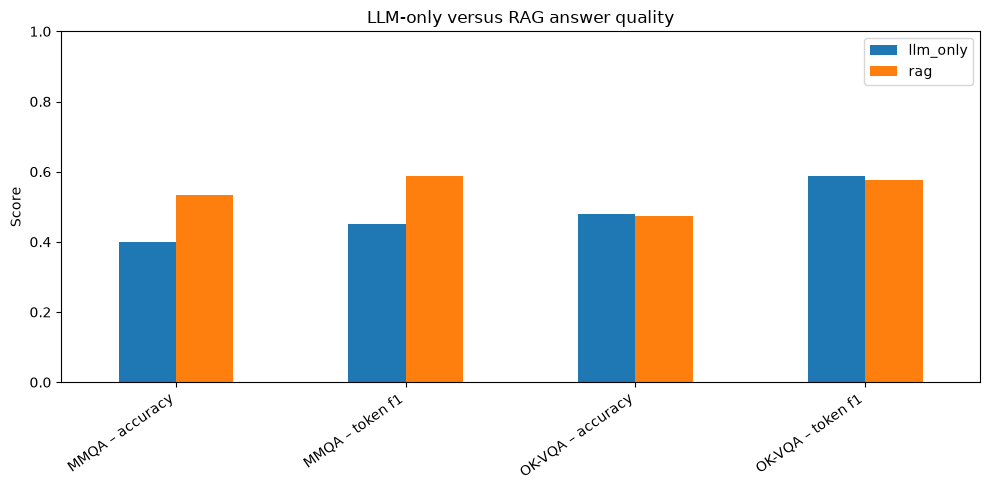

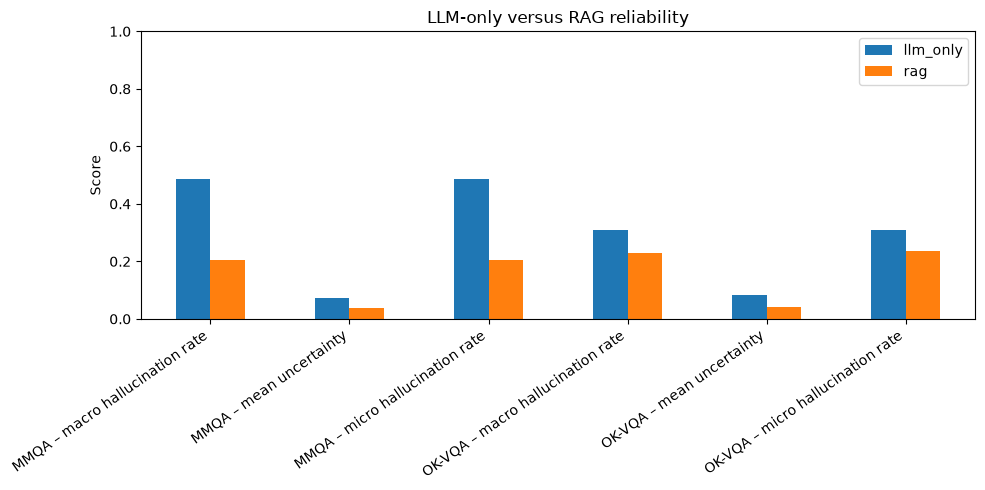

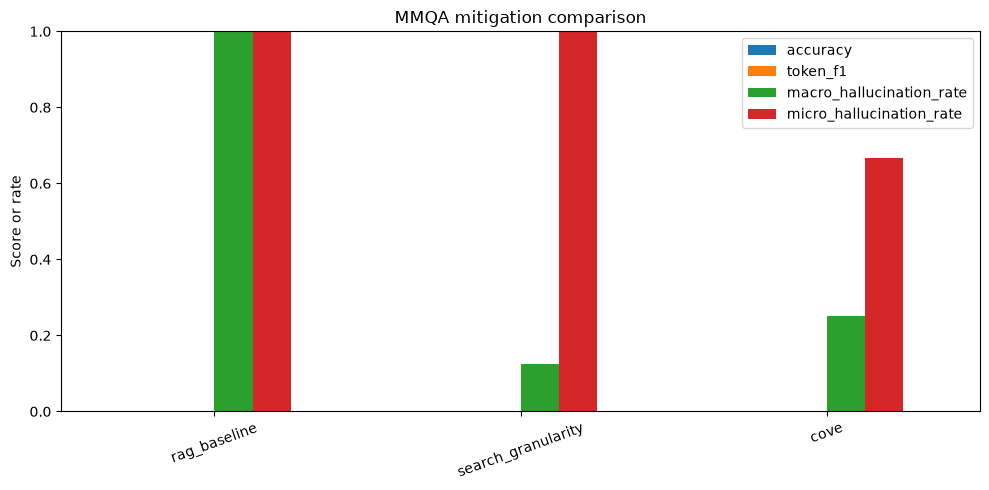

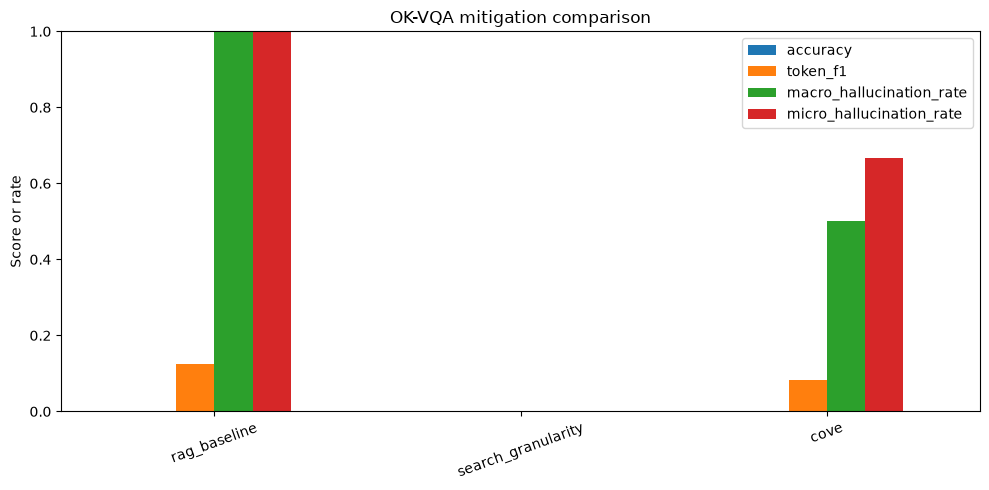

In [304]:
import matplotlib.pyplot as plt


def plot_baseline(metrics, title, filename):
    plot_data = baseline_table[
        baseline_table["metric"].isin(metrics)].copy()

    plot_data["result"] = (plot_data["dataset"] + " – " + plot_data["metric"].str.replace("_", " "))

    ax = plot_data.set_index("result")[["llm_only", "rag"]].plot(kind="bar",figsize=(10, 5),)

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(PROCESSED_DIR / filename, dpi=300)
    plt.show()


plot_baseline(["accuracy", "token_f1"],"LLM-only versus RAG answer quality","answer_quality_comparison.png",)

plot_baseline(["macro_hallucination_rate","micro_hallucination_rate","mean_uncertainty",],"LLM-only versus RAG reliability","reliability_comparison.png",)

for dataset, group in mitigation_comparison.groupby("dataset"):
    ax = group.set_index("technique")[["accuracy","token_f1","macro_hallucination_rate","micro_hallucination_rate",]].plot(kind="bar",figsize=(10, 5),)

    ax.set_title(f"{dataset} mitigation comparison")
    ax.set_xlabel("")
    ax.set_ylabel("Score or rate")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(PROCESSED_DIR / f"{dataset.lower().replace('-', '')}_mitigation_comparison.png",dpi=300,)
    plt.show()